# Reconhecimento de Comandos de Voz na Borda

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/kws_borda_relatorio.ipynb)

**Projeto final — IA025 Deep Learning (2026 S2)** · **Equipe:** Guilherme Pulizzi · Jefferson Abraham · Luciano Pinheiro
· **Repositório:** [gpeuzinCosta/kws-borda](https://github.com/gpeuzinCosta/kws-borda)

**O projeto inteiro, de ponta a ponta, em um notebook.** Reconhecer comandos curtos de voz (*keyword spotting*:
"yes", "stop", "up"...) no próprio dispositivo, com pouca memória e CPU fraca. Colocamos as famílias de redes da
disciplina (MLP, CNN 1D, ResNet, DS-CNN e Atenção), encolhidas, na mesma bancada de testes.
- **Hipótese (a):** dá para encolher essas arquiteturas e ainda reconhecer bem os comandos? (§6, §8 e §9)
- **Hipótese (b):** em redes tão pequenas, o que custa mais: o pré-processamento (MFCC) ou a rede? (§7 e §9)

Este notebook só **chama** funções das pastas do repositório (`dados/`, `modelos/`, `treino/`, `avaliacao/`,
`configs/`; ver o [README](https://github.com/gpeuzinCosta/kws-borda#readme)). Cada modelo é explorado antes no
seu playground (`notebooks/experimentos/`), onde cada passo é escrito e testado à mão.

Como usar:
1. Abra no Colab (Ambiente de execução → Alterar tipo → GPU) e rode tudo.
2. Escolha os modelos em `MODELOS` e ajuste os hiperparâmetros na seção **2. Hiperparâmetros**: tudo fica lá.
3. Partes lentas têm um flag no mesmo lugar: experimentos (§8) e datasets extras (§10). Com `RETREINAR = False`,
   o que já foi treinado é carregado do Drive.
4. Para entender um passo a fundo, siga o link para o playground de cada modelo: [CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) e
   [ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb). Lá estão também todas as configurações testadas; aqui (§8) rodam só as vencedoras.

## 1. Setup

No Colab, o Google Drive é montado e o repositório é clonado (ou atualizado). O `.tar.gz` do GSC, o cache de
MFCC e os treinos ficam em `MyDrive/kws-borda/` e sobrevivem ao fim da sessão; os áudios são extraídos no disco
local (`/content/data`), porque ler 100 mil arquivos do Drive é muito lento.

In [1]:
#@title Setup — rode esta célula primeiro
#Funciona no Colab (clona o repo e usa o Drive) e localmente/VS Code (usa a pasta do repositório).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gpeuzinCosta/kws-borda.git"
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO = Path("/content/kws-borda")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)     #pega a versão mais nova
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)

    #Drive: cache de MFCC, runs e resultados PERSISTEM entre sessões
    #Disco local (/content/data): áudios extraídos, leitura rápida (o Drive é lento para 100 mil arquivos)
    os.environ["KWS_DRIVE"] = "/content/drive/MyDrive/kws-borda"
    os.environ["KWS_DATA"] = "/content/data"
else:
    #Local: sobe a partir da pasta atual até achar a raiz do repositório
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

#A raiz do repo no sys.path deixa importar as pastas: configs, dados, modelos, treino, avaliacao
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
from configs import pastas_projeto, escolher_device

PASTAS = pastas_projeto()
DOWNLOADS = Path(os.environ.get("KWS_DRIVE", REPO)) / "downloads"     #.tar.gz/.zip baixados UMA vez
device = escolher_device()
commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print(f"Colab: {NO_COLAB} | device: {device} | commit do código: {commit}")
print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '—'}")
for nome, p in PASTAS.items():
    print(f"  {nome:10s} -> {p}")

Mounted at /content/drive
Colab: True | device: cuda | commit do código: ff57efb
torch 2.14.1+cu130 | GPU: NVIDIA L4
  dados      -> /content/data
  cache      -> /content/drive/MyDrive/kws-borda/cache
  runs       -> /content/drive/MyDrive/kws-borda/runs
  resultados -> /content/drive/MyDrive/kws-borda/runs


## 2. Hiperparâmetros

Tudo o que controla o notebook fica nesta célula:
- **Experimento:** quais modelos rodar (`MODELOS`), seeds e os flags das partes lentas. Só os modelos de
  `MODELOS` são treinados, avaliados e comparados em **todas** as seções.
- **`hyperparameters`:** o que é comum a todos os modelos (dados, MFCC, treino, avaliação). É o que deixa a
  comparação justa.
- **`hp_modelos`:** só o que muda em cada modelo: a arquitetura e, se for o caso, o próprio MFCC.

MFCC: o padrão é 40 coeficientes × 101 janelas (janela de 30 ms, passo de 10 ms). A entrada 8x menor do artigo
Hello Edge é `n_mfcc=10, janela_ms=40, passo_ms=20, center=False` (10 × 49); a CNN 1D e a ResNet usam essa.

In [2]:
from functools import partial
from configs import montar_hp, rotulo_experimento

#Experimento
MODELOS = ["mlp", "cnn1d", "resnet", "dscnn", "atencao"]     #quais modelos treinar e rodar em TODO o notebook: "mlp", "cnn1d", "resnet", "dscnn", "atencao"
SEEDS = [0, 1, 2]          #rodadas independentes, para média ± desvio
EPOCAS = None              #None = hyperparameters['epocas'] (o TETO; o early stop decide quando parar); um número sobrescreve para todos os modelos
RETREINAR = False          #False: se já existir um treino salvo no Drive para (modelo, seed), carrega em vez de treinar
RODAR_VARREDURAS = True
RODAR_RUIDO = False
RODAR_AUDIOMNIST = False
RODAR_MSWC = False

#Comum a TODOS os modelos: mesmos dados, mesmo MFCC, mesmo loop de treino e mesmas métricas
hyperparameters = {
    #Dados
    'dataset': 'speech_commands_v2',
    'tarefa': 'gsc35',          #'gsc35': as 35 palavras | 'gsc12': 10 comandos + unknown + silence
    'fracao': 1.0,              #fração do TREINO usada (1.0 = tudo). Val e teste são sempre completos
    'sample_rate': 16000,       #o GSC é gravado a 16 kHz: 1 s = 16000 amostras
    'duracao_s': 1.0,

    #MFCC (padrão: 40 coef × 101 janelas)
    'n_mfcc': 40,               #coeficientes por janela
    'janela_ms': 30,            #tamanho de cada fatia de áudio que vira uma coluna
    'passo_ms': 10,             #quanto a janela desliza
    'center': True,             #padding nas bordas, para representar o início e o fim do áudio
    'n_mels': 40,               #bandas Mel (finas nos graves, largas nos agudos, como o ouvido); n_mfcc <= n_mels
    'f_min': 20,                #abaixo de 20 Hz não é fala
    'f_max': 7600,              #um pouco antes de 8 kHz (Nyquist), onde o filtro da gravação distorce
    'normalizacao': 'global',   #'global': média/desvio por coeficiente medidos no treino | 'por_amostra': cada áudio pelas próprias estatísticas
    'spec_augment': True,       #zera faixas de tempo e de coeficientes no treino (regulariza)

    #Treino
    'epocas': 50,               #TETO de épocas: o early stop (paciencia) decide quando parar
    'batch_size': 128,
    'learning_rate': 0.003,
    'weight_decay': 0.01,       #penaliza pesos grandes (L2 desacoplada do AdamW)
    'otimizador': 'adamw',
    'scheduler': 'plateau',     #ReduceLROnPlateau: lr × plateau_fator quando a val estagna ('onecycle' não combina com parada antecipada)
    'plateau_fator': 0.5,
    'plateau_paciencia': 3,     #épocas sem melhora antes de reduzir o lr (< paciencia: o lr cai algumas vezes antes de desistir)
    'paciencia': 5,             #early stop: para após 5 épocas sem melhorar a acc de validação (None = desliga e treina até 'epocas')
    'min_delta': 0.0005,        #melhora mínima (0,05 p.p.) para zerar a contagem da paciência
    'label_smoothing': 0.1,     #evita confiança excessiva
    'num_workers': 0,           #o MFCC já está em memória: processos extras só adicionam overhead

    #Avaliação
    'latencia_repeticoes': 300,
    'latencia_aquecimento': 30,
    'latencia_threads': 1,      #simula um dispositivo restrito (1 núcleo)
    'snrs_db': [20, 10, 5, 0, -5],
    'margem_pp': 2.0,           #critério do projeto: um modelo menor "serve" se ficar até 2 p.p. abaixo do baseline
}

#Só o que MUDA em cada modelo. Qualquer chave de treino também pode mudar por rede,
#ex.: 'atencao': {..., 'epocas': 150, 'paciencia': 15} para deixar o Transformer treinar mais
hp_modelos = {
    #MLP, DS-CNN e Atenção: arquitetura de PARTIDA. O vencedor da varredura (§8.1, §8.4, §8.5) não foi aplicado aqui
    #MLP: versão do Projeto_MLP.ipynb (79,6% val em gsc12 + MFCC hello_edge)
    #vencedor da §8.1: hello_edge + hidden 64 (42.019 params, 75,90% val, −0,36 p.p. do baseline 40x101)
    'mlp': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,     #MFCC hello_edge: 10 × 49
            'hidden': 128, 'n_camadas': 3, 'dropout': 0.1, 'batchnorm': False},

    #Vencedora da varredura (8.2): o MENOR modelo a menos de 2 p.p. do baseline 40x101 + 64 canais
    #24.275 params (23,7 KB int8), 383.280 MACs, acc val 93,07 ± 0,33% (baseline 93,77 ± 0,28%)
    'cnn1d': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,   #MFCC hello_edge: 10 × 49
              'canais': 48},

    #Vencedora da varredura (8.3): o MENOR modelo a menos de 2 p.p. do baseline res8 40x101
    #res15-narrow + hello_edge: 43.640 params (42,6 KB int8), 20.780.585 MACs, acc val 95,11 ± 0,23% (baseline 95,37 ± 0,56%)
    'resnet': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,  #MFCC hello_edge: 10 × 49
               'canais': 19, 'n_blocos': 6, 'pool': None, 'dilatacao': True, 'conv_extra': True},   #res15-narrow

    #DS-CNN-S do Hello Edge: conv 10x4 stride 2 + 4 blocos depthwise/pointwise
    #vencedor da §8.4: hello_edge + 48 canais (15.443 params, 93,57% val, −0,91 p.p. do baseline 40x101)
    'dscnn': {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False,   #MFCC hello_edge: 10 × 49
              'canais': 64, 'n_blocos': 4},

    #KWT: cada janela do MFCC vira um token; MFCC padrão 40 × 101
    #vencedor da §8.5: hello_edge + d_model 32 (41.251 params, 92,80% val, −0,81 p.p. do baseline 40x101)
    'atencao': {'d_model': 64, 'n_camadas': 3, 'n_heads': 1, 'dropout': 0,
                'learning_rate': 0.001},     #Transformers costumam pedir lr menor
}

#config(nome, **extra): o dicionário completo do modelo `nome` (comum + o dele + extra; calcula n_classes e n_frames)
config = partial(montar_hp, hyperparameters, hp_modelos)

print("modelos:", MODELOS, "| seeds:", SEEDS)
print("experimento:", rotulo_experimento(config(MODELOS[0])))

modelos: ['mlp', 'cnn1d', 'resnet', 'dscnn', 'atencao'] | seeds: [0, 1, 2]
experimento: gsc35_10x49_global


In [3]:
#Conferência: o dicionário final de cada modelo (linhas = hiperparâmetro, colunas = modelo)
import pandas as pd

hiperparametros = {nome: config(nome, epocas=EPOCAS) for nome in MODELOS}
pd.DataFrame(hiperparametros).astype(str)

,mlp,cnn1d,resnet,dscnn,atencao
dataset,speech_commands_v2,speech_commands_v2,speech_commands_v2,speech_commands_v2,speech_commands_v2
tarefa,gsc35,gsc35,gsc35,gsc35,gsc35
fracao,1.0,1.0,1.0,1.0,1.0
sample_rate,16000,16000,16000,16000,16000
duracao_s,1.0,1.0,1.0,1.0,1.0
n_mfcc,10,10,10,10,40
janela_ms,40,40,40,40,30
passo_ms,20,20,20,20,10
center,False,False,False,False,True
n_mels,40,40,40,40,40


## 3. Dados — Google Speech Commands v2

**GSC v2** (Warden, 2018): 105.835 áudios de 1 s a 16 kHz, ~2.600 pessoas, 35 palavras. O split é o **oficial,
por locutor**: quem fala no teste nunca aparece no treino.

### 3.1 Download e extração

O `.tar.gz` (2,3 GB) vai para o Drive **uma vez**; a cada sessão ele é extraído no disco local.

In [4]:
import subprocess, sys

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "gsc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
RAIZ_GSC = PASTAS["dados"] / "gsc"

### 3.2 Classes e split

`gsc35`: as 35 palavras. `gsc12`: 10 comandos + `_unknown_` (outras palavras) + `_silence_` (ruído de fundo).
Cada áudio é um vetor de 16.000 números na escala [−1, 1].

{'treino': 84843, 'val': 9981, 'teste': 11005}
arquivo: backward/0165e0e8_nohash_0.wav | formato: (16000,) | palavra: backward


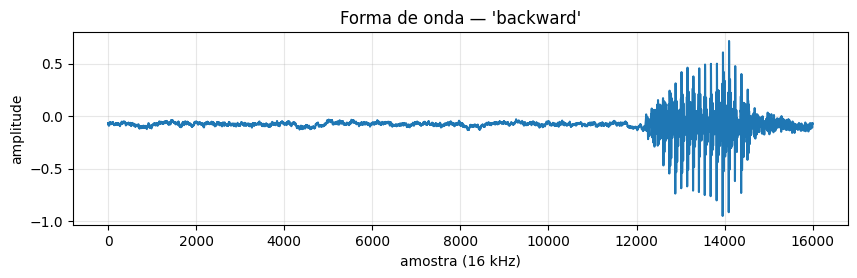

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Audio
from dados import classes_da_tarefa, listar_split, ler_trecho, rotulo

CLASSES = classes_da_tarefa(hyperparameters["tarefa"])
split = listar_split(RAIZ_GSC, hyperparameters["tarefa"])
print({k: len(v) for k, v in split.items()})

exemplo = split["treino"][0]
wav = ler_trecho(RAIZ_GSC, exemplo)
print("arquivo:", exemplo, "| formato:", tuple(wav.shape), "| palavra:", exemplo.split("/")[0])

plt.figure(figsize=(10, 2.5))
plt.plot(wav.numpy()); plt.title(f"Forma de onda — '{exemplo.split('/')[0]}'")
plt.xlabel("amostra (16 kHz)"); plt.ylabel("amplitude"); plt.grid(alpha=0.3); plt.show()
Audio(wav.numpy(), rate=16000)

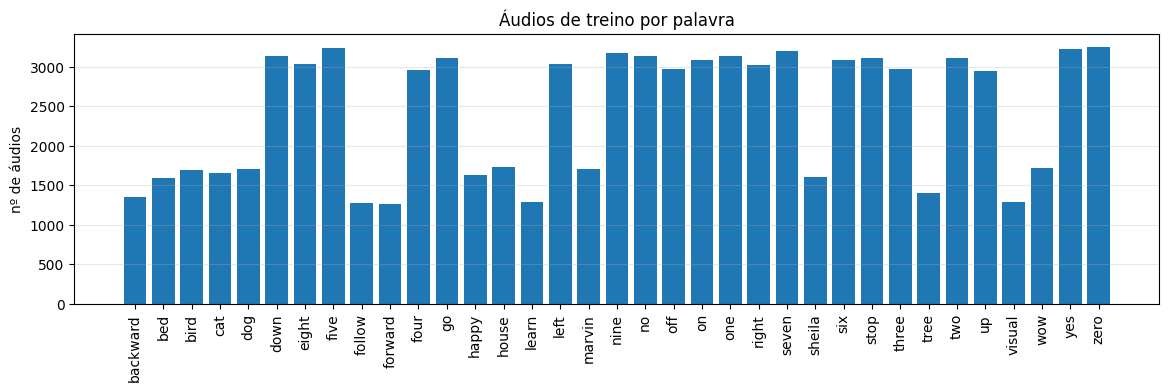

In [6]:
#Distribuição das classes no treino. Na gsc35 o GSC NÃO é balanceado (as palavras auxiliares têm menos
#exemplos); na gsc12 unknown e silence são montados com a quantidade média de um comando
import collections
contagem = collections.Counter(CLASSES[rotulo(rel, hyperparameters["tarefa"])] for rel in split["treino"])

plt.figure(figsize=(14, 3.5))
plt.bar(CLASSES, [contagem[c] for c in CLASSES])
plt.xticks(rotation=90); plt.ylabel("nº de áudios"); plt.title("Áudios de treino por palavra")
plt.grid(axis="y", alpha=0.3); plt.show()

In [7]:
from dados import locutores_em_comum

#Conferência: o split é o OFICIAL, por locutor: ninguém do treino pode aparecer na validação ou no teste
print("total:", sum(len(v) for v in split.values()), "áudios")
print("locutores em comum:", locutores_em_comum(split))      #esperado: 0 e 0

total: 105829 áudios
locutores em comum: {'treino_e_teste': 0, 'treino_e_val': 0}


### 3.3 MFCC

Cada áudio de 1 s vira uma matriz `(n_mfcc, n_frames)`: para cada janela de tempo, coeficientes que resumem o
espectro na escala Mel. O MFCC de todo o dataset é calculado **uma vez** e salvo em cache no Drive.

| MFCC | Coeficientes | Janela / passo | Entrada | Quem usa |
|---|---|---|---|---|
| padrão | 40 | 30 ms / 10 ms | 40 × 101 | Atenção; o *baseline* de todas as varreduras da §8 |
| `hello_edge` | 10 | 40 ms / 20 ms, sem padding | 10 × 49 (8x menor) | MLP, CNN 1D, ResNet e DS-CNN |

O MFCC é um `nn.Module` (`dados/mfcc.py`), então o seu tempo é medido como o de uma rede na §7.

MFCC: (10, 49) (coeficientes × janelas)


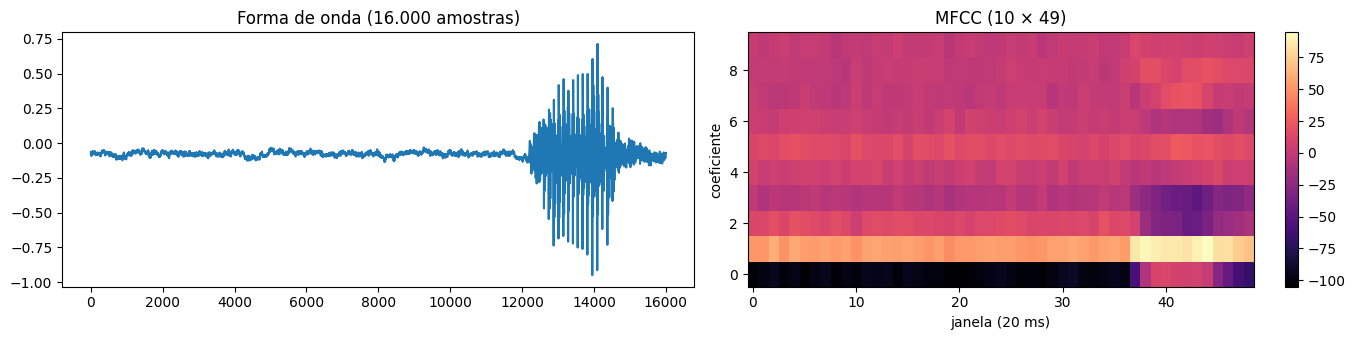

In [8]:
from dados import ExtratorMFCC

hp_base = config(MODELOS[0])      #o MFCC do primeiro modelo de MODELOS (cada modelo pode ter o seu)
extrator = ExtratorMFCC.de_hparams(hp_base)

mfcc = extrator(wav)[0]
print("MFCC:", tuple(mfcc.shape), "(coeficientes × janelas)")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(wav.numpy()); axes[0].set_title("Forma de onda (16.000 amostras)")
im = axes[1].imshow(mfcc.numpy(), aspect="auto", origin="lower", cmap="magma")
axes[1].set_title(f"MFCC ({mfcc.shape[0]} × {mfcc.shape[1]})"); axes[1].set_xlabel(f"janela ({hp_base['passo_ms']} ms)"); axes[1].set_ylabel("coeficiente")
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

In [9]:
%%time
#Calcula (ou carrega do cache no Drive) o MFCC de treino/val/teste — primeira vez: ~10 min
from dados import criar_dataloaders
from treino.varredura import carregar_dados

#carregar_dados guarda UM MFCC na memória e só recarrega quando a configuração muda (cada modelo pode ter o seu)
dados = carregar_dados(hp_base, RAIZ_GSC, PASTAS["cache"])
for k, (X, y) in dados.items():
    print(f"{k:6s} | X {tuple(X.shape)} | y {tuple(y.shape)}")

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}
treino | X (84843, 10, 49) | y (84843,)
val    | X (9981, 10, 49) | y (9981,)
teste  | X (11005, 10, 49) | y (11005,)
CPU times: user 2.87 s, sys: 290 ms, total: 3.16 s
Wall time: 19.2 s


### 3.4 Normalização, SpecAugment e DataLoaders

- **Normalização global:** média e desvio por coeficiente, medidos **só no treino** (medir na val/teste seria
  vazamento).
- **SpecAugment:** zera uma faixa de janelas e uma de coeficientes, sorteadas a cada batch, só no treino. Roda no
  **batch inteiro, na GPU** (`spec_augment_batch`), e cada áudio sorteia as próprias faixas.
- **DataLoader:** entrega o batch inteiro de uma vez (uma fatia do tensor), sem montar áudio por áudio.

Cada passo é conferido em detalhe no [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 3.4).

In [10]:
#Conferência: o batch que vai entrar na rede: formato e normalização (média ~0, desvio ~1)
#Com normalização por amostra, MEDIA e DESVIO são None (nada a guardar)
loaders, (MEDIA, DESVIO) = criar_dataloaders(hp_base, dados)
xb, yb = next(iter(loaders["treino"]))
print("batch:", tuple(xb.shape), "| média:", round(xb.mean().item(), 3), "| desvio:", round(xb.std().item(), 3))
print("palavras:", [CLASSES[i] for i in yb[:8].tolist()])

batch: (128, 10, 49) | média: -0.016 | desvio: 1.023
palavras: ['marvin', 'five', 'eight', 'down', 'two', 'up', 'two', 'sheila']


In [11]:
from dados import normalizar

#Conferência da normalização. Com normalização por amostra, MEDIA e DESVIO são None (cada áudio usa as próprias estatísticas)
X_treino_norm = loaders["treino"].dataset.X                 #o DatasetMFCC já guarda o MFCC normalizado
X_val_norm = normalizar(dados["val"][0], MEDIA, DESVIO)
print("treino | média dos 5 primeiros coef:", X_treino_norm.mean(dim=(0, 2))[:5])   #esperado: ~0
print("treino | desvio dos 5 primeiros coef:", X_treino_norm.std(dim=(0, 2))[:5])   #esperado: ~1
print("val    | média dos 5 primeiros coef:", X_val_norm.mean(dim=(0, 2))[:5])      #perto de 0, mas não exato
print("val    | desvio dos 5 primeiros coef:", X_val_norm.std(dim=(0, 2))[:5])      #perto de 1, mas não exato
del X_val_norm

treino | média dos 5 primeiros coef: tensor([-5.0033e-06, -5.1138e-07,  3.2912e-07, -2.4944e-08,  1.0956e-06])
treino | desvio dos 5 primeiros coef: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
val    | média dos 5 primeiros coef: tensor([-0.0271,  0.0357, -0.0014, -0.0108,  0.0164])
val    | desvio dos 5 primeiros coef: tensor([1.0047, 1.0018, 1.0106, 1.0181, 0.9997])


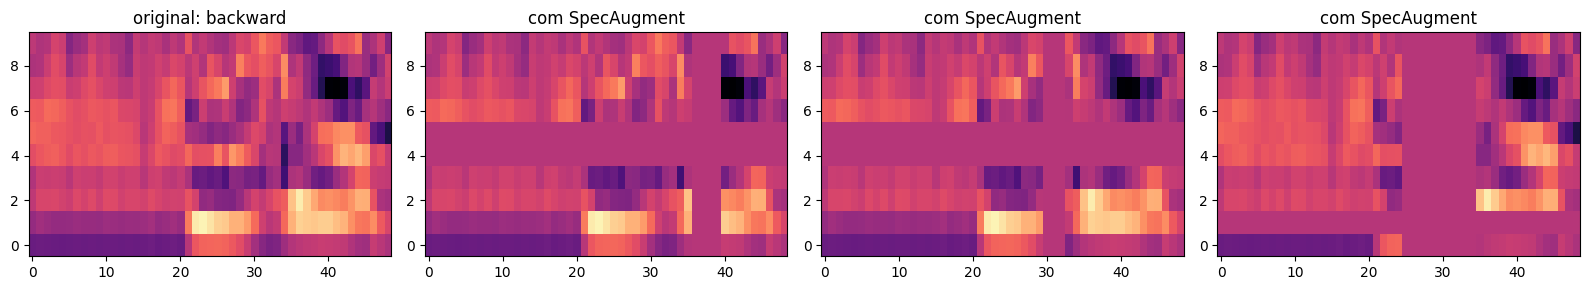

fração de zeros | batch com aumento: 0.192 | sem aumento: 0.0


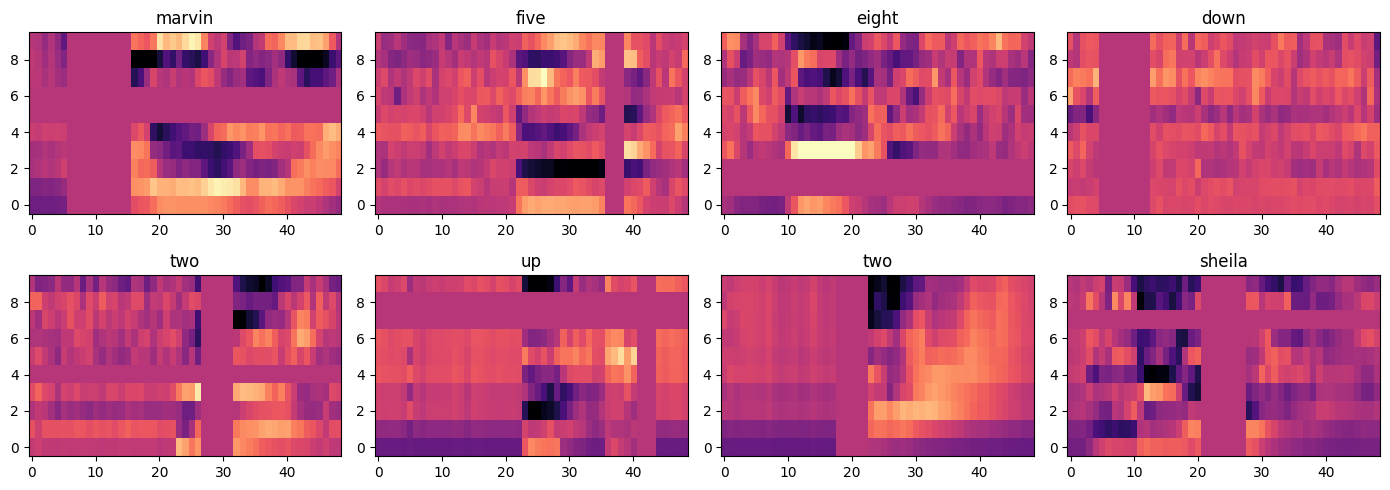

In [12]:
from dados import spec_augment_batch
from avaliacao.graficos import plot_spec_augment, plot_batch

#Um áudio da validação: o original e 3 sorteios do SpecAugment
plot_spec_augment(loaders["val"].dataset.X[0], CLASSES[loaders["val"].dataset.y[0]])

#No treino, o aumento no batch inteiro, como o treinar_uma_epoca faz
xb_aum = spec_augment_batch(xb.to(device)).cpu()
print("fração de zeros | batch com aumento:", round((xb_aum == 0).float().mean().item(), 3),
      "| sem aumento:", round((xb == 0).float().mean().item(), 3))      #esperado: ~0.13 e 0
plot_batch(xb_aum, yb, CLASSES)

## 4. Modelos

As 5 famílias da disciplina, em versões **pequenas**, uma por arquivo em `modelos/`. A tabela abaixo vem do
registro de modelos: um modelo novo aparece sozinho. Da §5 à §7 e na §9 cada família usa a configuração de
`hp_modelos` (§2). Na CNN 1D e na ResNet ela é a vencedora da varredura. No MLP, na DS-CNN e na Atenção ainda é a
arquitetura de partida: o vencedor da §8 de cada uma aparece na última coluna e não foi aplicado.

| Família | Ideia | Arquivo | Situação |
|---|---|---|---|
| MLP | achata o MFCC e passa por camadas densas; sem noção de tempo. É o *baseline* | `modelos/mlp.py` | pronto: 3 camadas de 128 + `hello_edge` ([notebook](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/Projeto_MLP.ipynb)); a §8.1 escolheu 64 neurônios |
| CNN 1D | os coeficientes viram canais e a convolução desliza no tempo: 4 blocos Conv1d k=3 + BN + ReLU, média global, `head` | `modelos/cnn1d.py` | pronto: `hello_edge` + 48 canais, vencedora da §8.2 ([playground](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb)) |
| ResNet | Conv2d com atalhos residuais `x + F(x)` (famílias res8/res15/res26, Tang & Lin 2018) | `modelos/resnet.py` | pronto: res15-narrow + `hello_edge`, vencedora da §8.3 ([playground](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb)) |
| DS-CNN | convolução separável em profundidade (Hello Edge): ~8–9x menos parâmetros | `modelos/dscnn.py` | pronto: DS-CNN-S (64 canais, 4 blocos) + `hello_edge`; a §8.4 escolheu 48 canais |
| Atenção (KWT) | cada janela do MFCC vira um token; autoatenção + token `[CLS]` | `modelos/atencao.py` | pronto: KWT com 3 camadas, 1 cabeça, d_model 64, entrada 40 × 101; a §8.5 escolheu `hello_edge` + d_model 32 |

In [13]:
import pandas as pd
from modelos import listar_modelos

pd.DataFrame(listar_modelos())

,nome,familia,referencia,implementado
0,mlp,MLP,Bengio et al. 2003 (exercício da disciplina),True
1,cnn1d,CNN 1D,Choi et al. 2019 (TC-ResNet) / exercício de CNNs,True
2,resnet,ResNet,He et al. 2016; Tang & Lin 2018 (res8),True
3,dscnn,DS-CNN,Zhang et al. 2017 — Hello Edge (arXiv:1711.07128),True
4,atencao,Atenção,Berg et al. 2021 — KWT (arXiv:2104.00769),True


### 4.1 Contrato e custo

**Contrato**:
- entrada `x`: `(B, n_mfcc, n_frames)`, o MFCC normalizado (cada modelo com o seu);
- saída: logits `(B, n_classes)`;
- a última camada se chama `self.head`;
- o `__init__` recebe `n_classes, n_mfcc, n_frames` e, depois, os hiperparâmetros da arquitetura (`hp_modelos`).

**Custo** (depende só da arquitetura, então dá para medir antes de treinar):
- **Parâmetros:** tamanho em memória = parâmetros × 4 bytes (fp32) ou × 1 byte (int8).
- **MACs:** multiplicações + somas para classificar **um** áudio (1 MAC = 2 FLOPs).

In [14]:
from avaliacao import custo
from modelos import criar_modelo, esta_implementado

linhas = []
for nome in MODELOS:
    if not esta_implementado(nome):
        print(f"[pulando] {nome}: ainda não implementado")
        continue
    hp = config(nome)
    linhas.append(dict(modelo=nome, entrada=f"{hp['n_mfcc']}x{hp['n_frames']}", **custo(criar_modelo(nome, hp))))

tabela_custo = pd.DataFrame(linhas)
tabela_custo.style.format({"params": "{:,}", "kb_fp32": "{:.0f}", "kb_int8": "{:.0f}", "macs": "{:,}"})

/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(


,modelo,entrada,params,kb_fp32,kb_int8,macs
0,mlp,10x49,"100,387",392,98,"99,968"
1,cnn1d,10x49,"24,275",95,24,"383,280"
2,resnet,10x49,"43,640",170,43,"20,780,585"
3,dscnn,10x49,"24,675",96,24,"2,658,240"
4,atencao,40x101,"161,443",631,158,"15,301,312"


In [15]:
#Conferência do contrato de cada modelo com a SUA entrada (o MFCC do seu config):
#(B, n_mfcc, n_frames) -> (B, n_classes), com a última camada chamada `head`
for nome in MODELOS:
    if not esta_implementado(nome):
        continue
    hp = config(nome)
    modelo = criar_modelo(nome, hp).eval()
    saida = modelo(torch.randn(4, hp["n_mfcc"], hp["n_frames"]))
    print(f"{nome:8s} | entrada (4, {hp['n_mfcc']}, {hp['n_frames']}) -> saída {tuple(saida.shape)} | "
          f"tem head: {hasattr(modelo, 'head')}")      #esperado: (4, n_classes) e True

mlp      | entrada (4, 10, 49) -> saída (4, 35) | tem head: True
cnn1d    | entrada (4, 10, 49) -> saída (4, 35) | tem head: True
resnet   | entrada (4, 10, 49) -> saída (4, 35) | tem head: True
dscnn    | entrada (4, 10, 49) -> saída (4, 35) | tem head: True
atencao  | entrada (4, 40, 101) -> saída (4, 35) | tem head: True


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(


## 5. Treino

**O mesmo loop para todas as redes** (`treino/loop.py`), com os valores de `hyperparameters`:

| Item | Valor |
|---|---|
| Otimizador | AdamW, lr 3e-3, weight decay 1e-2 |
| Agendador | ReduceLROnPlateau: lr × 0,5 após 3 épocas sem melhora na validação |
| Early stop | até 50 épocas; para após 5 épocas sem melhorar a acurácia de validação (`paciencia`, melhora mínima 0,05 p.p.) |
| Perda | entropia cruzada com *label smoothing* 0,1 |
| Aumento | SpecAugment no batch inteiro, na GPU |
| Seleção | pesos da **melhor época na validação** |
| Repetições | `SEEDS` (média ± desvio) |

Cada treino fica salvo no Drive (`runs/`). As funções de época vieram do [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 5).

**O que o early stop mostrou** (coluna `epocas_treinadas` do resumo abaixo): quase todos os treinos param entre
as épocas 20 e 46, ou seja, as 20 épocas fixas de antes cortavam várias redes cedo demais.

**Limitações deste regime:**
- **Teto:** alguns treinos chegaram às 50 épocas ainda melhorando. No §5 foram os MLP das seeds 1 e 2; na §8,
  várias configurações pequenas. Para elas o número é um limite inferior.
- **Paciência curta:** 5 épocas dão espaço para uma só redução do lr (`plateau_paciencia` = 3) antes de desistir,
  e isso aumenta a variação entre treinos. A mesma CNN 1D com a seed 0 parou na época 20 com 91,6% de
  validação aqui, e na §8.2 foi até a época 37, com 93,2%. A GPU não é determinística, então treinos com a mesma
  seed não saem idênticos, e a paciência curta amplia essa diferença.

Teto e paciência maiores (ex.: 100 e 10) são o próximo passo.

In [16]:
from treino import treinar, carregar_run, mesma_politica
from treino.varredura import carregar_dados
from dados import ExtratorMFCC
from avaliacao.graficos import curvas_treino

treinados = {}   #{nome: [(seed, model, hist), ...]}
entradas = {}    #{nome: dict(extrator, media, desvio)}: a entrada de cada modelo (o MFCC pode mudar por modelo)

for nome in MODELOS:
    if not esta_implementado(nome):
        print(f"[pulando] {nome}: ainda não implementado")
        continue
    hp = config(nome, epocas=EPOCAS)
    #MFCC e batch_size do próprio modelo (hp_modelos, §2)
    loaders_m, (media, desvio) = criar_dataloaders(hp, carregar_dados(hp, RAIZ_GSC, PASTAS["cache"]))
    entradas[nome] = dict(extrator=ExtratorMFCC.de_hparams(hp), media=media, desvio=desvio)
    treinados[nome] = []
    for seed in SEEDS:
        print(f"\n===== {nome} | seed {seed} =====")
        run = None if RETREINAR else carregar_run(PASTAS["runs"], hp, seed)
        if run is not None and not mesma_politica(run[2], hp):    #treinado com outro teto/scheduler/early stop
            run = None
        model = criar_modelo(nome, hp)
        if run is not None:
            model.load_state_dict(run[0]); hist = run[1]
            print(f"carregado do Drive: {hist.get('pasta')} | melhor acc val {max(hist['acc'])*100:.2f}%")
        else:
            model, hist = treinar(model, loaders_m, hp, seed=seed, pasta_runs=PASTAS["runs"], device=device)
        treinados[nome].append((seed, model.to(device), hist))


===== mlp | seed 0 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/mlp_gsc35_10x49_global_s0_20261111-130028 | melhor acc val 77.57%

===== mlp | seed 1 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/mlp_gsc35_10x49_global_s1_20261111-130222 | melhor acc val 81.75%

===== mlp | seed 2 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/mlp_gsc35_10x49_global_s2_20261111-130416 | melhor acc val 82.56%

===== cnn1d | seed 0 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s0_20261111-130519 | melhor acc val 91.61%

===== cnn1d | seed 1 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s1_20261111-130733 | melhor acc val 93.08%

===== cnn1d | seed 2 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/cnn1d_gsc35_10x49_global_s2_20261111-130845 | melhor acc val 92.68%

===== resnet | seed 0 =====
carregado do Drive: /content/drive/MyDrive/kws-borda/runs/r

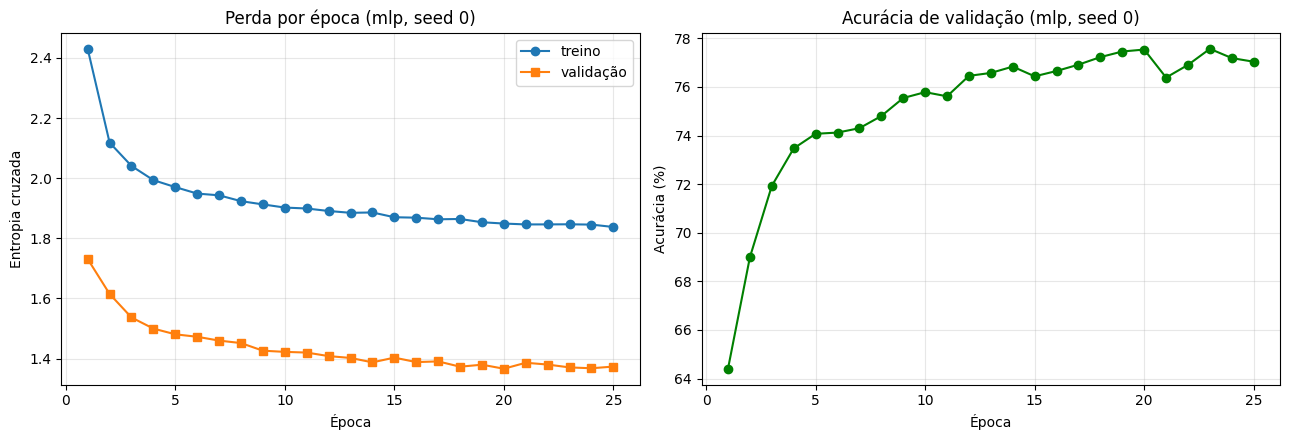

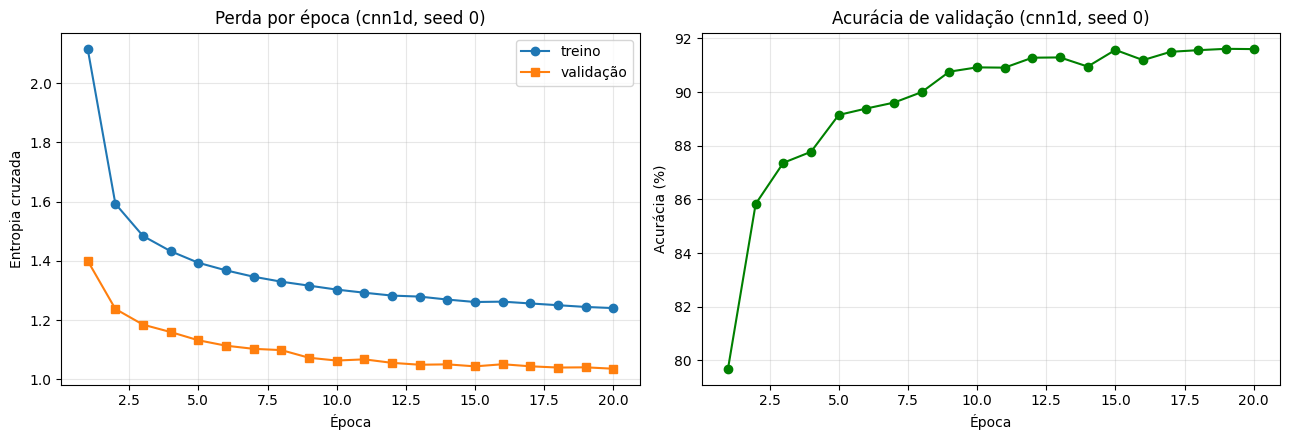

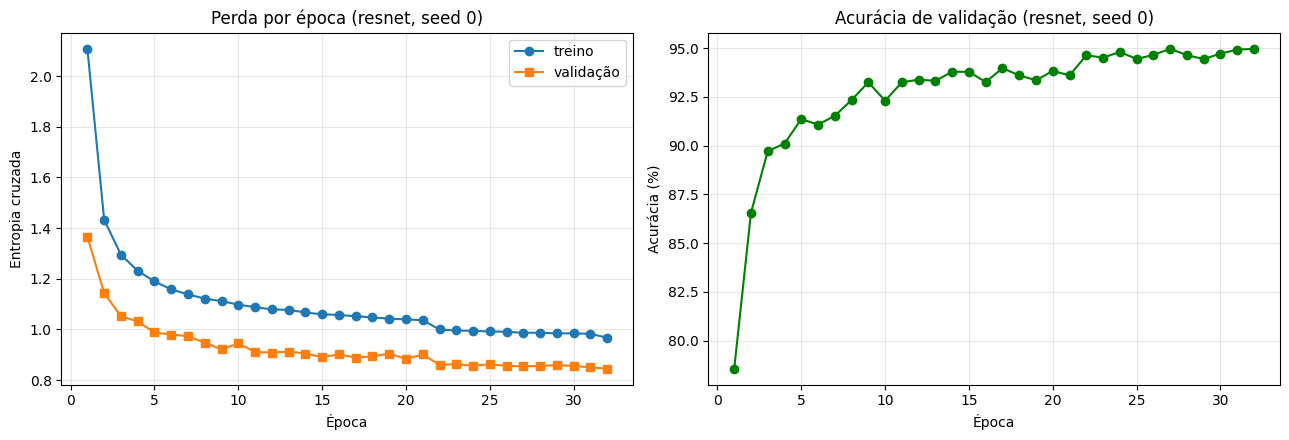

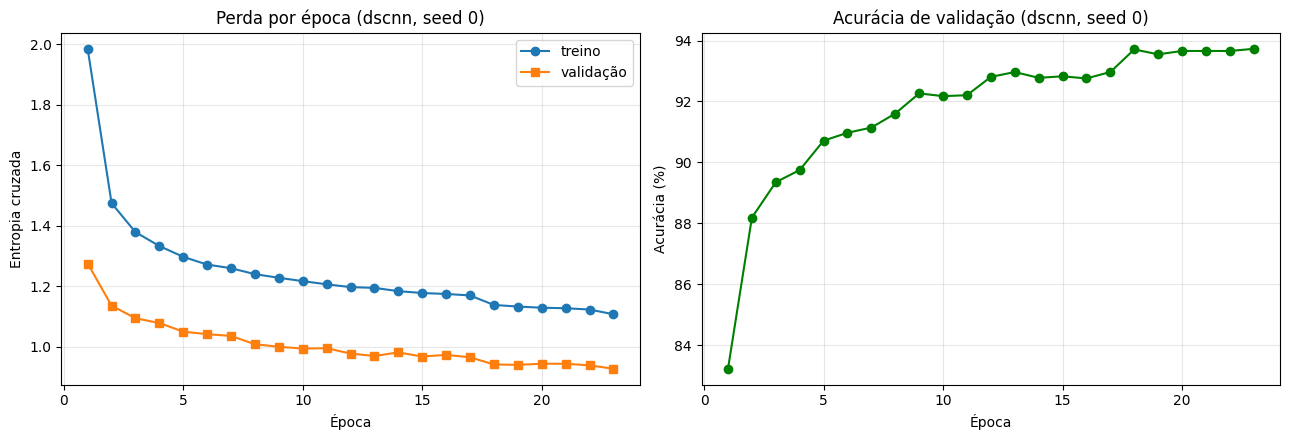

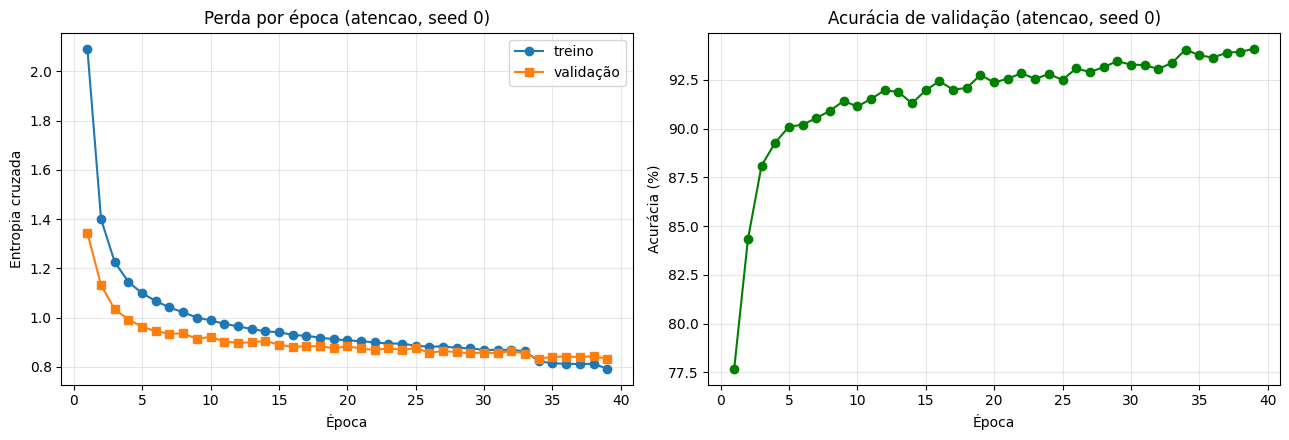

In [17]:
#Curvas de treino da primeira seed de cada modelo
for nome, rodadas in treinados.items():
    curvas_treino(rodadas[0][2], titulo=f"({nome}, seed {rodadas[0][0]})")

In [18]:
#Resumo do treino: uma linha por (modelo, seed). epocas_treinadas < teto = parou no early stop. Gap = perda de validação - perda de treino na última época
pd.DataFrame([dict(modelo=nome, seed=seed,
                   melhor_acc_val=hist.get("melhor_acc", max(hist["acc"])),
                   melhor_epoca=hist.get("melhor_epoca"), epocas_treinadas=hist.get("epocas_treinadas", len(hist["acc"])),
                   acc_final=hist.get("acc_final", hist["acc"][-1]),
                   gap=hist.get("gap"), tempo_min=hist.get("tempo_min"))
              for nome, rodadas in treinados.items() for seed, model, hist in rodadas]).round(4)

,modelo,seed,melhor_acc_val,melhor_epoca,epocas_treinadas,acc_final,gap,tempo_min
0,mlp,0,0.7757,23,25,0.7704,-0.4643,0.9441
1,mlp,1,0.8175,49,50,0.8160,-0.4253,1.8515
2,mlp,2,0.8256,50,50,0.8256,-0.4167,1.8557
3,cnn1d,0,0.9161,19,20,0.9160,-0.2047,0.9896
4,cnn1d,1,0.9308,41,46,0.9300,-0.1701,2.2093
5,cnn1d,2,0.9268,19,24,0.9261,-0.1956,1.1448
6,resnet,0,0.9497,27,32,0.9497,-0.1226,3.8377
7,resnet,1,0.9497,30,34,0.9487,-0.1292,4.0786
8,resnet,2,0.9529,37,39,0.9509,-0.1114,4.6912
9,dscnn,0,0.9373,23,23,0.9373,-0.1802,1.5681


## 6. Avaliação no teste

Teste = 11.005 áudios de locutores nunca vistos, média ± desvio entre as seeds.
- **Acurácia:** fração de acertos.
- **F1 macro:** média do F1 de cada classe; pesa todas as palavras igualmente.
- **Matriz de confusão:** linha = palavra verdadeira, coluna = prevista (normalizada por linha). Esperamos erros
  **fonéticos** (*tree* ↔ *three*, *go* ↔ *no*).

Cada rodada também é registrada em `runs/resultados.csv` no Drive.

In [19]:
from treino import prever
from avaliacao import acuracia, f1_macro, registrar
from avaliacao.resultados import consolidar
from treino.varredura import carregar_dados

linhas, predicoes = [], {}
for nome, rodadas in treinados.items():
    hp = config(nome)
    loaders_m, _ = criar_dataloaders(hp, carregar_dados(hp, RAIZ_GSC, PASTAS["cache"]))
    for seed, model, hist in rodadas:
        y_pred, y_true = prever(model, loaders_m["teste"])
        predicoes[(nome, seed)] = (y_pred, y_true)
        r = dict(acc=acuracia(y_pred, y_true), f1=f1_macro(y_pred, y_true))
        registrar(PASTAS["resultados"] / "resultados.csv", nome, seed, experimento=rotulo_experimento(hp),
                  commit=commit, **r)
        linhas.append(dict(modelo=nome, seed=seed, dataset="gsc_v2", **r))

resultados_gsc = consolidar(pd.DataFrame(linhas))
if len(resultados_gsc):
    resultados_gsc = resultados_gsc.merge(tabela_custo, on="modelo")
resultados_gsc

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}
>>> registrado: mlp (seed 0, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.7468 | f1=0.7335
>>> registrado: mlp (seed 1, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.7854 | f1=0.7766
>>> registrado: mlp (seed 2, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.7922 | f1=0.7834
>>> registrado: cnn1d (seed 0, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.9094 | f1=0.9019
>>> registrado: cnn1d (seed 1, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.9229 | f1=0.9167
>>> registrado: cnn1d (seed 2, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.9137 | f1=0.9057
>>> registrado: resnet (seed 0, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.9378 | f1=0.9332
>>> registrado: resnet (seed 1, gsc_v2) | experimento=gsc35_10x49_global | commit=ff57efb | acc=0.9428 | f1=0.9383
>>> registrado: resnet (seed 2, gsc_v2)

,modelo,dataset,acc_mean,acc_std,acc_count,f1_mean,f1_std,f1_count,entrada,params,kb_fp32,kb_int8,macs
0,atencao,gsc_v2,0.930638,0.006178,3,0.924268,0.005986,3,40x101,161443,630.636719,157.659180,15301312
1,cnn1d,gsc_v2,0.915342,0.006922,3,0.908074,0.007664,3,10x49,24275,94.824219,23.706055,383280
2,dscnn,gsc_v2,0.933303,0.001838,3,0.928026,0.001817,3,10x49,24675,96.386719,24.096680,2658240
3,mlp,gsc_v2,0.774769,0.024502,3,0.764521,0.027082,3,10x49,100387,392.136719,98.034180,99968
4,resnet,gsc_v2,0.942148,0.004032,3,0.937685,0.004211,3,10x49,43640,170.468750,42.617188,20780585


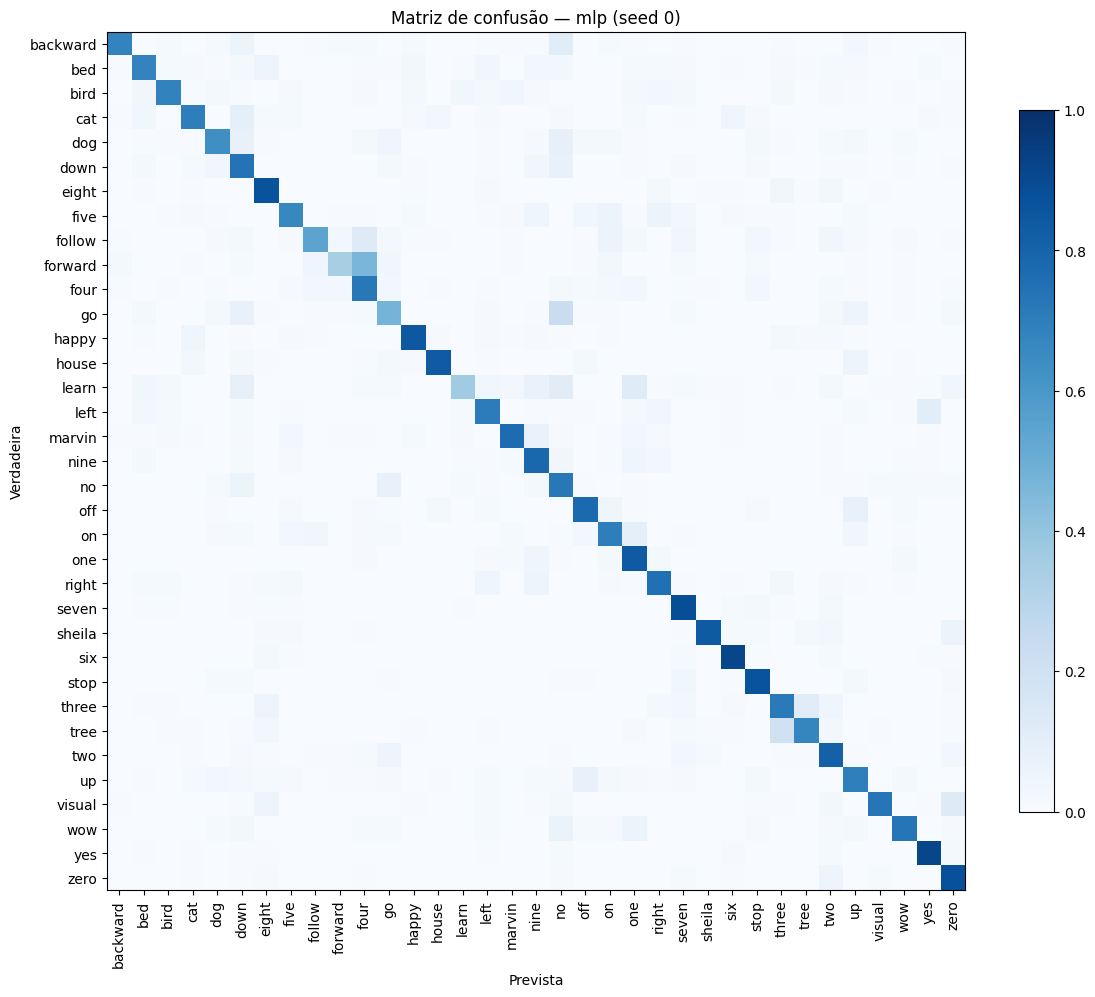

mlp: as 10 confusões mais frequentes


,verdadeira,prevista,fração
0,forward,four,0.464516
1,go,no,0.228856
2,tree,three,0.202073
3,follow,four,0.122093
4,visual,zero,0.121212
5,learn,one,0.118012
6,three,tree,0.116049
7,backward,no,0.115152
8,learn,no,0.111801
9,left,yes,0.106796


mlp: desempenho por palavra


,precisao,revocacao,f1,exemplos
forward,0.639,0.342,0.445,155
learn,0.663,0.366,0.472,161
go,0.628,0.475,0.541,402
no,0.541,0.721,0.618,405
follow,0.712,0.547,0.618,172
dog,0.673,0.636,0.654,220
bed,0.639,0.676,0.657,207
tree,0.668,0.668,0.668,193
down,0.632,0.741,0.683,406
four,0.668,0.720,0.693,400


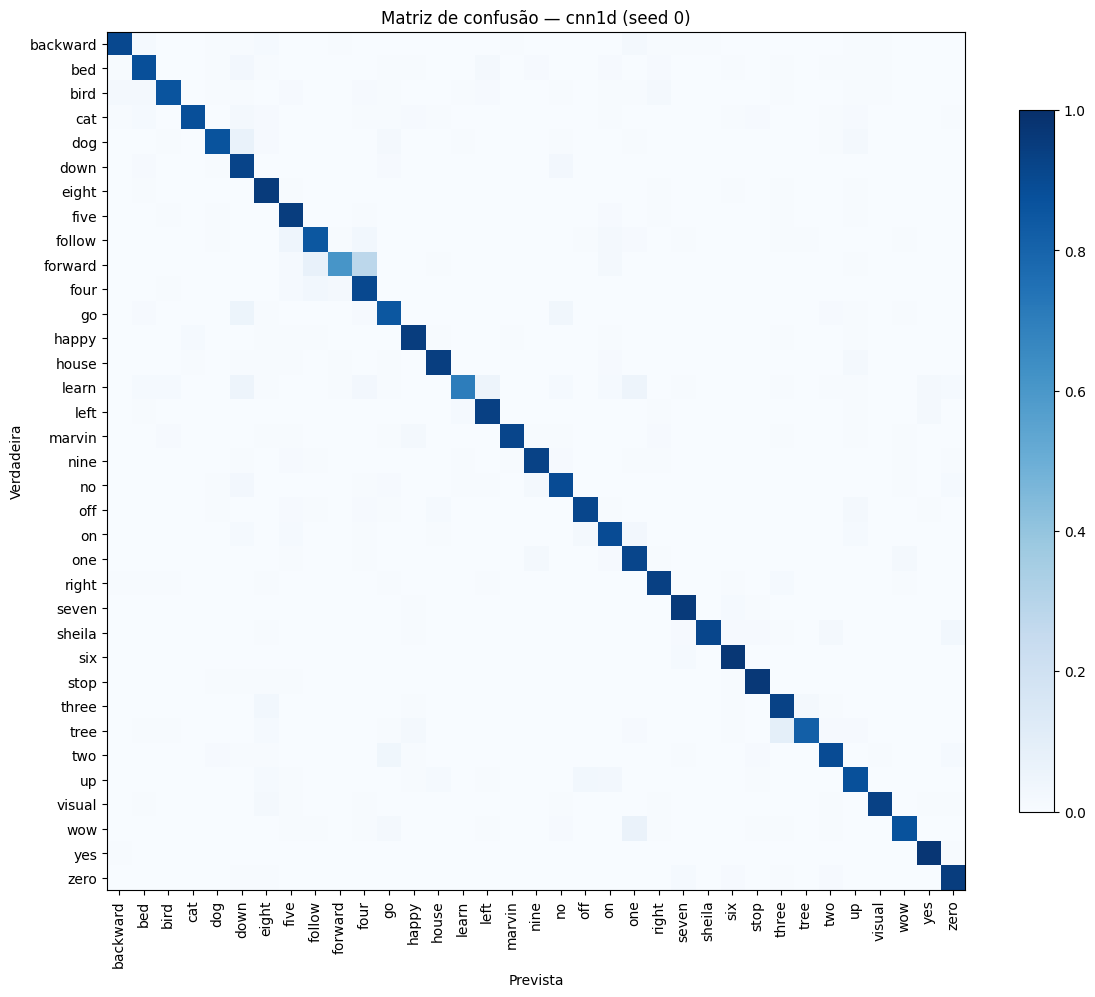

cnn1d: as 10 confusões mais frequentes


,verdadeira,prevista,fração
0,forward,four,0.277419
1,tree,three,0.093264
2,forward,follow,0.070968
3,dog,down,0.068182
4,wow,one,0.063107
5,go,down,0.052239
6,learn,one,0.049689
7,learn,down,0.049689
8,learn,left,0.049689
9,follow,five,0.046512


cnn1d: desempenho por palavra


,precisao,revocacao,f1,exemplos
forward,0.887,0.606,0.720,155
learn,0.904,0.702,0.790,161
follow,0.825,0.849,0.837,172
bed,0.839,0.879,0.858,207
four,0.828,0.902,0.864,400
go,0.881,0.848,0.864,402
down,0.817,0.921,0.866,406
up,0.879,0.875,0.877,425
tree,0.946,0.819,0.878,193
dog,0.900,0.864,0.882,220


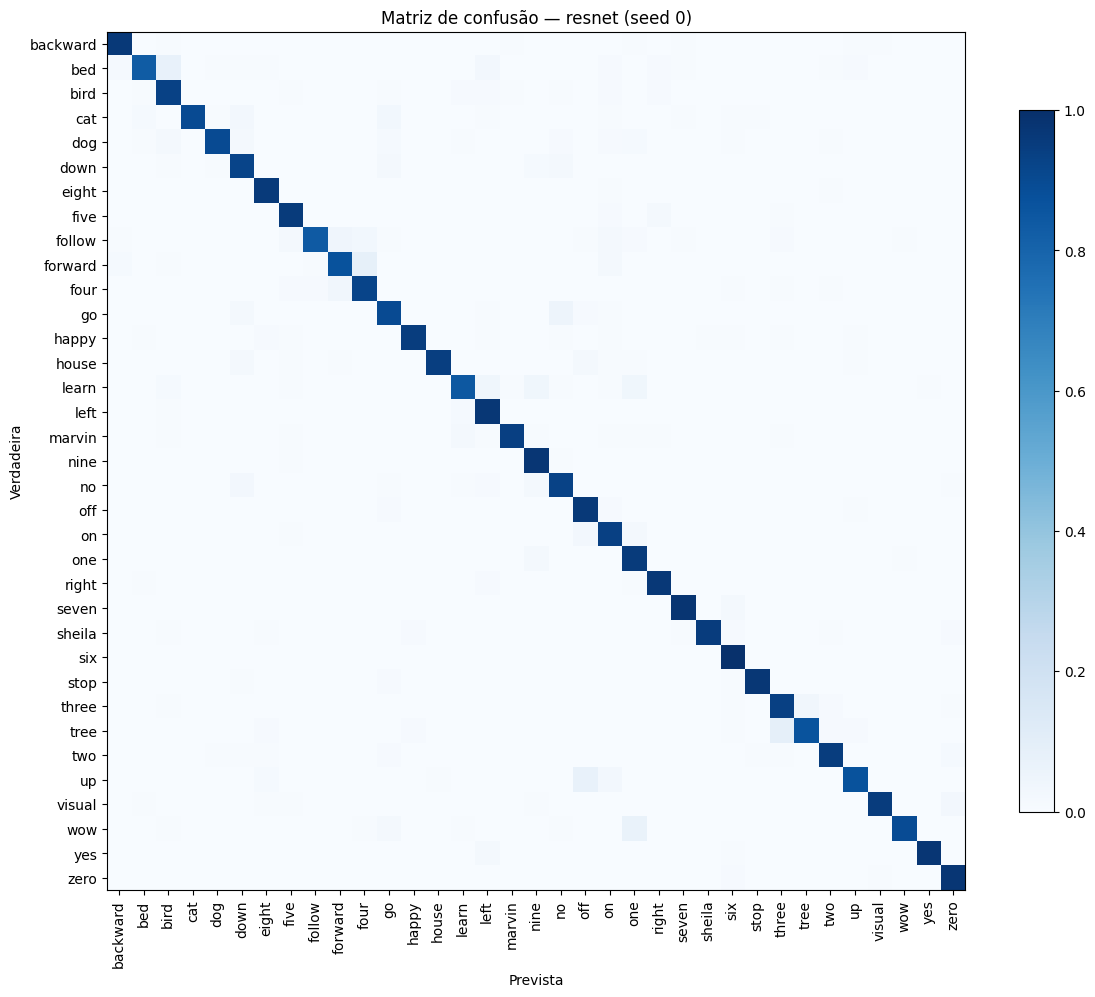

resnet: as 10 confusões mais frequentes


,verdadeira,prevista,fração
0,tree,three,0.088083
1,forward,four,0.083871
2,bed,bird,0.077295
3,up,off,0.072941
4,wow,one,0.067961
5,go,no,0.049751
6,follow,forward,0.040698
7,learn,nine,0.037267
8,learn,left,0.037267
9,learn,one,0.037267


resnet: desempenho por palavra


,precisao,revocacao,f1,exemplos
learn,0.872,0.845,0.858,161
forward,0.849,0.871,0.860,155
bird,0.800,0.930,0.860,185
bed,0.930,0.831,0.878,207
follow,0.954,0.837,0.892,172
tree,0.928,0.865,0.895,193
go,0.902,0.898,0.900,402
down,0.906,0.921,0.913,406
up,0.964,0.871,0.915,425
on,0.898,0.937,0.917,396


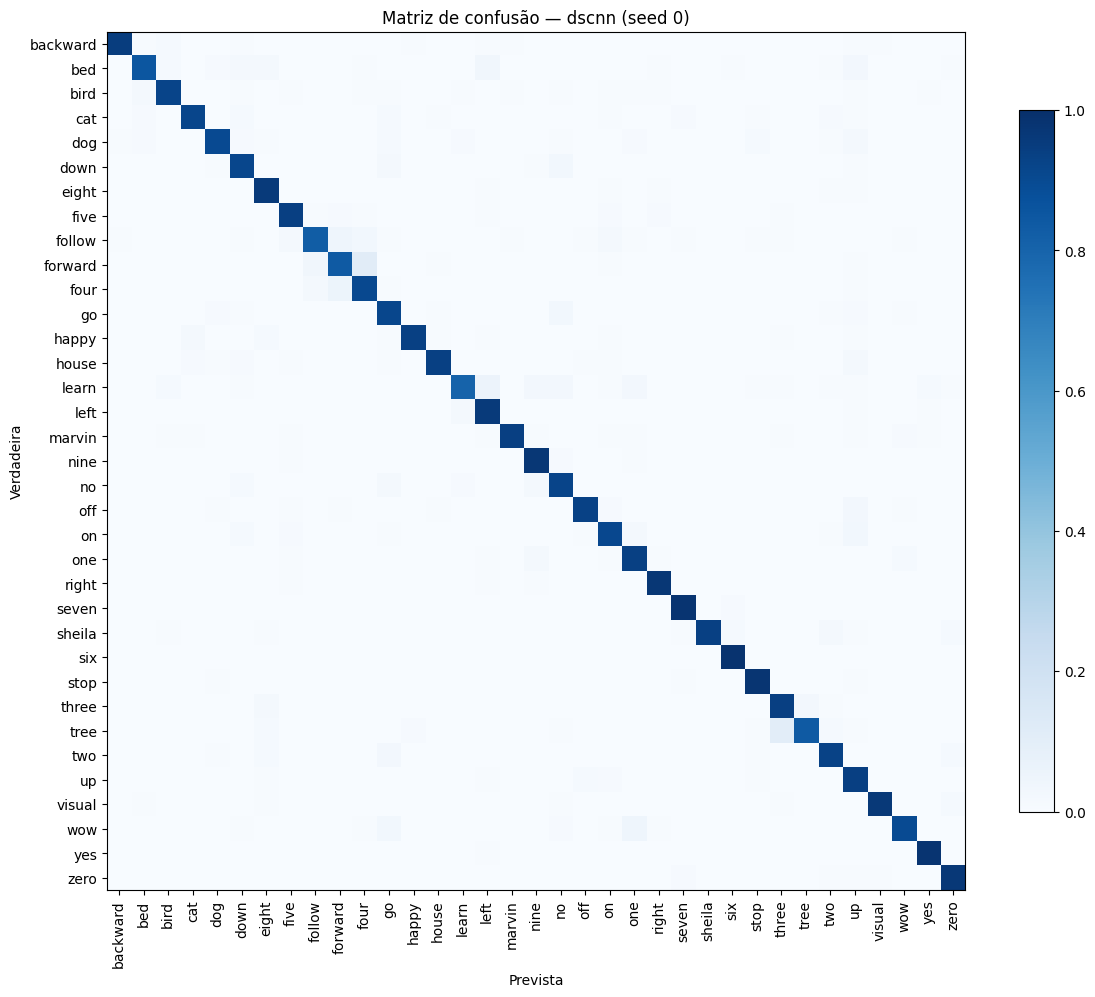

dscnn: as 10 confusões mais frequentes


,verdadeira,prevista,fração
0,forward,four,0.109677
1,tree,three,0.103627
2,learn,left,0.055901
3,four,forward,0.052500
4,follow,forward,0.046512
5,wow,one,0.043689
6,bed,left,0.033816
7,forward,follow,0.032258
8,go,no,0.029851
9,down,no,0.029557


dscnn: desempenho por palavra


,precisao,revocacao,f1,exemplos
forward,0.774,0.839,0.805,155
learn,0.878,0.801,0.838,161
follow,0.882,0.826,0.853,172
tree,0.942,0.839,0.888,193
bed,0.932,0.855,0.892,207
go,0.880,0.913,0.896,402
up,0.862,0.941,0.900,425
no,0.901,0.919,0.910,405
wow,0.925,0.898,0.911,206
four,0.926,0.902,0.914,400


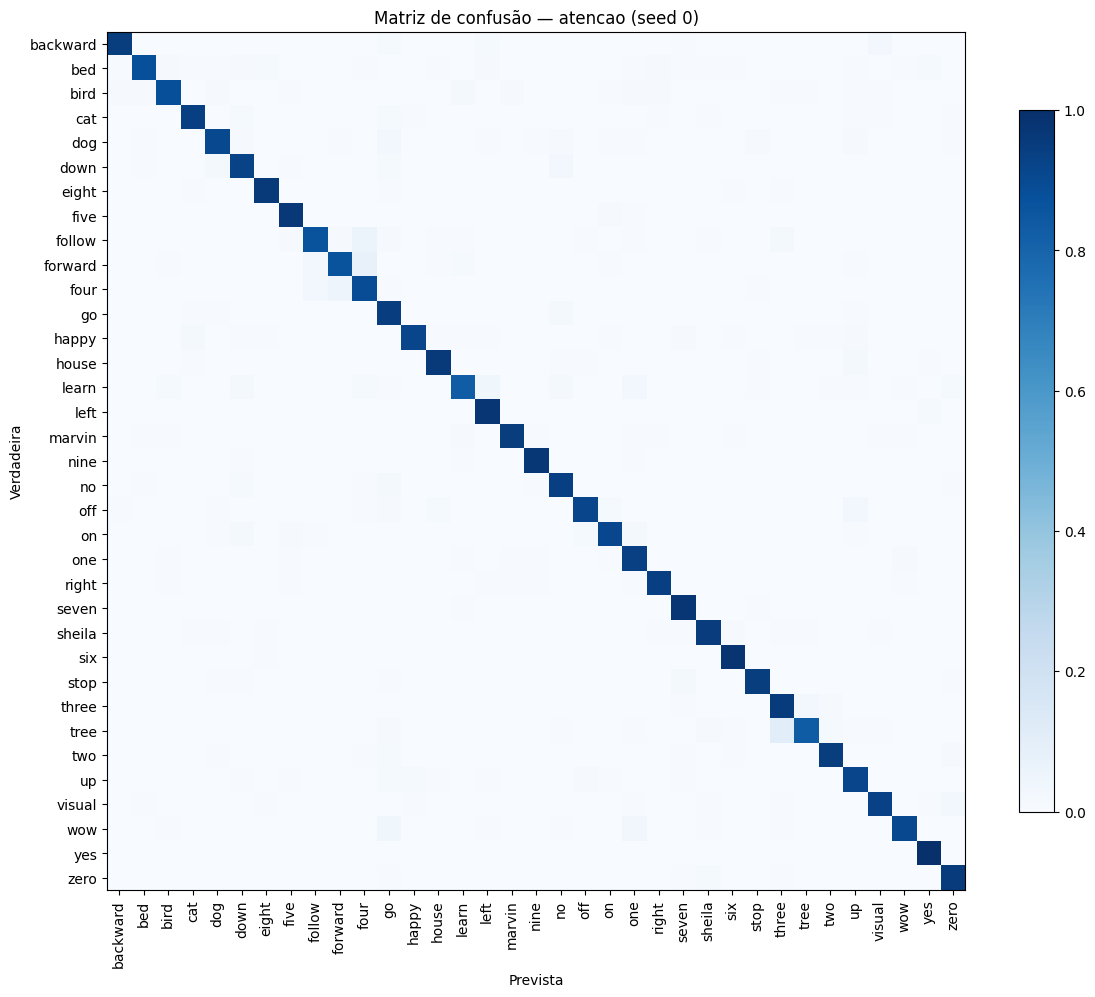

atencao: as 10 confusões mais frequentes


,verdadeira,prevista,fração
0,tree,three,0.108808
1,forward,four,0.070968
2,follow,four,0.052326
3,four,forward,0.047500
4,wow,go,0.038835
5,learn,left,0.037267
6,wow,one,0.033981
7,learn,one,0.031056
8,dog,go,0.027273
9,down,no,0.027094


atencao: desempenho por palavra


,precisao,revocacao,f1,exemplos
learn,0.869,0.826,0.847,161
forward,0.843,0.865,0.854,155
tree,0.909,0.829,0.867,193
follow,0.876,0.866,0.871,172
dog,0.888,0.905,0.896,220
bed,0.919,0.879,0.899,207
go,0.862,0.945,0.902,402
four,0.915,0.890,0.902,400
bird,0.931,0.881,0.906,185
up,0.917,0.915,0.916,425


In [20]:
from avaliacao import matriz_confusao, relatorio_por_classe, top_confusoes
from avaliacao.graficos import plot_matriz_confusao

#Para CADA modelo de MODELOS (seed SEEDS[0]): matriz de confusão, as 10 confusões mais frequentes e
#precisão, revocação e F1 de cada palavra, da pior para a melhor
for nome in treinados:
    y_pred, y_true = predicoes[(nome, SEEDS[0])]
    cm = matriz_confusao(y_pred, y_true, n_classes=len(CLASSES))
    plot_matriz_confusao(cm, CLASSES, titulo=f"Matriz de confusão — {nome} (seed {SEEDS[0]})")

    print(f"{nome}: as 10 confusões mais frequentes")
    display(pd.DataFrame(top_confusoes(cm, CLASSES, k=10), columns=["verdadeira", "prevista", "fração"]))

    print(f"{nome}: desempenho por palavra")
    display(relatorio_por_classe(y_pred, y_true, CLASSES).round(3))

In [21]:
#Ranking de F1 por classe no TESTE (seed SEEDS[0]): uma coluna por modelo, das palavras mais difíceis para as mais fáceis
if len(resultados_gsc):
    ranking = pd.DataFrame({nome: relatorio_por_classe(*predicoes[(nome, SEEDS[0])], CLASSES)["f1"]
                            for nome in treinados})
    display(ranking.sort_values(list(ranking.columns)[0]).round(3))

,mlp,cnn1d,resnet,dscnn,atencao
forward,0.445,0.720,0.860,0.805,0.854
learn,0.472,0.790,0.858,0.838,0.847
go,0.541,0.864,0.900,0.896,0.902
no,0.618,0.900,0.920,0.910,0.933
follow,0.618,0.837,0.892,0.853,0.871
dog,0.654,0.882,0.929,0.915,0.896
bed,0.657,0.858,0.878,0.892,0.899
tree,0.668,0.878,0.895,0.888,0.867
down,0.683,0.866,0.913,0.917,0.923
four,0.693,0.864,0.934,0.914,0.902


### 6.1 Em qual microcontrolador cabe?

Os **pesos** do modelo ficam na **Flash** do microcontrolador (MCU), a memória não volátil. Em int8 (quantizado,
como no TFLite Micro) é 1 byte por parâmetro = `kb_int8` da §4.1; o fp32 (4 bytes por parâmetro) aparece em linha
clara só para comparação.

Quatro MCUs conhecidos, do menor para o maior:

| Placa (MCU) | Núcleo | Flash | Por que este |
|---|---|---|---|
| Arduino Uno (ATmega328P) | AVR 8 bits, 16 MHz | 32 KB (0,5 KB do bootloader) | o Arduino clássico, o MCU "de entrada" |
| LaunchPad MSP-EXP430FR5994 (MSP430FR5994) | MSP430 16 bits, 16 MHz | 256 KB (FRAM) | o MSP430 usado em pesquisa de redes neurais em MCU (Gobieski et al., 2019) |
| Arduino Nano 33 BLE Sense (nRF52840) | Cortex-M4F, 64 MHz | 1 MB | a placa do exemplo `micro_speech` do TFLite Micro (Warden e Situnayake, 2019) |
| ESP32-WROOM-32 (ESP32) | Xtensa LX6 dual-core, 240 MHz | 4 MB (externa) | o MCU com Wi-Fi mais popular e barato |

Números dos datasheets (ver Referências). No gráfico, cada barra é a Flash de um MCU e cada linha vertical
é um modelo de `MODELOS`: se a linha passa do fim da barra, o modelo não cabe.

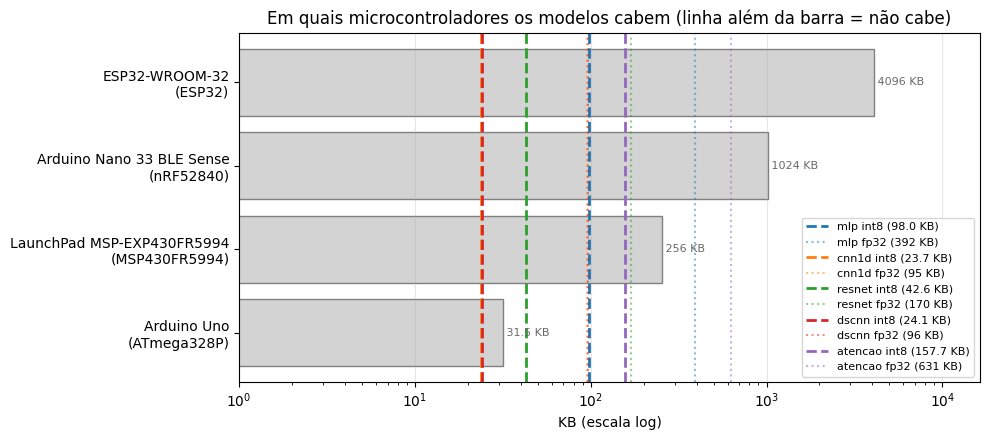

modelo,atencao,cnn1d,dscnn,mlp,resnet
mcu,,,,,
Arduino Uno (ATmega328P),500.5,75.3,76.5,311.2,135.3
LaunchPad MSP-EXP430FR5994 (MSP430FR5994),61.6,9.3,9.4,38.3,16.6
Arduino Nano 33 BLE Sense (nRF52840),15.4,2.3,2.4,9.6,4.2
ESP32-WROOM-32 (ESP32),3.8,0.6,0.6,2.4,1.0


In [22]:
from avaliacao.graficos import cabe_em_microcontroladores

#Usa a tabela de custo da §4.1: pesos em int8 contra a Flash de cada MCU
cabe = cabe_em_microcontroladores(tabela_custo)
cabe.pivot(index="mcu", columns="modelo", values="flash usada (%)").loc[cabe["mcu"].unique()]   #do menor MCU para o maior

## 7. Latência (MFCC × rede) — hipótese (b)

Protocolo: CPU com **1 thread**, **batch 1** (um comando por vez, como no dispositivo), aquecimento e mediana de
300 repetições. **MFCC, normalização e rede são medidos separados**, em rodadas: se a razão (pré-processamento /
rede) oscilar mais de 30%, a medida é refeita. O MFCC também é medido com o librosa, para ver se a biblioteca muda
a resposta. Cada escolha é explicada no [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seção 7).

,modelo,entrada,mfcc_ms,mfcc_p95_ms,norm_ms,norm_p95_ms,rede_ms,rede_p95_ms,preproc_ms,preproc_sobre_rede,...,razao_max,oscilacao,estavel,tentativas_feitas,rede_x8_ms,fator_x8,rodadas,cpu,mfcc_librosa_ms,mfcc_librosa_p95_ms
0,mlp,10x49,0.506,0.529,0.007,0.007,0.116,0.132,0.513,4.440,...,4.474,0.011,True,1,0.154,1.329,5,Intel(R) Xeon(R) CPU @ 2.20GHz,1.593,1.647
1,cnn1d,10x49,0.534,0.563,0.007,0.007,0.371,0.392,0.540,1.456,...,1.506,0.094,True,1,1.057,2.847,5,Intel(R) Xeon(R) CPU @ 2.20GHz,1.568,1.635
2,resnet,10x49,0.518,0.551,0.007,0.007,3.711,3.834,0.525,0.141,...,0.147,0.059,True,1,12.280,3.309,5,Intel(R) Xeon(R) CPU @ 2.20GHz,1.602,1.657
3,dscnn,10x49,0.510,0.531,0.007,0.007,1.570,1.619,0.517,0.327,...,0.339,0.047,True,1,2.775,1.767,5,Intel(R) Xeon(R) CPU @ 2.20GHz,1.614,1.668
4,atencao,40x101,0.691,0.715,0.008,0.009,2.176,2.262,0.699,0.320,...,0.336,0.060,True,1,7.493,3.443,5,Intel(R) Xeon(R) CPU @ 2.20GHz,1.726,1.818


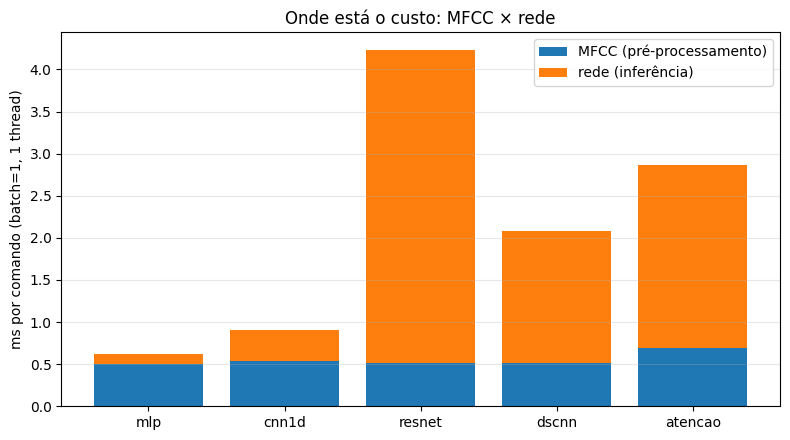

In [23]:
from avaliacao import medir_latencia
from avaliacao.graficos import barras_latencia

linhas = []
for nome in MODELOS:
    if not esta_implementado(nome):
        continue
    hp = config(nome)
    if nome in treinados:
        model, media, desvio = treinados[nome][0][1], entradas[nome]["media"], entradas[nome]["desvio"]
    elif hp["normalizacao"] == "global":
        #Sem treino: média 0 e desvio 1 têm o mesmo custo (o tempo depende só do formato)
        model, media, desvio = criar_modelo(nome, hp), torch.zeros(hp["n_mfcc"], 1), torch.ones(hp["n_mfcc"], 1)
    else:
        model, media, desvio = criar_modelo(nome, hp), None, None
    linhas.append(dict(modelo=nome, entrada=f"{hp['n_mfcc']}x{hp['n_frames']}",
                       **medir_latencia(model, hp, media, desvio, com_librosa=True)))

latencia = pd.DataFrame(linhas)
if len(latencia):
    display(latencia.round(3))
    barras_latencia(latencia)

## 8. Experimentos

Cada família passa por uma varredura de configurações: quanto dá para encolher o modelo sem perder
reconhecimento? Para a **CNN 1D** e a **ResNet** a varredura foi feita antes, no playground de cada uma: **aqui rodam só o *baseline*** (a referência do critério) **e o vencedor**, e as
tabelas "O que encontramos" trazem os números das outras configurações. **MLP, DS-CNN e Atenção não têm
playground: a varredura delas roda inteira aqui** (12 configurações cada). O código é o mesmo para todos
(`treino/varredura.py`): muda só a lista de configurações. Os playgrounds treinaram 20 épocas com OneCycle. Aqui
todas as configurações usam o early stop da §5, então os treinos do playground salvos no Drive **não** são
reaproveitados (`mesma_politica`), e o baseline e o vencedor da CNN 1D e da ResNet são treinados de novo.

**Critério, definido antes de ver os resultados:** o vencedor é o **menor** modelo (parâmetros, depois MACs) até
**2 p.p.** abaixo do baseline na acurácia de **validação**. O teste só é reportado. A latência segue a §7, em 3
passadas, ficando com a mais rápida.

### 8.1 MLP: quanto dá para encolher

O *baseline* do projeto: achata o MFCC e passa por camadas densas, sem nenhuma noção de tempo (`modelos/mlp.py`).
A arquitetura de partida é a do [notebook de exploração do MLP](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/Projeto_MLP.ipynb) (79,6% de validação na `gsc12`):
3 camadas densas de 128 neurônios, dropout 0,1 e sem BatchNorm. Como cada número da entrada tem um peso próprio na
primeira camada, a entrada 40 × 101 (4.040 números) pesa muito mais que a `hello_edge` (10 × 49 = 490).

Sem playground: aqui roda a **varredura inteira** (`CONFIGS_MLP`, 12 configurações × `SEEDS`), com o loop da §5 e o
critério da §8:

| Grupo | Configurações |
|---|---|
| baseline | entrada 40 × 101, 3 camadas de 128 |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| menores | 64 e 32 neurônios, 2 camadas; e com BatchNorm |
| entrada `hello_edge` (10 × 49) | 128 (a versão do notebook de exploração), 64 e 32 neurônios, 2 camadas |

In [24]:
from treino.varredura import (CONFIGS_MLP, rodar_varredura, medir_latencias_varredura, anexar_latencias,
                              montar_resumo, tabela_slide, escolher_vencedor, matrizes_escolhidos)

#A varredura inteira: 12 configurações (baseline, 3 de treino, modelos menores e a entrada hello_edge)
hp_mlp = config("mlp", epocas=EPOCAS)
VARRER_MLP = RODAR_VARREDURAS and "mlp" in MODELOS

if VARRER_MLP:
    tabela_mlp, modelos_mlp = rodar_varredura("mlp", CONFIGS_MLP, hp_mlp, SEEDS, RAIZ_GSC, PASTAS,
                                              retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.1: RODAR_VARREDURAS=False ou mlp fora de MODELOS")

mlp | seed 0:   8%|▊         | 1/12 [00:04<00:48,  4.38s/it, sem spec_augment]

baseline (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/mlp_baseline_s0_20261111-134529


mlp | seed 0:  17%|█▋        | 2/12 [00:08<00:44,  4.44s/it, norm por_amostra]

sem spec_augment (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/mlp_sem_spec_augment_s0_20261111-134640


mlp | seed 0:  25%|██▌       | 3/12 [00:13<00:42,  4.68s/it, sem weight_decay]

norm por_amostra (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/mlp_norm_por_amostra_s0_20261111-134807


... (66 outputs left out)

mlp | seed 2:  92%|█████████▏| 11/12 [00:50<00:03,  3.47s/it, hello_edge + 2 camadas]

hello_edge + hidden 32 (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/mlp_hello_edge_mais_hidden_32_s2_20261111-144019


mlp | seed 2: 100%|██████████| 12/12 [00:54<00:00,  4.52s/it, hello_edge + 2 camadas]

hello_edge + 2 camadas (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/mlp_hello_edge_mais_2_camadas_s2_20261111-144206


In [25]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_MLP:
    latencias_mlp = medir_latencias_varredura("mlp", CONFIGS_MLP, hp_mlp)
    tabela_mlp = anexar_latencias(tabela_mlp, latencias_mlp)
    resumo_mlp = montar_resumo(tabela_mlp, hp_mlp["fracao"], hp_mlp["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_mlp[["experimento", "seed", "entrada", "hidden", "n_camadas", "batchnorm", "params", "macs", "acc_val",
                     "melhor_epoca", "epocas_treinadas", "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

baseline                   | MFCC 0.725 ms | norm 0.008 ms | rede 0.226 ms | preproc/rede 3.24x | estável: True | rede nas passadas: 0.226 / 0.235 / 0.236
sem spec_augment           | MFCC 0.727 ms | norm 0.008 ms | rede 0.232 ms | preproc/rede 3.17x | estável: True | rede nas passadas: 0.232 / 0.234 / 0.237
norm por_amostra           | MFCC 0.731 ms | norm 0.072 ms | rede 0.240 ms | preproc/rede 3.35x | estável: True | rede nas passadas: 0.240 / 0.243 / 0.243
sem weight_decay           | MFCC 0.718 ms | norm 0.008 ms | rede 0.235 ms | preproc/rede 3.09x | estável: True | rede nas passadas: 0.236 / 0.235 / 0.235
hidden 64                  | MFCC 0.700 ms | norm 0.008 ms | rede 0.169 ms | preproc/rede 4.19x | estável: True | rede nas passadas: 0.169 / 0.171 / 0.171
hidden 32                  | MFCC 0.716 ms | norm 0.008 ms | rede 0.129 ms | preproc/rede 5.62x | estável: True | rede nas passadas: 0.129 / 0.129 / 0.129
2 camadas                  | MFCC 0.726 ms | norm 0.008 ms | rede 0.20

,experimento,seed,entrada,hidden,n_camadas,batchnorm,params,macs,acc_val,melhor_epoca,epocas_treinadas,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,128,3,False,554787,554368,0.7609,27,32.0,0.0866,0.7224,0.7122,0.7251,0.2259,1.4266
1,sem spec_augment,0,40x101,128,3,False,554787,554368,0.7300,24,29.0,0.5204,0.6970,0.6834,0.7274,0.2321,1.1134
2,norm por_amostra,0,40x101,128,3,False,554787,554368,0.7370,29,31.0,0.1719,0.6972,0.6845,0.7307,0.2396,1.3799
3,sem weight_decay,0,40x101,128,3,False,554787,554368,0.7552,46,50.0,0.1505,0.7258,0.7124,0.7184,0.2349,2.2166
4,hidden 64,0,40x101,64,3,False,269219,268992,0.7092,29,34.0,-0.0823,0.6820,0.6665,0.7002,0.1688,1.5255
5,hidden 32,0,40x101,32,3,False,132579,132448,0.6210,45,50.0,-0.2289,0.5850,0.5542,0.7161,0.1288,2.2397
6,2 camadas,0,40x101,128,2,False,538275,537984,0.7345,21,26.0,0.1316,0.7011,0.6885,0.7261,0.2019,1.0731
7,com batchnorm,0,40x101,128,3,True,555555,554368,0.7748,18,23.0,0.0594,0.7366,0.7244,0.7245,0.3220,1.1809
8,entrada hello_edge,0,10x49,128,3,False,100387,99968,0.8249,50,50.0,-0.4143,0.7959,0.7842,0.5147,0.1152,1.8871
9,hello_edge + hidden 64,0,10x49,64,3,False,42019,41792,0.7566,32,37.0,-0.5323,0.7167,0.7022,0.5079,0.1076,1.4103


,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,554787,541.8,554368,76.26 ± 0.43,72.44 ± 0.65,71.32 ± 0.56,0.725,0.226,3.24,0.00,True
sem spec_augment,40x101,554787,541.8,554368,72.30 ± 1.62,68.90 ± 1.38,67.40 ± 1.60,0.727,0.232,3.17,-3.96,False
norm por_amostra,40x101,554787,541.8,554368,73.91 ± 0.20,69.96 ± 0.31,68.65 ± 0.27,0.731,0.240,3.35,-2.35,False
sem weight_decay,40x101,554787,541.8,554368,75.52 ± 0.01,72.30 ± 0.28,71.01 ± 0.24,0.718,0.235,3.09,-0.74,True
hidden 64,40x101,269219,262.9,268992,71.24 ± 0.29,68.11 ± 0.14,66.49 ± 0.18,0.700,0.169,4.19,-5.02,False
hidden 32,40x101,132579,129.5,132448,61.32 ± 1.25,57.42 ± 1.41,54.35 ± 1.41,0.716,0.129,5.62,-14.94,False
2 camadas,40x101,538275,525.7,537984,74.57 ± 0.97,71.36 ± 1.08,70.17 ± 1.15,0.726,0.202,3.64,-1.69,True
com batchnorm,40x101,555555,542.5,554368,77.05 ± 0.37,73.75 ± 0.48,72.54 ± 0.59,0.725,0.322,2.27,0.79,True
entrada hello_edge,10x49,100387,98.0,99968,81.97 ± 0.91,78.88 ± 0.65,77.88 ± 0.51,0.515,0.115,4.52,5.71,True


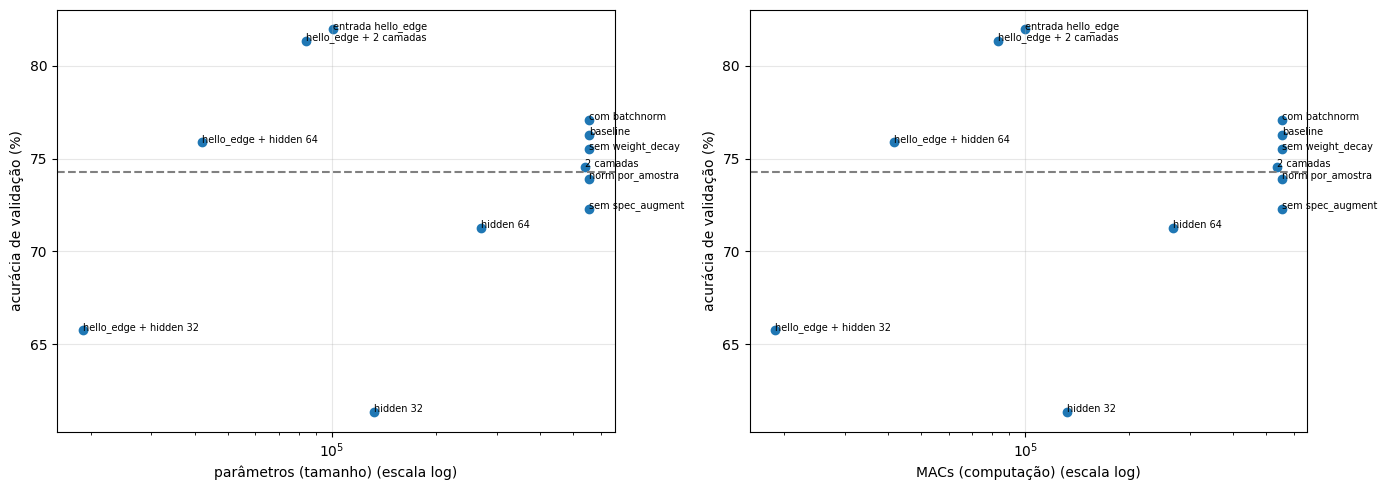

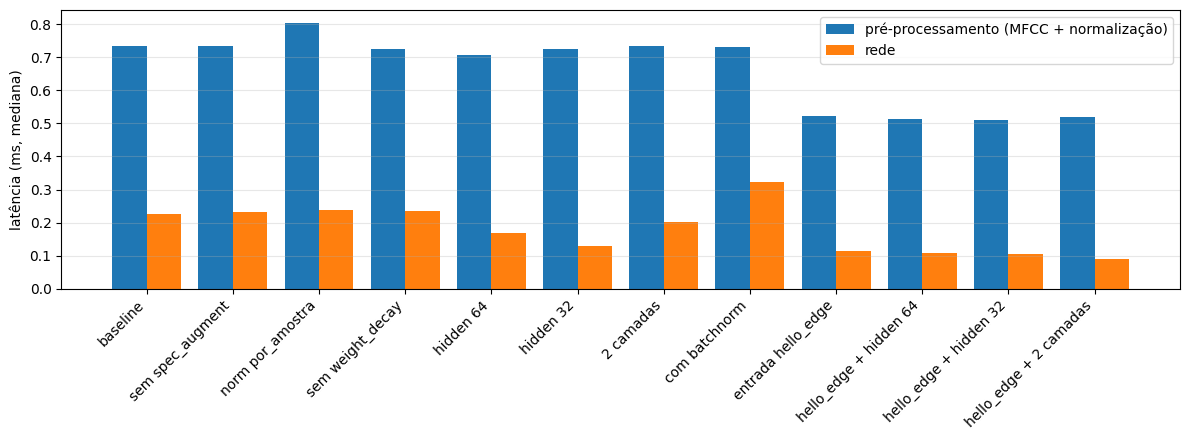

In [26]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

if VARRER_MLP:
    #A tabela dos slides
    display(tabela_slide(resumo_mlp))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_mlp, hp_mlp["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_mlp)

In [27]:
if VARRER_MLP:
    vencedor_mlp = escolher_vencedor(resumo_mlp)

    #Conferência: hp_modelos['mlp'] (§2, usado no resto do notebook) deve ser o vencedor.
    #Se der False, copie as mudanças impressas para hp_modelos['mlp'] (§2) e para configs/__init__.py
    mudancas_vencedor = dict(CONFIGS_MLP)[vencedor_mlp]
    hp_vencedor = config("mlp")
    print("hp_modelos['mlp'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          mudancas_vencedor)

Menor modelo dentro de 2 p.p. do baseline: hello_edge + hidden 64 (42,019 parâmetros, 41,792 MACs)
hp_modelos['mlp'] usa o vencedor: False {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'hidden': 64, 'n_camadas': 3, 'dropout': 0.1, 'batchnorm': False}


gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


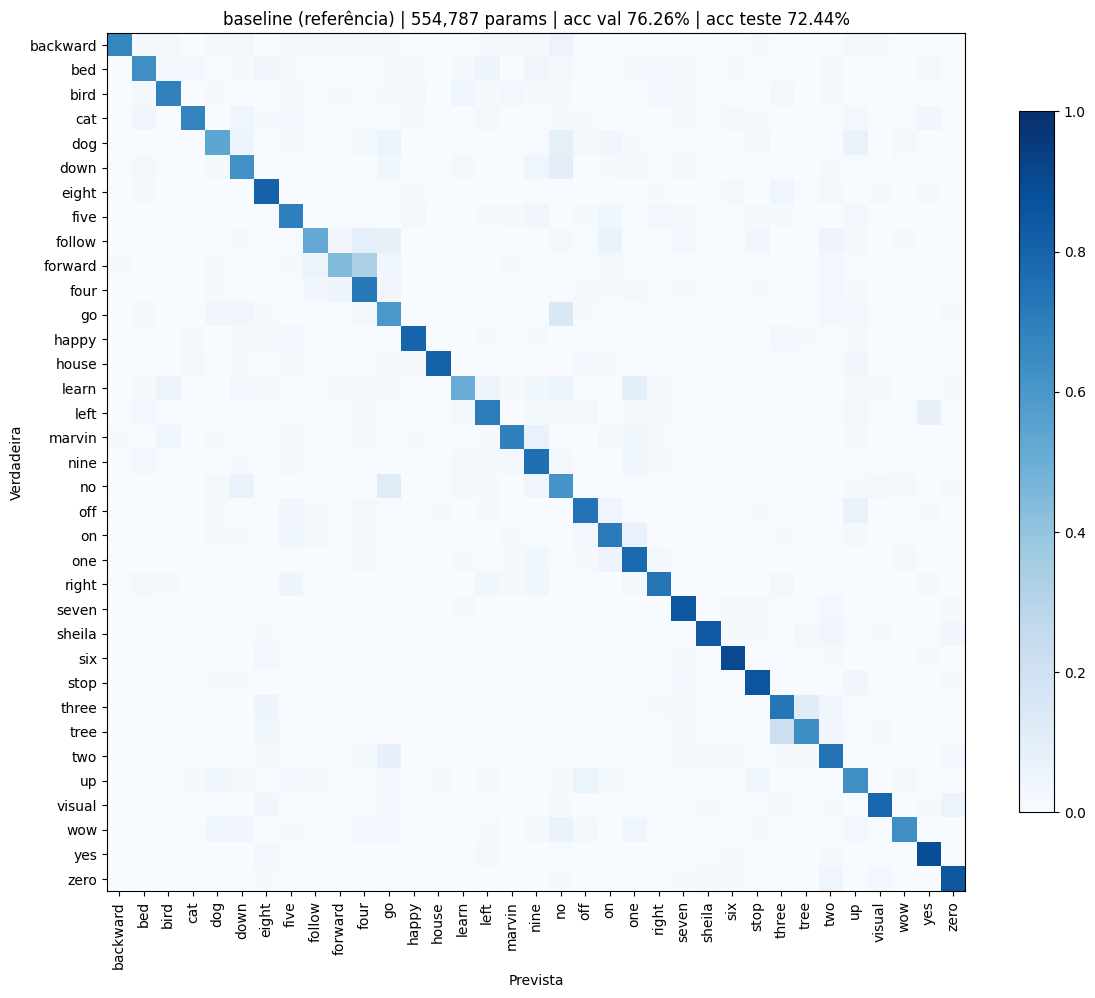

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


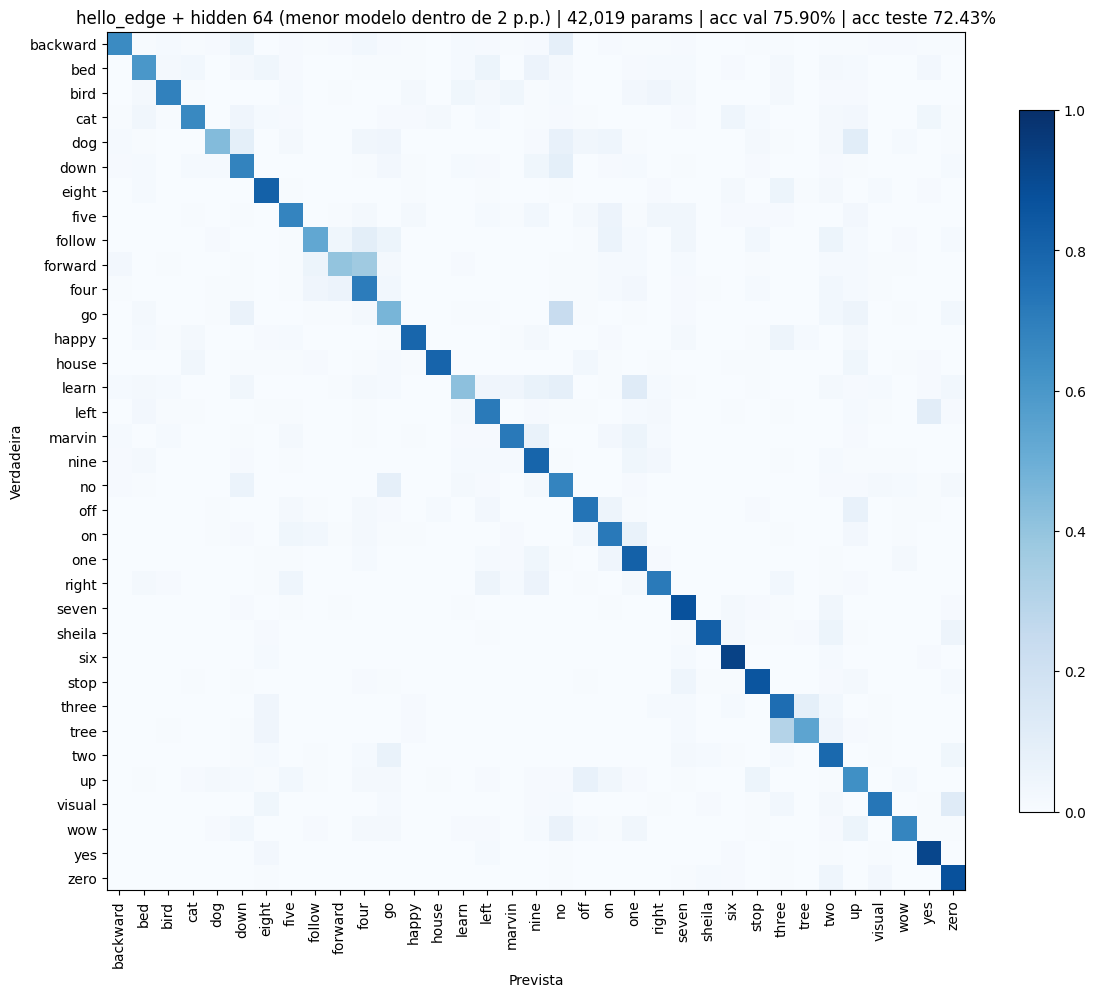

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


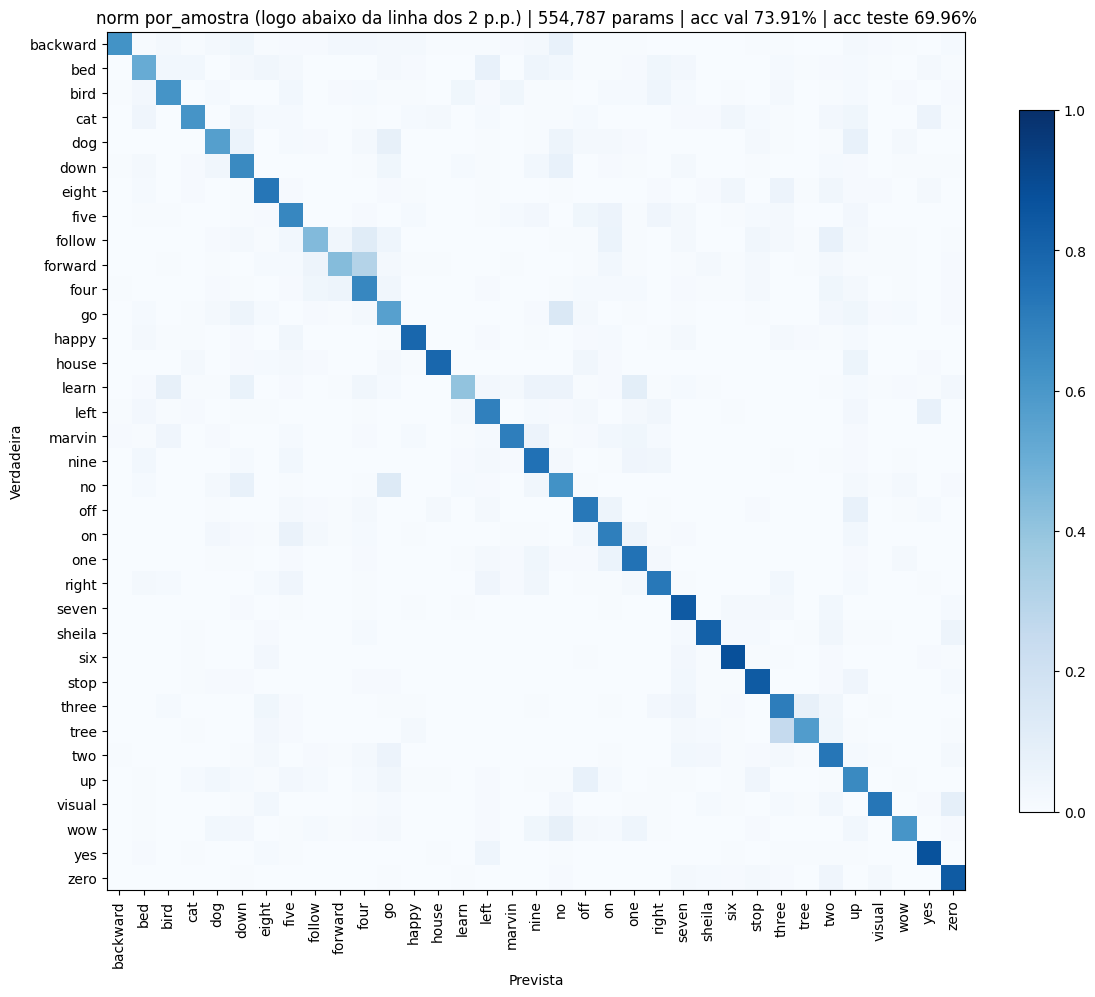

In [28]:
#Matrizes de confusão (no TESTE, somadas entre as seeds) de 3 configurações escolhidas pela VALIDAÇÃO:
#o baseline, o vencedor e o que ficou logo abaixo da linha dos 2 p.p.
if VARRER_MLP:
    matrizes_escolhidos(resumo_mlp, modelos_mlp, CONFIGS_MLP, hp_mlp, SEEDS, RAIZ_GSC, PASTAS["cache"])

#### O que encontramos

Execução no Colab (L4), early stop da §5 (teto 50, paciência 5), 3 seeds. Números da tabela dos slides acima.

| Configuração | Entrada | Params | MACs | Acc val (%) | Dif. val (p.p.) | Acc teste (%) |
|---|---|---|---|---|---|---|
| baseline | 40 × 101 | 554.787 | 554.368 | 76,26 ± 0,43 | 0,00 | 72,44 ± 0,65 |
| com batchnorm | 40 × 101 | 555.555 | 554.368 | 77,05 ± 0,37 | +0,79 | 73,75 ± 0,48 |
| 2 camadas | 40 × 101 | 538.275 | 537.984 | 74,57 ± 0,97 | −1,69 | 71,36 ± 1,08 |
| hidden 64 | 40 × 101 | 269.219 | 268.992 | 71,24 ± 0,29 | −5,02 | 68,11 ± 0,14 |
| hidden 32 | 40 × 101 | 132.579 | 132.448 | 61,32 ± 1,25 | −14,94 | 57,42 ± 1,41 |
| entrada hello_edge (128) | 10 × 49 | 100.387 | 99.968 | 81,97 ± 0,91 | +5,71 | 78,88 ± 0,65 |
| hello_edge + 2 camadas | 10 × 49 | 83.875 | 83.584 | 81,35 ± 0,85 | +5,10 | 78,37 ± 0,90 |
| **hello_edge + hidden 64 (vencedor)** | 10 × 49 | **42.019** | **41.792** | **75,90 ± 0,25** | **−0,36** | **72,43 ± 0,66** |
| hello_edge + hidden 32 | 10 × 49 | 18.979 | 18.848 | 65,75 ± 0,30 | −10,51 | 61,84 ± 0,79 |

- **A entrada menor é melhor, e não só mais barata:** com 128 neurônios, trocar 40 × 101 por 10 × 49 **ganha**
  +5,7 p.p. na validação com 1/5 dos parâmetros. O MLP não tem noção de tempo nem de vizinhança: com 4.040 números
  de entrada ele tem pesos demais para aprender e generaliza pior.
- **Vencedor:** `hello_edge` + 64 neurônios, com **42 mil parâmetros** (13x menos que o baseline), a −0,36 p.p. Pelo
  critério da §8 ele empata com o baseline; ainda assim fica −6,1 p.p. abaixo do `hello_edge` com 128, a arquitetura
  usada da §5 à §9.
- **A largura é o que pesa:** 32 neurônios cai −10,5 p.p. (`hello_edge`) e −14,9 p.p. (40 × 101). Tirar uma camada
  custa pouco (−0,6 p.p. no `hello_edge`).
- **Treino:** o SpecAugment é a variação que mais ajuda (sem ele: −3,96 p.p.). A normalização por amostra piora
  (−2,35), o weight decay quase não muda (sem ele: −0,74) e o BatchNorm ajuda um pouco (+0,79).
- **Hipótese (b), já aqui:** a rede é tão barata (0,09–0,32 ms) que o pré-processamento custa **de 2,3x a 5,9x** a
  rede. No MLP, o MFCC domina sempre.
- Mesmo o melhor MLP (~79% no teste) fica 12 p.p. ou mais abaixo das outras famílias (§9): sem convolução nem atenção,
  ele não aproveita a estrutura do áudio.

### 8.2 CNN 1D: quanto dá para encolher

No [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (seções 8 e 9) foram 13 configurações (`CONFIGS_CNN1D`) × 3 seeds, no GSC
completo e com o loop da §5:

| Grupo | Configurações |
|---|---|
| baseline | entrada 40 × 101, 64 canais |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| largura | 32, 16, 8 e 4 canais |
| entrada `hello_edge` (10 × 49) | 64, 48, 32, 16 e 8 canais |

Aqui rodam o **baseline** e o **vencedor** (`hello_edge` + 48 canais).

In [29]:
from treino.varredura import (CONFIGS_CNN1D, rodar_varredura, medir_latencias_varredura, anexar_latencias,
                              montar_resumo, tabela_slide, escolher_vencedor, matrizes_escolhidos)

#Só o baseline (referência do critério) e o vencedor. As 13 configurações estão no playground da CNN 1D
CONFIGS_CNN1D_RELATORIO = [c for c in CONFIGS_CNN1D if c[0] in ('baseline', 'hello_edge + canais 48')]

hp_cnn1d = config("cnn1d", epocas=EPOCAS)
VARRER_CNN1D = RODAR_VARREDURAS and "cnn1d" in MODELOS

if VARRER_CNN1D:
    tabela_cnn1d, modelos_cnn1d = rodar_varredura("cnn1d", CONFIGS_CNN1D_RELATORIO, hp_cnn1d, SEEDS, RAIZ_GSC, PASTAS,
                                                  retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.2: RODAR_VARREDURAS=False ou cnn1d fora de MODELOS")

cnn1d | seed 0:  50%|█████     | 1/2 [00:03<00:03,  3.47s/it, hello_edge + canais 48]

baseline (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/cnn1d_baseline_s0_20261111-144520
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


cnn1d | seed 0: 100%|██████████| 2/2 [00:06<00:00,  3.39s/it, hello_edge + canais 48]


hello_edge + canais 48 (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/cnn1d_hello_edge_mais_canais_48_s0_20261111-144713


cnn1d | seed 1:   0%|          | 0/2 [00:00<?, ?it/s, baseline]

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


... (6 outputs left out)

cnn1d | seed 2:  50%|█████     | 1/2 [00:05<00:05,  5.51s/it, hello_edge + canais 48]

baseline (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/cnn1d_baseline_s2_20261111-145327
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


cnn1d | seed 2: 100%|██████████| 2/2 [00:08<00:00,  4.38s/it, hello_edge + canais 48]

hello_edge + canais 48 (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/cnn1d_hello_edge_mais_canais_48_s2_20261111-145506


In [30]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_CNN1D:
    latencias_cnn1d = medir_latencias_varredura("cnn1d", CONFIGS_CNN1D_RELATORIO, hp_cnn1d)
    tabela_cnn1d = anexar_latencias(tabela_cnn1d, latencias_cnn1d)
    resumo_cnn1d = montar_resumo(tabela_cnn1d, hp_cnn1d["fracao"], hp_cnn1d["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_cnn1d[["experimento", "seed", "entrada", "canais", "params", "macs", "acc_val", "melhor_epoca", "epocas_treinadas",
                          "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

baseline                   | MFCC 0.725 ms | norm 0.008 ms | rede 0.469 ms | preproc/rede 1.56x | estável: True | rede nas passadas: 0.469 / 0.469 / 0.470
hello_edge + canais 48     | MFCC 0.518 ms | norm 0.007 ms | rede 0.370 ms | preproc/rede 1.42x | estável: True | rede nas passadas: 0.371 / 0.370 / 0.372
CPU (todas as medidas): Intel(R) Xeon(R) CPU @ 2.20GHz


,experimento,seed,entrada,canais,params,macs,acc_val,melhor_epoca,epocas_treinadas,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,64,47331,1883840,0.9360,28,31.0,-0.0720,0.9274,0.9198,0.7248,0.4687,1.7846
1,hello_edge + canais 48,0,10x49,48,24275,383280,0.9322,32,37.0,-0.1865,0.9200,0.9131,0.5176,0.3704,1.8230
2,baseline,1,40x101,64,47331,1883840,0.9410,31,36.0,-0.0573,0.9274,0.9215,0.7248,0.4687,2.0756
3,hello_edge + canais 48,1,10x49,48,24275,383280,0.9330,40,45.0,-0.1726,0.9215,0.9149,0.5176,0.3704,2.2309
4,baseline,2,40x101,64,47331,1883840,0.9362,28,29.0,-0.0712,0.9278,0.9205,0.7248,0.4687,1.6738
5,hello_edge + canais 48,2,10x49,48,24275,383280,0.9270,27,32.0,-0.1775,0.9227,0.9159,0.5176,0.3704,1.5763


,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,47331,46.2,1883840,93.77 ± 0.28,92.75 ± 0.02,92.06 ± 0.08,0.725,0.469,1.56,0.0,True
hello_edge + canais 48,10x49,24275,23.7,383280,93.07 ± 0.33,92.14 ± 0.13,91.46 ± 0.14,0.518,0.370,1.42,-0.7,True


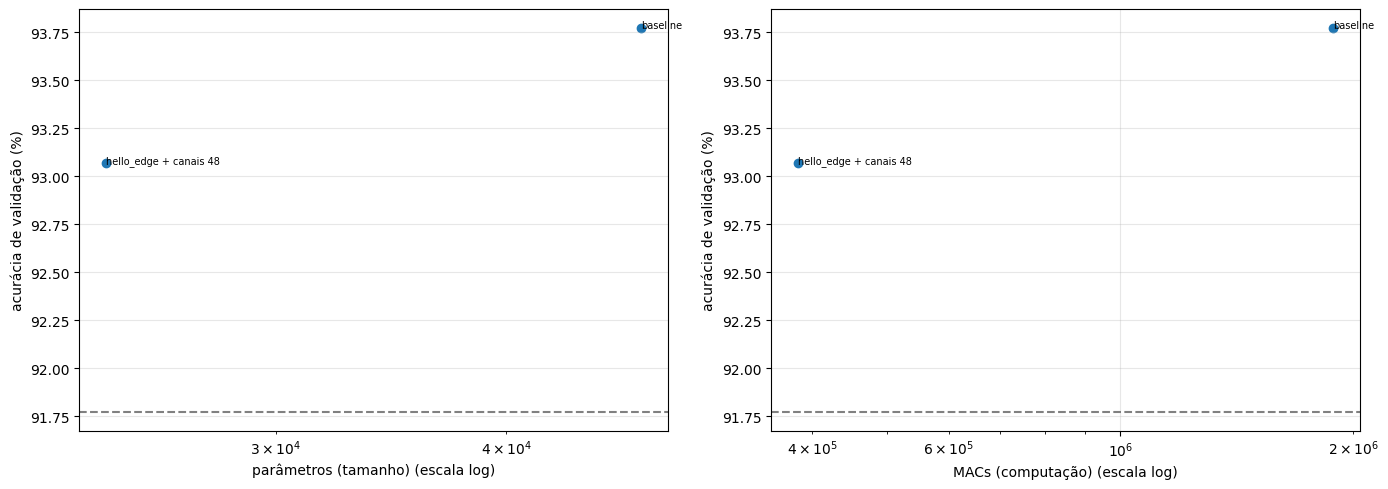

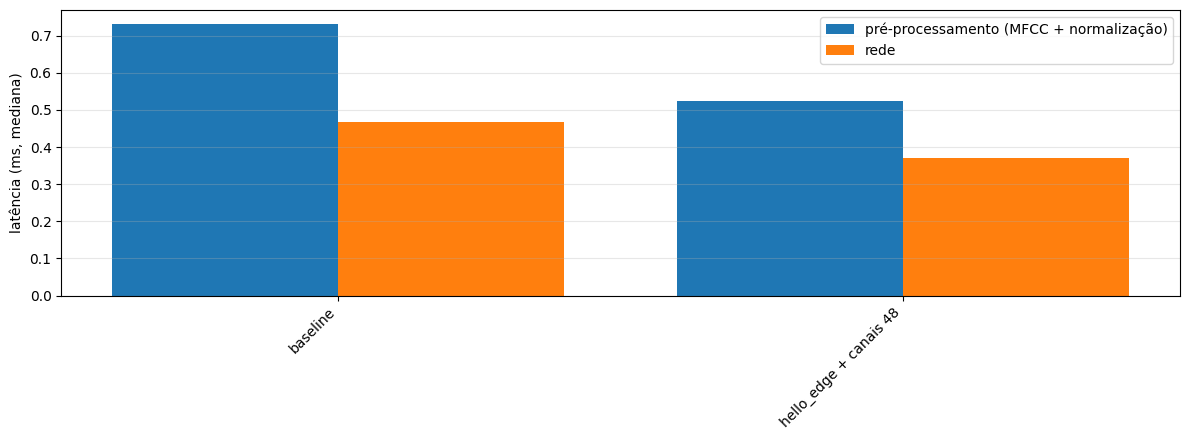

In [31]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

if VARRER_CNN1D:
    #A tabela dos slides
    display(tabela_slide(resumo_cnn1d))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_cnn1d, hp_cnn1d["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_cnn1d)

In [32]:
if VARRER_CNN1D:
    vencedor_cnn1d = escolher_vencedor(resumo_cnn1d)

    #Conferência: hp_modelos['cnn1d'] (§2, usado no resto do notebook) precisa ser exatamente o vencedor
    mudancas_vencedor = dict(CONFIGS_CNN1D_RELATORIO)[vencedor_cnn1d]
    hp_vencedor = config("cnn1d")
    print("hp_modelos['cnn1d'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          {k: hp_vencedor[k] for k in mudancas_vencedor})

Menor modelo dentro de 2 p.p. do baseline: hello_edge + canais 48 (24,275 parâmetros, 383,280 MACs)
hp_modelos['cnn1d'] usa o vencedor: True {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 48}


gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


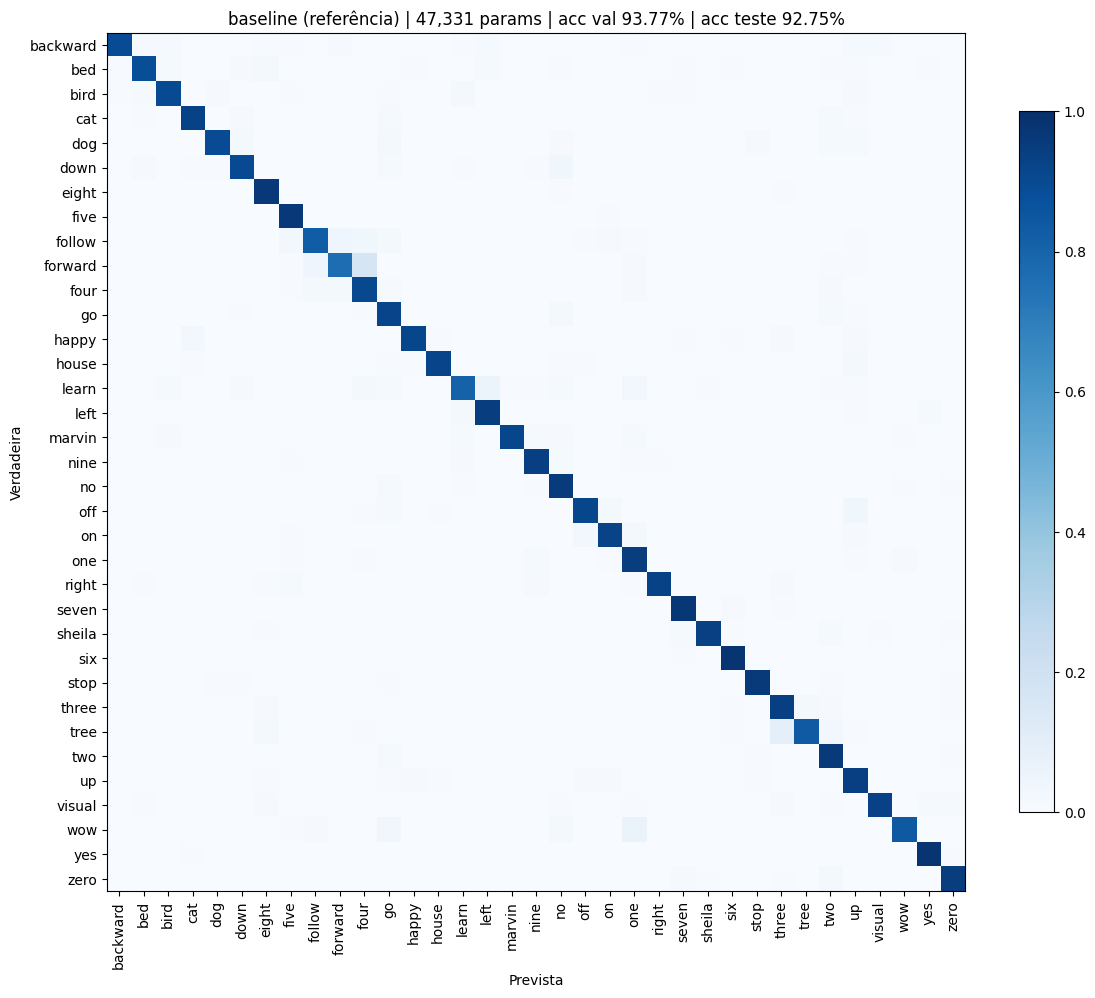

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


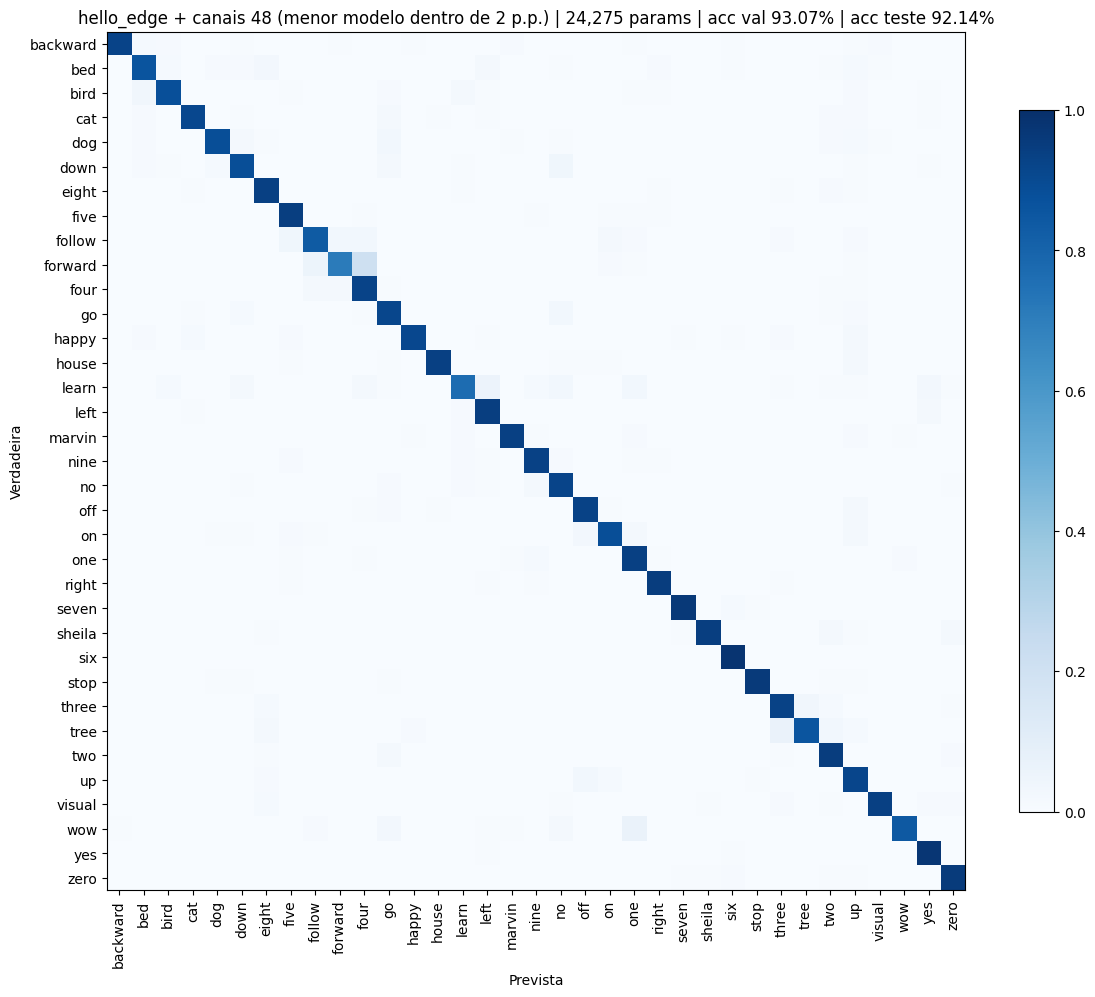

In [33]:
#Matrizes de confusão (no TESTE, somadas entre as seeds) de 3 configurações escolhidas pela VALIDAÇÃO:
#o baseline e o vencedor (o que ficou logo abaixo da linha dos 2 p.p. está no playground)
if VARRER_CNN1D:
    matrizes_escolhidos(resumo_cnn1d, modelos_cnn1d, CONFIGS_CNN1D_RELATORIO, hp_cnn1d, SEEDS, RAIZ_GSC, PASTAS["cache"])

#### O que encontramos

Execução do [playground da CNN 1D](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_cnn1d_guilherme.ipynb) (com as saídas salvas): GSC completo, 20 épocas com OneCycle, 3 seeds, latência numa CPU Intel
Xeon do Colab. As linhas **baseline** e **vencedor** foram substituídas pelos números desta execução (early stop da
§5, tabelas acima); as demais vêm do playground e não são diretamente comparáveis com elas.

| Configuração | Entrada | Params | MACs | Acc val (%) | Acc teste (%) | MFCC / rede (ms) |
|---|---|---|---|---|---|---|
| baseline (esta execução) | 40 × 101 | 47.331 | 1.883.840 | 93,77 ± 0,28 | 92,75 ± 0,02 | 0,73 / 0,47 |
| entrada hello_edge (64 canais) | 10 × 49 | 41.571 | 649.280 | 93,46 ± 0,04 | 92,59 ± 0,29 | 0,50 / 0,35 |
| **hello_edge + 48 canais (vencedor, esta execução)** | 10 × 49 | **24.275** | **383.280** | **93,07 ± 0,33** | **92,14 ± 0,13** | 0,52 / 0,37 |
| canais 32 | 40 × 101 | 14.467 | 665.440 | 90,62 ± 0,16 | 89,12 ± 0,24 | 0,69 / 0,36 |
| hello_edge + 32 canais | 10 × 49 | 11.587 | 186.400 | 90,20 ± 0,09 | 88,90 ± 0,34 | 0,50 / 0,32 |
| canais 16 | 40 × 101 | 4.947 | 263.600 | 84,16 ± 0,86 | 82,40 ± 0,61 | 0,68 / 0,31 |
| canais 4 | 40 × 101 | 831 | 52.940 | 40,38 ± 2,77 | 39,08 ± 2,32 | 0,68 / 0,29 |

- **A entrada menor sai de graça:** no playground, com 64 canais, trocar 40 × 101 por 10 × 49 não perdeu nada na
  validação (93,46% contra 93,51%), corta os MACs em ~3× e o MFCC em ~27% (0,68 → 0,50 ms).
- **A largura é o que pesa:** abaixo de 48 canais a acurácia cai rápido (32 canais: −2,9 p.p.; 16: −9,4 p.p.;
  4: −53 p.p.).
- **Vencedor:** `hello_edge` + 48 canais, com **metade dos parâmetros** e **1/5 dos MACs** do baseline, a
  −0,70 p.p. na validação com o early stop (−1,05 p.p. no playground): o vencedor continua o mesmo. É a configuração de `hp_modelos['cnn1d']` (§2), usada no resto do notebook.
- **Treino (playground):** o SpecAugment ajuda (+0,38 p.p.) e o weight decay quase não muda (+0,07 p.p.). A normalização por
  amostra foi a **melhor** configuração (+0,35 p.p. sobre o baseline); combiná-la com o vencedor é um próximo passo.
- **Hipótese (b), já aqui:** em todas as configurações o pré-processamento (MFCC + normalização) custa **mais**
  que a rede: 1,42× no vencedor nesta execução (1,56× no baseline) e até 2,4× nos modelos menores. Encolher só a rede não resolve, porque o MFCC
  passa a dominar.

### 8.3 ResNet: quanto dá para encolher

Conv2d 3 × 3 sobre o MFCC tratado como uma imagem de 1 canal, com atalhos residuais `x + F(x)`. As famílias vêm do
Tang & Lin (2018); as versões *narrow* usam 19 canais em vez de 45:

| Família | Blocos | Pooling na entrada | Detalhe |
|---|---|---|---|
| res8 | 3 | média 3 × 4 | a mais rasa e barata |
| res15 | 6 | nenhum | convoluções dilatadas (1, 1, 2, 2, 2, 4...) + 1 conv extra |
| res26 | 12 | média 2 × 2 | a mais profunda |

No [playground da ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb) (seção 7) foram 15 configurações (`CONFIGS_RESNET`) × 3 seeds, no GSC completo
e com o loop da §5:

| Grupo | Configurações |
|---|---|
| baseline | res8, entrada 40 × 101 |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| menores que o res8 | res8-narrow, res15-narrow, res26-narrow, res8 com 12 e com 8 canais |
| entrada `hello_edge` (10 × 49) | res8 e todas as menores acima |

Aqui rodam o **baseline** e o **vencedor** (res15-narrow + `hello_edge`).

In [34]:
from treino.varredura import CONFIGS_RESNET

#Só o baseline (referência do critério) e o vencedor. As 15 configurações estão no playground da ResNet
CONFIGS_RESNET_RELATORIO = [c for c in CONFIGS_RESNET if c[0] in ('baseline', 'res15-narrow + hello_edge')]

hp_resnet = config("resnet", epocas=EPOCAS)
VARRER_RESNET = RODAR_VARREDURAS and "resnet" in MODELOS

if VARRER_RESNET:
    tabela_resnet, modelos_resnet = rodar_varredura("resnet", CONFIGS_RESNET_RELATORIO, hp_resnet, SEEDS, RAIZ_GSC,
                                                    PASTAS, retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.3: RODAR_VARREDURAS=False ou resnet fora de MODELOS")

resnet | seed 0:   0%|          | 0/2 [00:00<?, ?it/s, baseline]

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


resnet | seed 0:  50%|█████     | 1/2 [00:06<00:06,  6.89s/it, res15-narrow + hello_edge]

baseline (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/resnet_baseline_s0_20261111-145914
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


resnet | seed 0: 100%|██████████| 2/2 [00:10<00:00,  5.07s/it, res15-narrow + hello_edge]


res15-narrow + hello_edge (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/resnet_res15-narrow_mais_hello_edge_s0_20261111-150400


... (8 outputs left out)

resnet | seed 2:  50%|█████     | 1/2 [00:06<00:06,  6.33s/it, res15-narrow + hello_edge]

baseline (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/resnet_baseline_s2_20261111-151858
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


resnet | seed 2: 100%|██████████| 2/2 [00:09<00:00,  4.84s/it, res15-narrow + hello_edge]

res15-narrow + hello_edge (seed 2): carregado de /content/drive/MyDrive/kws-borda/runs/resnet_res15-narrow_mais_hello_edge_s2_20261111-152355


In [35]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_RESNET:
    latencias_resnet = medir_latencias_varredura("resnet", CONFIGS_RESNET_RELATORIO, hp_resnet)
    tabela_resnet = anexar_latencias(tabela_resnet, latencias_resnet)
    resumo_resnet = montar_resumo(tabela_resnet, hp_resnet["fracao"], hp_resnet["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_resnet[["experimento", "seed", "entrada", "canais", "n_blocos", "params", "macs", "acc_val",
                           "melhor_epoca", "epocas_treinadas", "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

baseline                   | MFCC 0.721 ms | norm 0.008 ms | rede 3.070 ms | preproc/rede 0.24x | estável: True | rede nas passadas: 3.070 / 3.140 / 3.122
res15-narrow + hello_edge  | MFCC 0.518 ms | norm 0.007 ms | rede 3.739 ms | preproc/rede 0.14x | estável: True | rede nas passadas: 3.763 / 3.749 / 3.739
CPU (todas as medidas): Intel(R) Xeon(R) CPU @ 2.20GHz


,experimento,seed,entrada,canais,n_blocos,params,macs,acc_val,melhor_epoca,epocas_treinadas,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,45,3,111995,37176525,0.9475,20,21.0,-0.0378,0.9424,0.9368,0.7208,3.0699,3.4936
1,res15-narrow + hello_edge,0,10x49,19,6,43640,20780585,0.9491,34,38.0,-0.1152,0.9428,0.9377,0.5180,3.7385,4.6821
2,baseline,1,40x101,45,3,111995,37176525,0.9584,31,36.0,-0.0225,0.9537,0.9495,0.7208,3.0699,5.9798
3,res15-narrow + hello_edge,1,10x49,19,6,43640,20780585,0.9507,32,36.0,-0.1148,0.9433,0.9384,0.5180,3.7385,4.3671
4,baseline,2,40x101,45,3,111995,37176525,0.9551,26,26.0,-0.0427,0.9525,0.9483,0.7208,3.0699,4.3145
5,res15-narrow + hello_edge,2,10x49,19,6,43640,20780585,0.9536,35,40.0,-0.1095,0.9431,0.9379,0.5180,3.7385,4.8630


,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,111995,109.4,37176525,95.37 ± 0.56,94.95 ± 0.62,94.49 ± 0.70,0.721,3.070,0.24,0.00,True
res15-narrow + hello_edge,10x49,43640,42.6,20780585,95.11 ± 0.23,94.31 ± 0.03,93.80 ± 0.04,0.518,3.739,0.14,-0.25,True


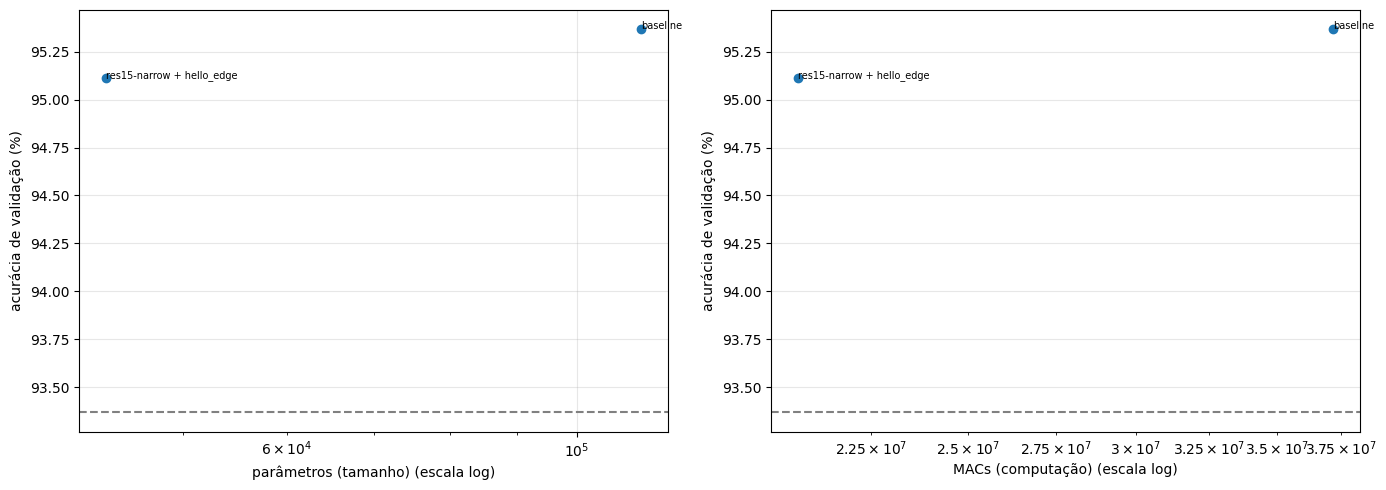

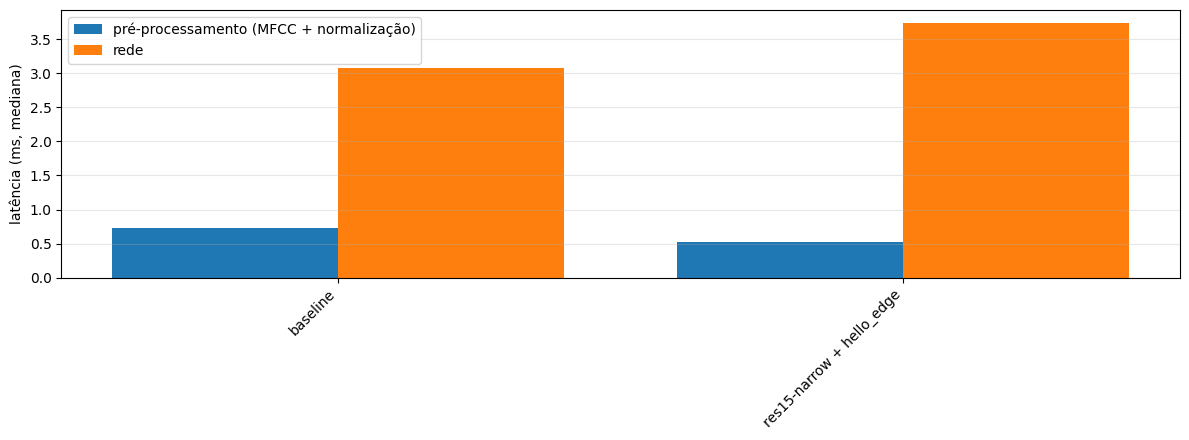

In [36]:
if VARRER_RESNET:
    #A tabela dos slides
    display(tabela_slide(resumo_resnet))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_resnet, hp_resnet["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_resnet)

In [37]:
if VARRER_RESNET:
    vencedor_resnet = escolher_vencedor(resumo_resnet)

    #Conferência: hp_modelos['resnet'] (§2, usado no resto do notebook) precisa ser exatamente o vencedor
    mudancas_vencedor = dict(CONFIGS_RESNET_RELATORIO)[vencedor_resnet]
    hp_vencedor = config("resnet")
    print("hp_modelos['resnet'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          {k: hp_vencedor[k] for k in mudancas_vencedor})

Menor modelo dentro de 2 p.p. do baseline: res15-narrow + hello_edge (43,640 parâmetros, 20,780,585 MACs)
hp_modelos['resnet'] usa o vencedor: True {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 19, 'n_blocos': 6, 'pool': None, 'dilatacao': True, 'conv_extra': True}


gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


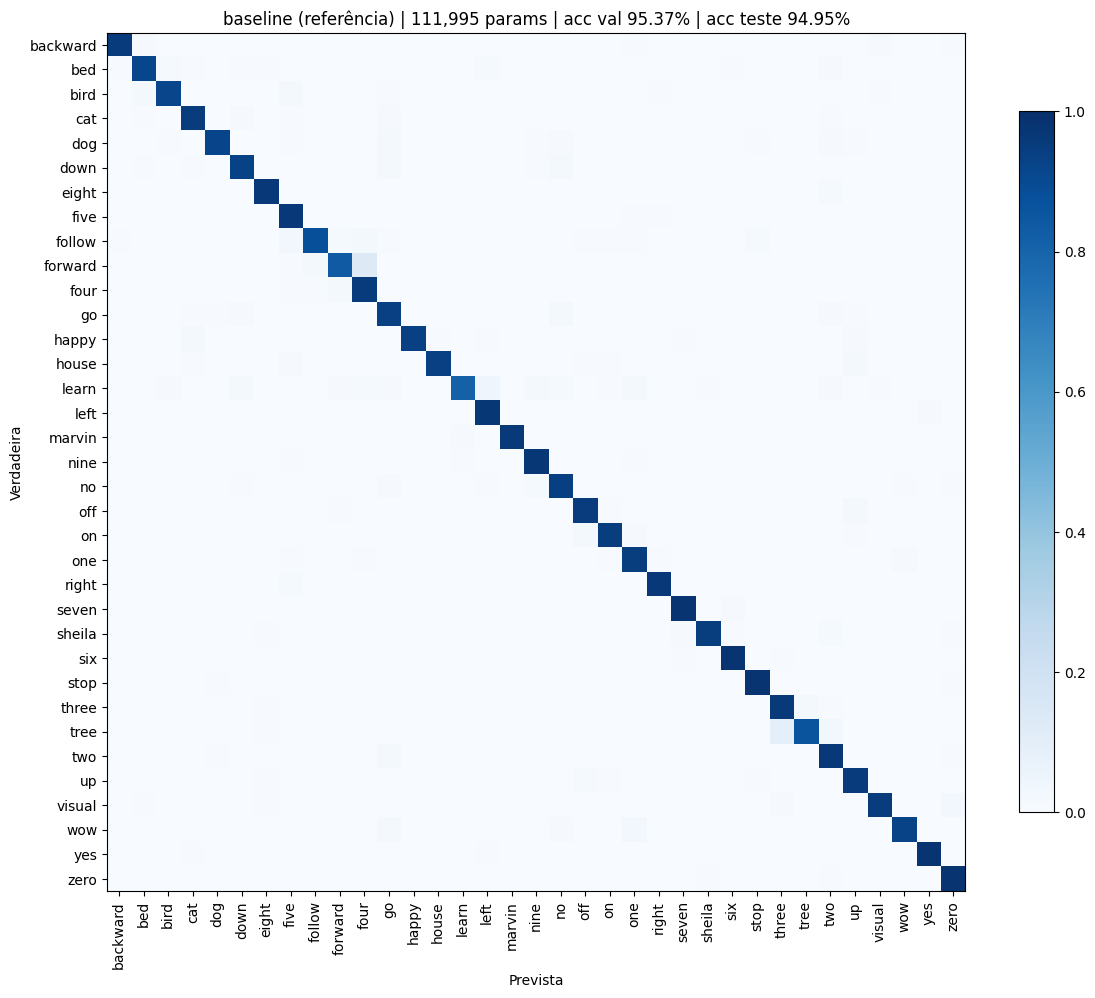

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


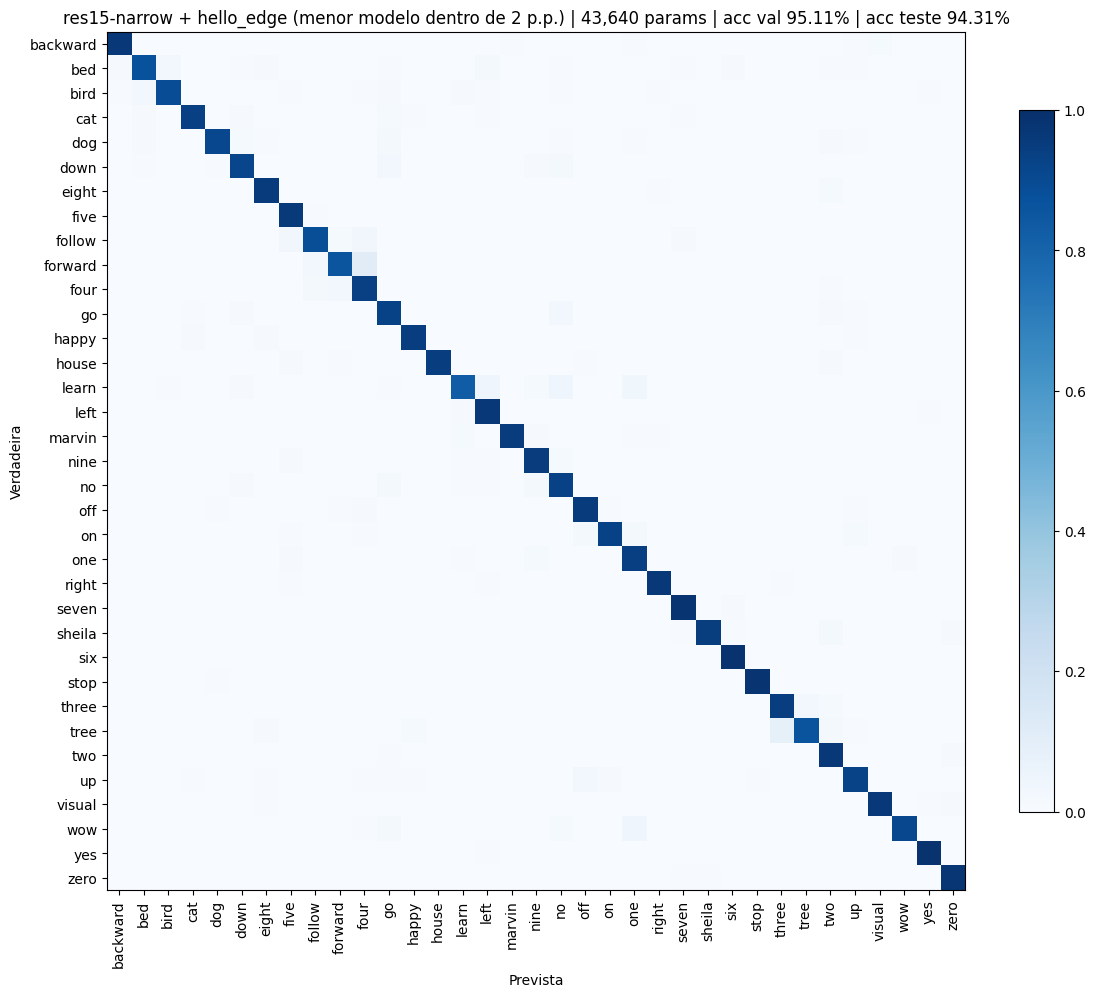

In [38]:
#Matrizes de confusão (no TESTE, somadas entre as seeds): o baseline e o vencedor
if VARRER_RESNET:
    matrizes_escolhidos(resumo_resnet, modelos_resnet, CONFIGS_RESNET_RELATORIO, hp_resnet, SEEDS, RAIZ_GSC,
                        PASTAS["cache"])

#### O que encontramos

Execução do [playground da ResNet](https://github.com/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb) (com as saídas salvas): GSC completo, 20 épocas com OneCycle, 3 seeds,
latência numa CPU Intel Xeon 2,2 GHz do Colab. As linhas **baseline** e **vencedor** foram substituídas pelos números
desta execução (early stop da §5, tabelas acima); as demais vêm do playground e não são diretamente comparáveis com
elas.

| Configuração | Entrada | Params | MACs | Acc val (%) | Acc teste (%) | MFCC / rede (ms) |
|---|---|---|---|---|---|---|
| baseline (res8, esta execução) | 40 × 101 | 111.995 | 37.176.525 | 95,37 ± 0,56 | 94,95 ± 0,62 | 0,72 / 3,07 |
| res15-narrow | 40 × 101 | 43.640 | 171.328.985 | 95,75 ± 0,10 | 95,19 ± 0,09 | 0,70 / 13,56 |
| res26-narrow | 40 × 101 | 79.797 | 78.667.505 | 95,40 ± 0,14 | 94,61 ± 0,18 | 0,71 / 6,32 |
| res8 + hello_edge | 10 × 49 | 111.995 | 4.136.625 | 94,30 ± 0,18 | 93,44 ± 0,18 | 0,51 / 0,90 |
| **res15-narrow + hello_edge (vencedor, esta execução)** | 10 × 49 | **43.640** | **20.780.585** | **95,11 ± 0,23** | **94,31 ± 0,03** | 0,52 / 3,74 |
| res26-narrow + hello_edge | 10 × 49 | 79.797 | 9.441.575 | 94,67 ± 0,09 | 93,87 ± 0,14 | 0,51 / 2,26 |
| res8-narrow | 40 × 101 | 20.631 | 7.027.055 | 92,89 ± 0,21 | 91,97 ± 0,13 | 0,69 / 1,26 |
| res8-narrow + hello_edge | 10 × 49 | 20.631 | 786.239 | 91,30 ± 0,21 | 89,98 ± 0,26 | 0,52 / 0,64 |
| res8 canais 12 | 40 × 101 | 8.507 | 2.963.940 | 89,38 ± 0,19 | 87,75 ± 0,49 | 0,68 / 0,95 |
| res8 canais 8 + hello_edge | 10 × 49 | 3.955 | 159.976 | 80,43 ± 0,47 | 78,66 ± 0,65 | 0,52 / 0,57 |

- **Vencedor:** res15-narrow + `hello_edge`, com **39% dos parâmetros** do res8 (43.640 contra 111.995), a
  −0,25 p.p. na validação com o early stop (−0,94 p.p. no playground). O baseline caiu um pouco (95,37 ± 0,56%):
  a seed 0 parou na época 21 com 94,75%, efeito da paciência curta (§5). No playground, o res15-narrow com a entrada 40 × 101 tem os mesmos parâmetros e fica a só −0,07 p.p.,
  mas o desempate pelos MACs escolhe a entrada `hello_edge`, que corta os MACs em ~8x (171 M → 20,8 M).
- **Profundidade compensa a largura, até um ponto (playground):** com 19 canais, o res8 (3 blocos) cai −2,9 p.p. e fica fora do
  critério, enquanto o res15 (6 blocos dilatados) quase empata com o baseline. Abaixo de 19 canais a acurácia
  desaba (12 canais: −6,4 p.p.; 8 canais: −13,6 p.p.).
- **Poucos parâmetros não é o mesmo que pouco cálculo:** sem pooling na entrada e com dilatação, o vencedor faz 5x
  os MACs do res8 + `hello_edge` (20,8 M contra 4,1 M) e a rede leva 3,7 ms contra 0,9 ms. Se o limite do
  dispositivo for latência, e não memória, o res8 + `hello_edge` (−1,52 p.p.) seria a escolha.
- **Treino (playground):** o SpecAugment ajuda (+0,60 p.p.) e o weight decay ajuda pouco (+0,20 p.p.). A normalização por
  amostra **piora** a ResNet (−0,52 p.p.), o contrário da CNN 1D.
- **Hipótese (b), já aqui:** na ResNet a **rede** custa mais que o pré-processamento em **todas** as configurações
  (pré-processamento / rede de 0,05x a 0,92x; 0,14x no vencedor), o oposto da CNN 1D. A resposta da (b) depende da
  família: com Conv2d sobre o MFCC inteiro, a rede domina.

### 8.4 DS-CNN: quanto dá para encolher

Convolução separável em profundidade (Hello Edge, Zhang et al. 2017), em `modelos/dscnn.py`, na versão
**DS-CNN-S** do artigo:
- o MFCC é tratado como imagem `(B, 1, tempo, frequência)`;
- uma convolução comum 10 × 4 com *stride* 2 (64 canais, *padding* SAME como no artigo), BatchNorm e ReLU;
- 4 blocos separáveis: *depthwise* 3 × 3 (um filtro por canal) + BN + ReLU, depois *pointwise* 1 × 1 (mistura os
  canais) + BN + ReLU. Separar as duas etapas custa ~8–9x menos parâmetros que uma convolução 3 × 3 comum;
- média global e `head` linear.

Sem playground: aqui roda a **varredura inteira** (`CONFIGS_DSCNN`, 12 configurações × `SEEDS`), com o loop da §5 e o
critério da §8:

| Grupo | Configurações |
|---|---|
| baseline | entrada 40 × 101, 64 canais, 4 blocos |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| menores | 32 e 16 canais, 2 blocos |
| entrada `hello_edge` (10 × 49) | 64 canais (a DS-CNN-S do artigo), 48, 32 e 16 canais, 2 blocos |

In [39]:
from treino.varredura import CONFIGS_DSCNN

#A varredura inteira: 12 configurações (baseline, 3 de treino, modelos menores e a entrada hello_edge)
hp_dscnn = config("dscnn", epocas=EPOCAS)
VARRER_DSCNN = RODAR_VARREDURAS and "dscnn" in MODELOS

if VARRER_DSCNN:
    tabela_dscnn, modelos_dscnn = rodar_varredura("dscnn", CONFIGS_DSCNN, hp_dscnn, SEEDS, RAIZ_GSC, PASTAS,
                                              retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.4: RODAR_VARREDURAS=False ou dscnn fora de MODELOS")

dscnn | seed 0:   0%|          | 0/12 [00:00<?, ?it/s, baseline]

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


dscnn | seed 0:   8%|▊         | 1/12 [00:05<01:03,  5.78s/it, sem spec_augment]

baseline (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/dscnn_baseline_s0_20261111-153838


dscnn | seed 0:  17%|█▋        | 2/12 [00:10<00:49,  4.91s/it, norm por_amostra]

sem spec_augment (seed 0): carregado de /content/drive/MyDrive/kws-borda/runs/dscnn_sem_spec_augment_s0_20261111-154416


... (73 outputs left out)

hello_edge + canais 16         |    3123 params | melhor acc val=84.64% (época 29) | 2.4 min


dscnn | seed 2:  92%|█████████▏| 11/12 [1:01:47<03:39, 219.09s/it, hello_edge + 2 blocos]

hello_edge + 2 blocos          |   14819 params | melhor acc val=91.91% (época 33) | 1.8 min


dscnn | seed 2: 100%|██████████| 12/12 [1:01:47<00:00, 308.99s/it, hello_edge + 2 blocos]


In [40]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_DSCNN:
    latencias_dscnn = medir_latencias_varredura("dscnn", CONFIGS_DSCNN, hp_dscnn)
    tabela_dscnn = anexar_latencias(tabela_dscnn, latencias_dscnn)
    resumo_dscnn = montar_resumo(tabela_dscnn, hp_dscnn["fracao"], hp_dscnn["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_dscnn[["experimento", "seed", "entrada", "canais", "n_blocos", "params", "macs", "acc_val",
                     "melhor_epoca", "epocas_treinadas", "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

baseline                   | MFCC 0.706 ms | norm 0.008 ms | rede 2.762 ms | preproc/rede 0.26x | estável: True | rede nas passadas: 2.806 / 2.762 / 2.780
sem spec_augment           | MFCC 0.717 ms | norm 0.008 ms | rede 2.766 ms | preproc/rede 0.26x | estável: True | rede nas passadas: 2.793 / 2.766 / 2.813
norm por_amostra           | MFCC 0.726 ms | norm 0.072 ms | rede 2.802 ms | preproc/rede 0.28x | estável: True | rede nas passadas: 2.835 / 2.811 / 2.802
sem weight_decay           | MFCC 0.718 ms | norm 0.008 ms | rede 2.760 ms | preproc/rede 0.26x | estável: True | rede nas passadas: 2.818 / 2.795 / 2.760
canais 32                  | MFCC 0.719 ms | norm 0.008 ms | rede 1.959 ms | preproc/rede 0.37x | estável: True | rede nas passadas: 2.043 / 1.994 / 1.959
canais 16                  | MFCC 0.720 ms | norm 0.008 ms | rede 1.664 ms | preproc/rede 0.44x | estável: True | rede nas passadas: 1.689 / 1.681 / 1.664
2 blocos                   | MFCC 0.723 ms | norm 0.008 ms | rede 1.65

,experimento,seed,entrada,canais,n_blocos,params,macs,acc_val,melhor_epoca,epocas_treinadas,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,64,4,24675,21675200,0.9506,40,40.0,-0.0976,0.9470,0.9422,0.7056,2.7621,11.3914
1,sem spec_augment,0,40x101,64,4,24675,21675200,0.9381,16,20.0,0.0309,0.9341,0.9294,0.7171,2.7660,5.5819
2,norm por_amostra,0,40x101,64,4,24675,21675200,0.9477,46,46.0,-0.0692,0.9396,0.9334,0.7258,2.8016,13.1306
3,sem weight_decay,0,40x101,64,4,24675,21675200,0.9495,34,39.0,-0.0937,0.9444,0.9402,0.7181,2.7604,11.1263
4,canais 32,0,40x101,32,4,8259,6659680,0.9221,28,33.0,-0.1626,0.9101,0.9038,0.7187,1.9593,3.5917
5,canais 16,0,40x101,16,4,3123,2285360,0.8623,40,41.0,-0.2044,0.8451,0.8306,0.7200,1.6638,3.2312
6,2 blocos,0,40x101,64,2,14819,12144320,0.9231,50,50.0,-0.1515,0.9121,0.9037,0.7235,1.6530,8.2019
7,entrada hello_edge,0,10x49,64,4,24675,2658240,0.9377,23,26.0,-0.1880,0.9308,0.9239,0.5268,1.5910,1.7611
8,hello_edge + canais 48,0,10x49,48,4,15443,1609680,0.9337,40,45.0,-0.1974,0.9280,0.9218,0.5083,1.5242,3.0997
9,hello_edge + canais 32,0,10x49,32,4,8259,817120,0.9167,41,41.0,-0.2473,0.8998,0.8896,0.5051,1.4743,2.8330


,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,24675,24.1,21675200,94.48 ± 0.78,93.64 ± 1.14,93.03 ± 1.22,0.706,2.762,0.26,0.00,True
sem spec_augment,40x101,24675,24.1,21675200,93.85 ± 0.18,93.43 ± 0.04,92.86 ± 0.08,0.717,2.766,0.26,-0.63,True
norm por_amostra,40x101,24675,24.1,21675200,94.39 ± 0.35,93.72 ± 0.25,93.08 ± 0.26,0.726,2.802,0.28,-0.09,True
sem weight_decay,40x101,24675,24.1,21675200,94.97 ± 0.12,94.23 ± 0.19,93.77 ± 0.22,0.718,2.760,0.26,0.49,True
canais 32,40x101,8259,8.1,6659680,92.16 ± 0.46,91.11 ± 0.40,90.38 ± 0.35,0.719,1.959,0.37,-2.32,False
canais 16,40x101,3123,3.0,2285360,86.04 ± 0.19,84.69 ± 0.16,83.16 ± 0.20,0.720,1.664,0.44,-8.44,False
2 blocos,40x101,14819,14.5,12144320,92.09 ± 0.38,91.12 ± 0.24,90.31 ± 0.17,0.723,1.653,0.44,-2.39,False
entrada hello_edge,10x49,24675,24.1,2658240,94.08 ± 0.30,93.41 ± 0.31,92.79 ± 0.37,0.527,1.591,0.34,-0.40,True
hello_edge + canais 48,10x49,15443,15.1,1609680,93.57 ± 0.19,92.76 ± 0.15,92.15 ± 0.11,0.508,1.524,0.34,-0.91,True


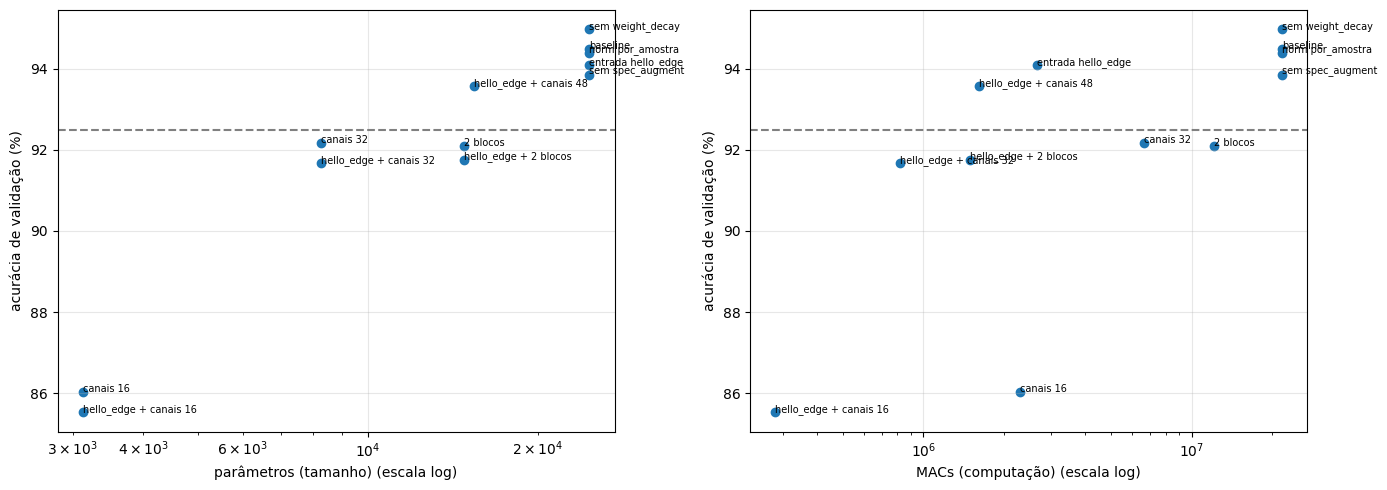

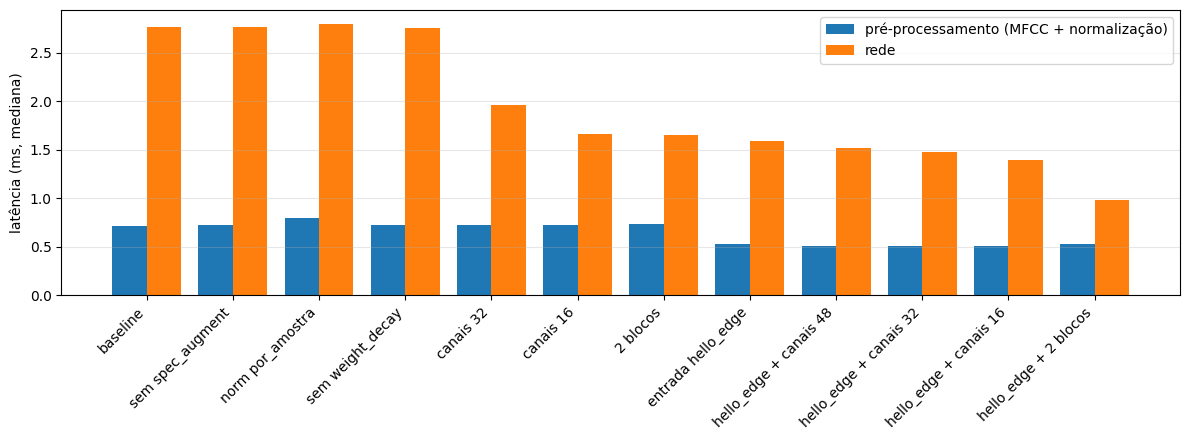

In [41]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

if VARRER_DSCNN:
    #A tabela dos slides
    display(tabela_slide(resumo_dscnn))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_dscnn, hp_dscnn["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_dscnn)

In [42]:
if VARRER_DSCNN:
    vencedor_dscnn = escolher_vencedor(resumo_dscnn)

    #Conferência: hp_modelos['dscnn'] (§2, usado no resto do notebook) deve ser o vencedor.
    #Se der False, copie as mudanças impressas para hp_modelos['dscnn'] (§2) e para configs/__init__.py
    mudancas_vencedor = dict(CONFIGS_DSCNN)[vencedor_dscnn]
    hp_vencedor = config("dscnn")
    print("hp_modelos['dscnn'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          mudancas_vencedor)

Menor modelo dentro de 2 p.p. do baseline: hello_edge + canais 48 (15,443 parâmetros, 1,609,680 MACs)
hp_modelos['dscnn'] usa o vencedor: False {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'canais': 48, 'n_blocos': 4}


gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


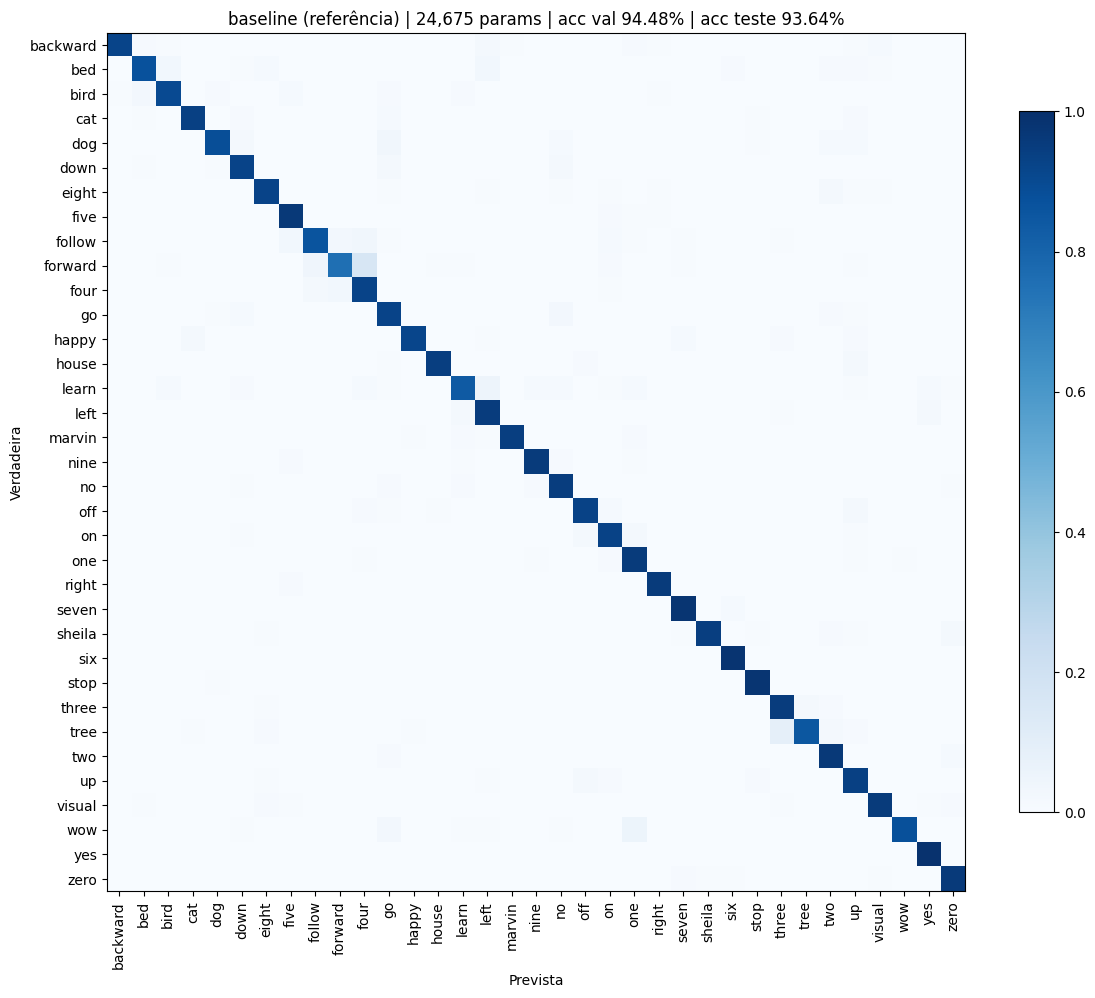

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


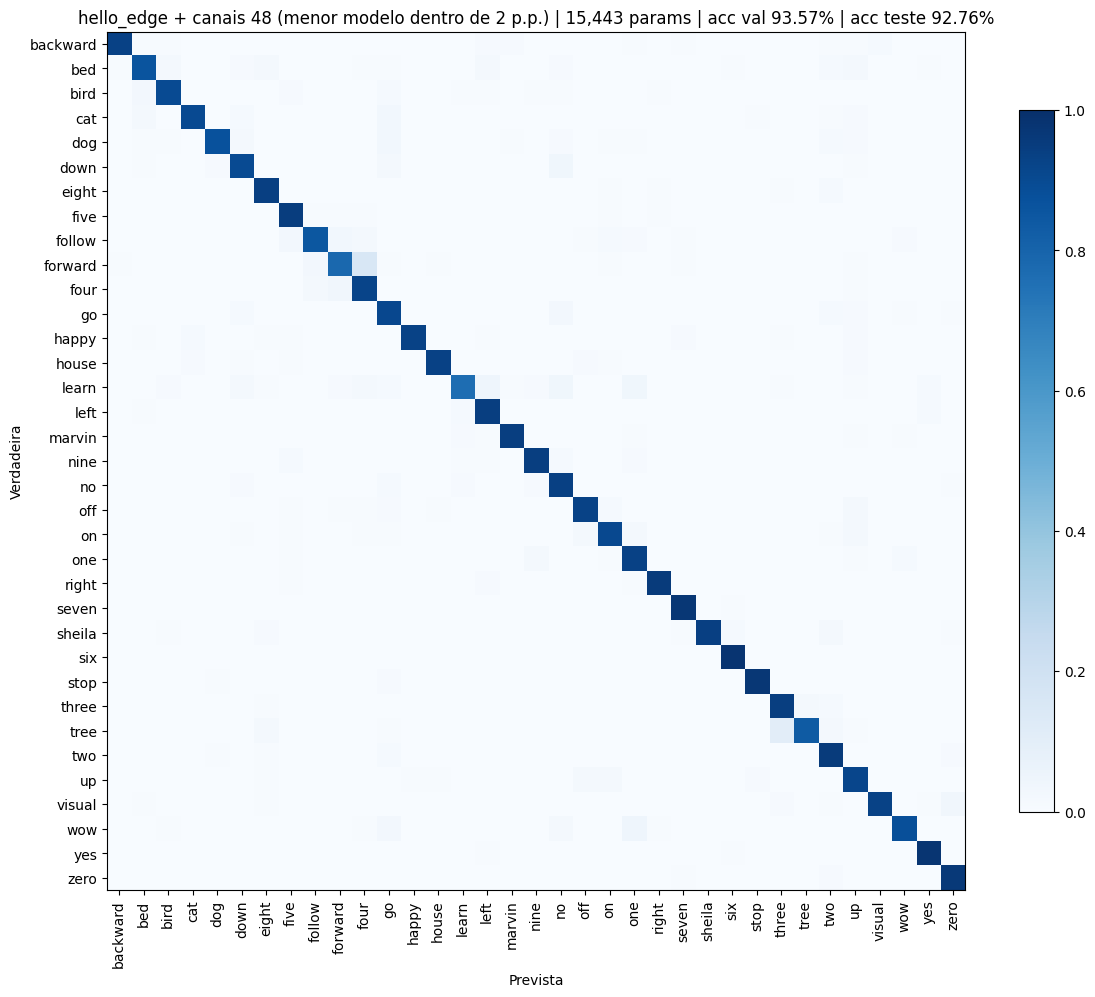

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


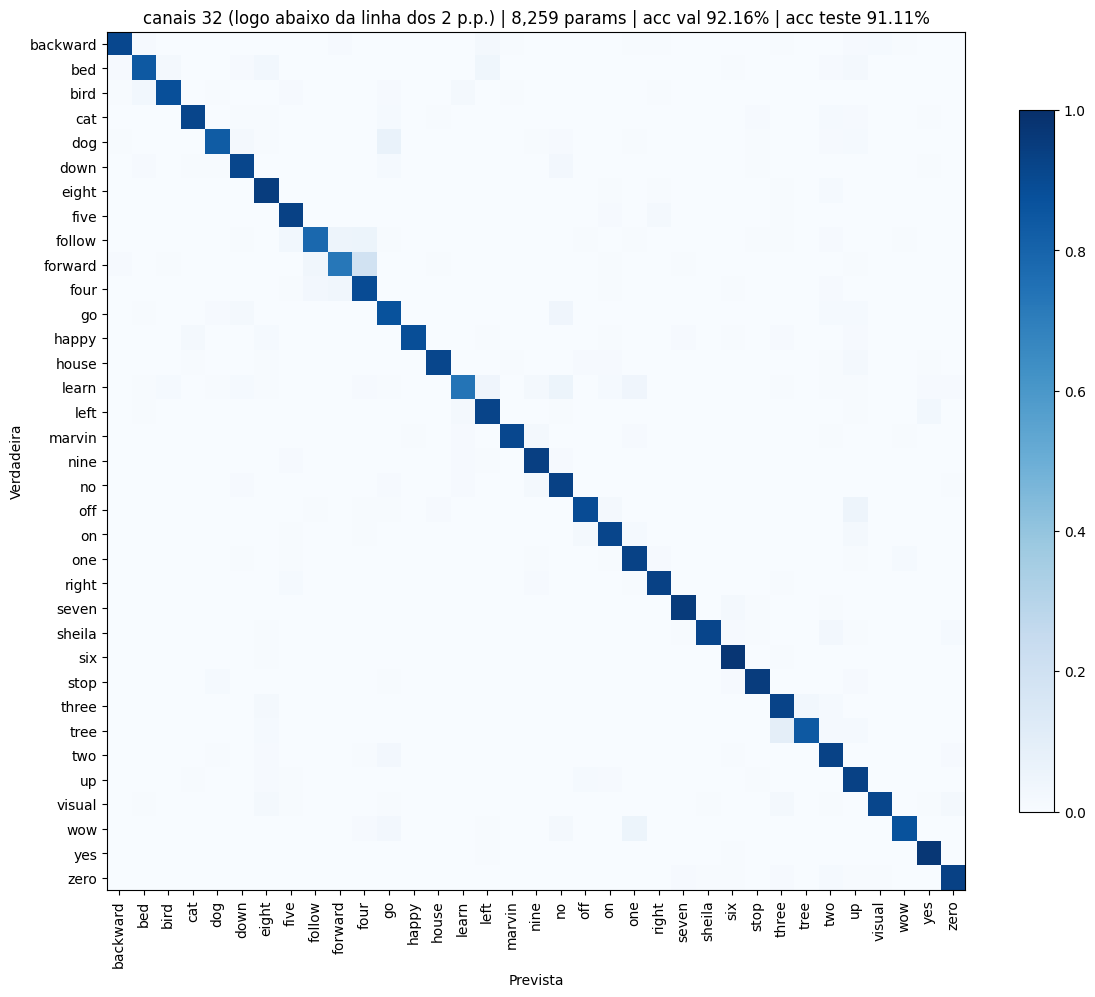

In [43]:
#Matrizes de confusão (no TESTE, somadas entre as seeds) de 3 configurações escolhidas pela VALIDAÇÃO:
#o baseline, o vencedor e o que ficou logo abaixo da linha dos 2 p.p.
if VARRER_DSCNN:
    matrizes_escolhidos(resumo_dscnn, modelos_dscnn, CONFIGS_DSCNN, hp_dscnn, SEEDS, RAIZ_GSC, PASTAS["cache"])

#### O que encontramos

Execução no Colab (L4), early stop da §5 (teto 50, paciência 5), 3 seeds. Números da tabela dos slides acima.

| Configuração | Entrada | Params | MACs | Acc val (%) | Dif. val (p.p.) | Acc teste (%) |
|---|---|---|---|---|---|---|
| baseline | 40 × 101 | 24.675 | 21.675.200 | 94,48 ± 0,78 | 0,00 | 93,64 ± 1,14 |
| sem weight_decay | 40 × 101 | 24.675 | 21.675.200 | 94,97 ± 0,12 | +0,49 | 94,23 ± 0,19 |
| canais 32 | 40 × 101 | 8.259 | 6.659.680 | 92,16 ± 0,46 | −2,32 | 91,11 ± 0,40 |
| 2 blocos | 40 × 101 | 14.819 | 12.144.320 | 92,09 ± 0,38 | −2,39 | 91,12 ± 0,24 |
| canais 16 | 40 × 101 | 3.123 | 2.285.360 | 86,04 ± 0,19 | −8,44 | 84,69 ± 0,16 |
| entrada hello_edge (64, DS-CNN-S) | 10 × 49 | 24.675 | 2.658.240 | 94,08 ± 0,30 | −0,40 | 93,41 ± 0,31 |
| **hello_edge + canais 48 (vencedor)** | 10 × 49 | **15.443** | **1.609.680** | **93,57 ± 0,19** | **−0,91** | **92,76 ± 0,15** |
| hello_edge + canais 32 | 10 × 49 | 8.259 | 817.120 | 91,66 ± 0,19 | −2,82 | 90,25 ± 0,41 |
| hello_edge + 2 blocos | 10 × 49 | 14.819 | 1.490.240 | 91,76 ± 0,18 | −2,72 | 90,75 ± 0,17 |
| hello_edge + canais 16 | 10 × 49 | 3.123 | 280.560 | 85,53 ± 0,77 | −8,95 | 83,93 ± 0,75 |

- **A entrada menor sai quase de graça:** os parâmetros não mudam (a rede é convolucional), mas os MACs caem ~8x
  (21,7 M → 2,7 M) por −0,40 p.p. na validação.
- **Vencedor:** `hello_edge` + 48 canais, com **15,4 mil parâmetros** (15,1 KB em int8) e 1,6 M de MACs, a −0,91 p.p.
  É a família mais compacta para essa acurácia: menos parâmetros que a CNN 1D vencedora (24 mil) com +0,5 p.p. de
  validação, embora com ~4x mais MACs.
- **A margem de 2 p.p. é estreita:** 32 canais e 2 blocos já ficam fora por pouco (−2,3 a −2,8 p.p.), e 16 canais
  desaba (−8,4 a −9,0 p.p.).
- **Treino:** tirar o weight decay foi a **melhor** configuração (+0,49 p.p.). O SpecAugment ajuda (sem ele:
  −0,63) e a normalização por amostra é neutra (−0,09). O desvio do baseline (± 0,78) é maior que essas diferenças.
- **Hipótese (b), já aqui:** a **rede** custa mais que o pré-processamento em todas as configurações
  (pré-processamento / rede de 0,26x a 0,54x), como na ResNet: são as convoluções 2D sobre o MFCC que dominam.
- Da §5 à §9 a DS-CNN usa 64 canais (a DS-CNN-S do artigo), não o vencedor.

### 8.5 Atenção (KWT): quanto dá para encolher

Keyword Transformer (Berg et al. 2021), em `modelos/atencao.py`:
- cada janela do MFCC vira um *token*, projetado linearmente para `d_model` = 64;
- um token `[CLS]` aprendido no início e um *embedding* posicional aprendido;
- 3 camadas de *encoder* Transformer com 1 cabeça de atenção, *feed-forward* `d_model` → 4 × `d_model` →
  `d_model`, GELU, PostNorm (como no KWT) e sem dropout;
- a saída do `[CLS]` vai para a `head` linear.

Treina com lr 1e-3 (Transformers costumam pedir lr menor que as convolucionais). A entrada `hello_edge` também
reduz o número de *tokens* (101 → 49), e o custo da autoatenção cresce com o quadrado dele.

Sem playground: aqui roda a **varredura inteira** (`CONFIGS_ATENCAO`, 12 configurações × `SEEDS`), com o loop da §5 e o
critério da §8:

| Grupo | Configurações |
|---|---|
| baseline | entrada 40 × 101 (101 tokens), d_model 64, 3 camadas, 1 cabeça |
| treino | sem SpecAugment, normalização por amostra, sem weight decay |
| menores | d_model 32 e 16, 2 camadas e 1 camada |
| entrada `hello_edge` (10 × 49, 49 tokens) | d_model 64, 32 e 16, 1 camada |

In [44]:
from treino.varredura import CONFIGS_ATENCAO

#A varredura inteira: 12 configurações (baseline, 3 de treino, modelos menores e a entrada hello_edge)
hp_atencao = config("atencao", epocas=EPOCAS)
VARRER_ATENCAO = RODAR_VARREDURAS and "atencao" in MODELOS

if VARRER_ATENCAO:
    tabela_atencao, modelos_atencao = rodar_varredura("atencao", CONFIGS_ATENCAO, hp_atencao, SEEDS, RAIZ_GSC, PASTAS,
                                              retreinar=RETREINAR, device=device)
else:
    print("[pulando] §8.5: RODAR_VARREDURAS=False ou atencao fora de MODELOS")

atencao | seed 0:   0%|          | 0/12 [00:00<?, ?it/s, baseline]/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(
atencao | seed 0:   0%|          | 0/12 [03:34<?, ?it/s, baseline]

baseline                       |  161443 params | melhor acc val=93.84% (época 25) | 3.6 min


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(
atencao | seed 0:   8%|▊         | 1/12 [06:37<39:25, 215.09s/it, sem spec_augment]

sem spec_augment               |  161443 params | melhor acc val=92.46% (época 22) | 3.0 min


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(
atencao | seed 0:  17%|█▋        | 2/12 [10:20<32:42, 196.29s/it, norm por_amostra]

norm por_amostra               |  161443 params | melhor acc val=91.08% (época 31) | 3.7 min


... (73 outputs left out)

hello_edge + d_model 16        |   11427 params | melhor acc val=86.58% (época 46) | 4.9 min


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(
atencao | seed 2:  92%|█████████▏| 11/12 [50:14<04:20, 260.15s/it, hello_edge + 1 camada]

hello_edge + 1 camada          |   56227 params | melhor acc val=36.52% (época 30) | 1.8 min


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(
atencao | seed 2: 100%|██████████| 12/12 [50:14<00:00, 251.25s/it, hello_edge + 1 camada]


In [45]:
#Latência de cada configuração (CPU, 1 thread, batch 1) e o resumo por configuração (média ± desvio entre as seeds)
if VARRER_ATENCAO:
    latencias_atencao = medir_latencias_varredura("atencao", CONFIGS_ATENCAO, hp_atencao)
    tabela_atencao = anexar_latencias(tabela_atencao, latencias_atencao)
    resumo_atencao = montar_resumo(tabela_atencao, hp_atencao["fracao"], hp_atencao["margem_pp"])

    #Todos os treinos, um por linha
    display(tabela_atencao[["experimento", "seed", "entrada", "d_model", "n_camadas", "n_heads", "params", "macs", "acc_val",
                     "melhor_epoca", "epocas_treinadas", "gap", "acc_teste", "f1_teste", "mfcc_ms", "rede_ms", "tempo_min"]].round(4))

baseline                   | MFCC 0.712 ms | norm 0.008 ms | rede 2.125 ms | preproc/rede 0.34x | estável: True | rede nas passadas: 2.125 / 2.166 / 2.161
sem spec_augment           | MFCC 0.724 ms | norm 0.008 ms | rede 2.157 ms | preproc/rede 0.34x | estável: True | rede nas passadas: 2.166 / 2.165 / 2.157
norm por_amostra           | MFCC 0.719 ms | norm 0.072 ms | rede 2.145 ms | preproc/rede 0.37x | estável: True | rede nas passadas: 2.145 / 2.164 / 2.152
sem weight_decay           | MFCC 0.716 ms | norm 0.008 ms | rede 2.146 ms | preproc/rede 0.34x | estável: True | rede nas passadas: 2.160 / 2.146 / 2.153
d_model 32                 | MFCC 0.713 ms | norm 0.008 ms | rede 1.647 ms | preproc/rede 0.44x | estável: True | rede nas passadas: 1.685 / 1.663 / 1.647
d_model 16                 | MFCC 0.710 ms | norm 0.008 ms | rede 1.481 ms | preproc/rede 0.48x | estável: True | rede nas passadas: 1.491 / 1.481 / 1.489
2 camadas                  | MFCC 0.715 ms | norm 0.008 ms | rede 1.48

,experimento,seed,entrada,d_model,n_camadas,n_heads,params,macs,acc_val,melhor_epoca,epocas_treinadas,gap,acc_teste,f1_teste,mfcc_ms,rede_ms,tempo_min
0,baseline,0,40x101,64,3,1,161443,15301312,0.9384,25,30,0.0284,0.9296,0.9237,0.7124,2.1255,3.5560
1,sem spec_augment,0,40x101,64,3,1,161443,15301312,0.9246,22,27,0.2251,0.9120,0.9015,0.7238,2.1568,3.0237
2,norm por_amostra,0,40x101,64,3,1,161443,15301312,0.9108,31,31,0.0532,0.9066,0.8980,0.7190,2.1450,3.6791
3,sem weight_decay,0,40x101,64,3,1,161443,15301312,0.9291,27,28,-0.0087,0.9164,0.9087,0.7155,2.1460,3.3243
4,d_model 32,0,40x101,32,3,1,43875,3890528,0.9207,43,47,-0.0431,0.9103,0.9011,0.7126,1.6470,5.5864
5,d_model 16,0,40x101,16,3,1,12739,1005232,0.9045,50,50,-0.1586,0.8923,0.8815,0.7104,1.4811,5.9833
6,2 camadas,0,40x101,64,2,1,111459,10287808,0.9194,39,43,0.0082,0.9106,0.9009,0.7151,1.4890,4.1281
7,1 camada,0,40x101,64,1,1,61475,5274304,0.4563,18,19,-0.0414,0.4303,0.4110,0.7093,0.8152,1.3172
8,entrada hello_edge,0,10x49,64,3,1,156195,7406400,0.9346,43,47,-0.0771,0.9285,0.9227,0.5204,1.7495,5.2785
9,hello_edge + d_model 32,0,10x49,32,3,1,41251,1860000,0.9233,50,50,-0.1869,0.9148,0.9095,0.5115,1.4288,5.6463


,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,161443,157.7,15301312,93.61 ± 0.66,92.93 ± 0.51,92.26 ± 0.55,0.712,2.125,0.34,0.00,True
sem spec_augment,40x101,161443,157.7,15301312,90.66 ± 1.58,89.30 ± 1.65,88.21 ± 1.68,0.724,2.157,0.34,-2.96,False
norm por_amostra,40x101,161443,157.7,15301312,92.17 ± 1.01,91.21 ± 0.49,90.42 ± 0.56,0.719,2.145,0.37,-1.44,True
sem weight_decay,40x101,161443,157.7,15301312,93.37 ± 1.00,92.25 ± 0.95,91.54 ± 1.05,0.716,2.146,0.34,-0.24,True
d_model 32,40x101,43875,42.8,3890528,93.20 ± 1.00,92.37 ± 1.18,91.62 ± 1.34,0.713,1.647,0.44,-0.41,True
d_model 16,40x101,12739,12.4,1005232,89.98 ± 0.43,88.91 ± 0.54,87.82 ± 0.61,0.710,1.481,0.48,-3.63,False
2 camadas,40x101,111459,108.8,10287808,90.85 ± 0.97,89.63 ± 1.27,88.62 ± 1.30,0.715,1.489,0.49,-2.77,False
1 camada,40x101,61475,60.0,5274304,45.96 ± 0.43,43.14 ± 0.11,41.27 ± 0.19,0.709,0.815,0.88,-47.65,False
entrada hello_edge,10x49,156195,152.5,7406400,93.43 ± 0.33,92.78 ± 0.18,92.14 ± 0.25,0.520,1.749,0.30,-0.18,True


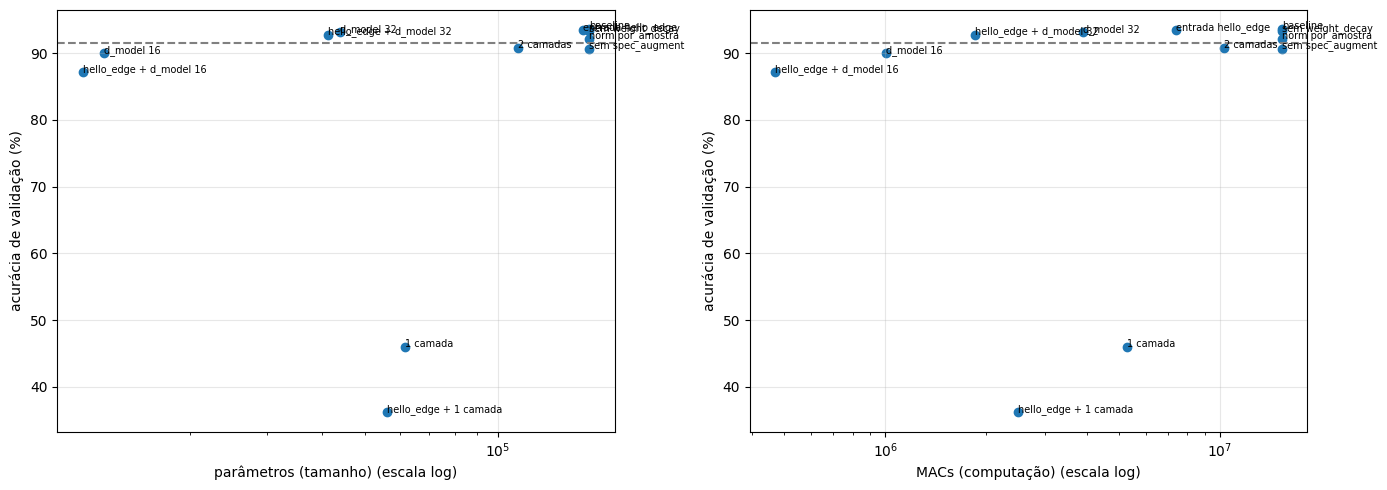

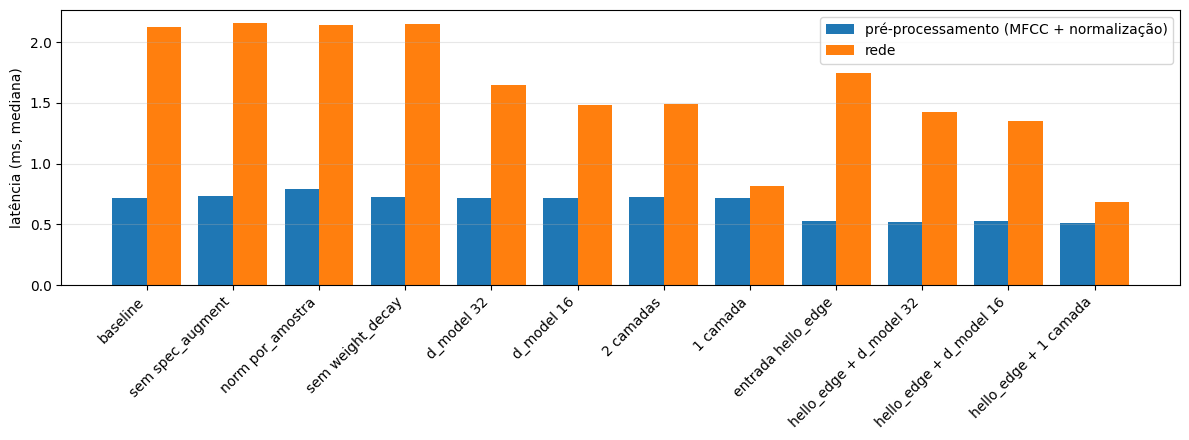

In [46]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

if VARRER_ATENCAO:
    #A tabela dos slides
    display(tabela_slide(resumo_atencao))

    #Acurácia × custo, com o piso do critério de 2 p.p.
    acuracia_vs_custo_varredura(resumo_atencao, hp_atencao["margem_pp"])

    #Hipótese (b) dentro da varredura: pré-processamento × rede
    barras_preproc_rede(resumo_atencao)

In [47]:
if VARRER_ATENCAO:
    vencedor_atencao = escolher_vencedor(resumo_atencao)

    #Conferência: hp_modelos['atencao'] (§2, usado no resto do notebook) deve ser o vencedor.
    #Se der False, copie as mudanças impressas para hp_modelos['atencao'] (§2) e para configs/__init__.py
    mudancas_vencedor = dict(CONFIGS_ATENCAO)[vencedor_atencao]
    hp_vencedor = config("atencao")
    print("hp_modelos['atencao'] usa o vencedor:", all(hp_vencedor[k] == v for k, v in mudancas_vencedor.items()),
          mudancas_vencedor)

Menor modelo dentro de 2 p.p. do baseline: hello_edge + d_model 32 (41,251 parâmetros, 1,860,000 MACs)
hp_modelos['atencao'] usa o vencedor: False {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False, 'd_model': 32, 'n_camadas': 3, 'n_heads': 1, 'dropout': 0}


gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


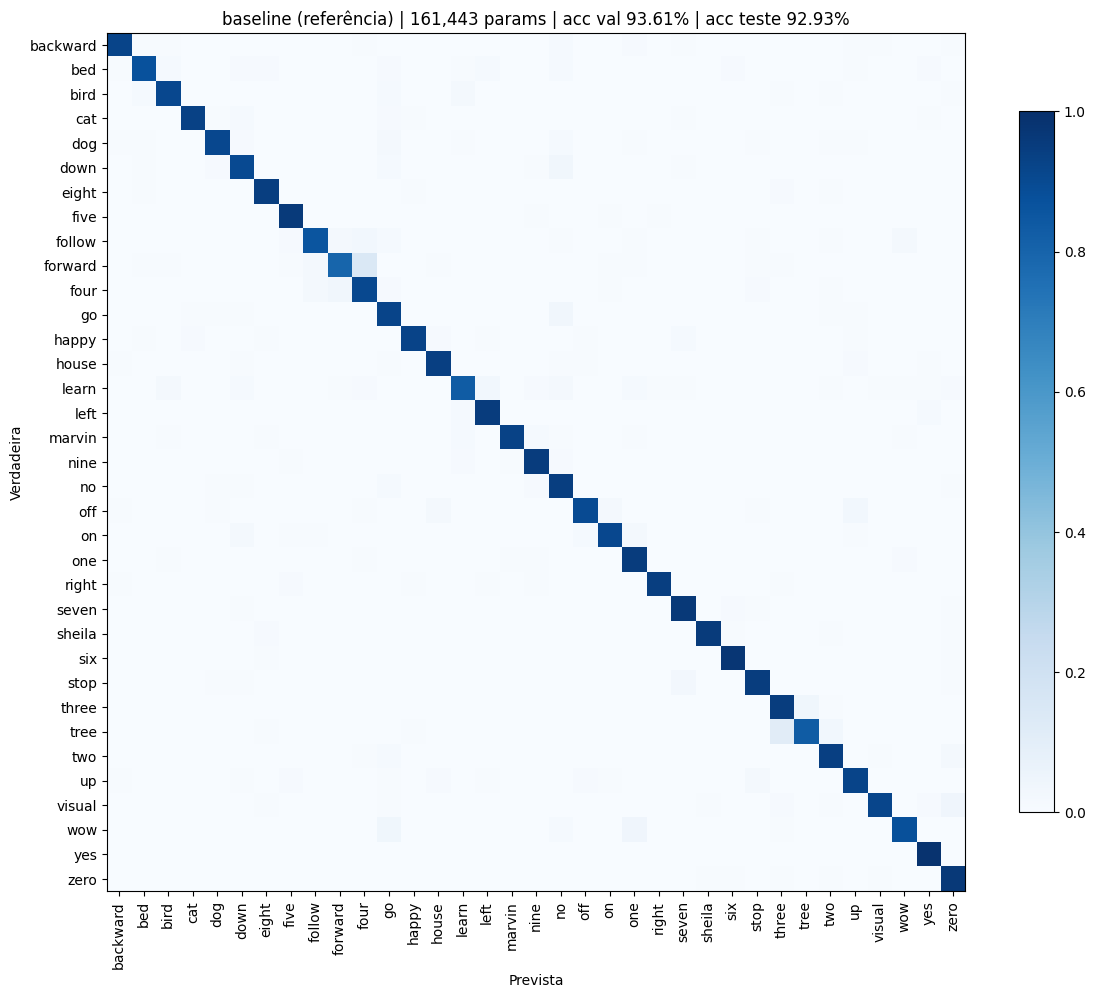

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


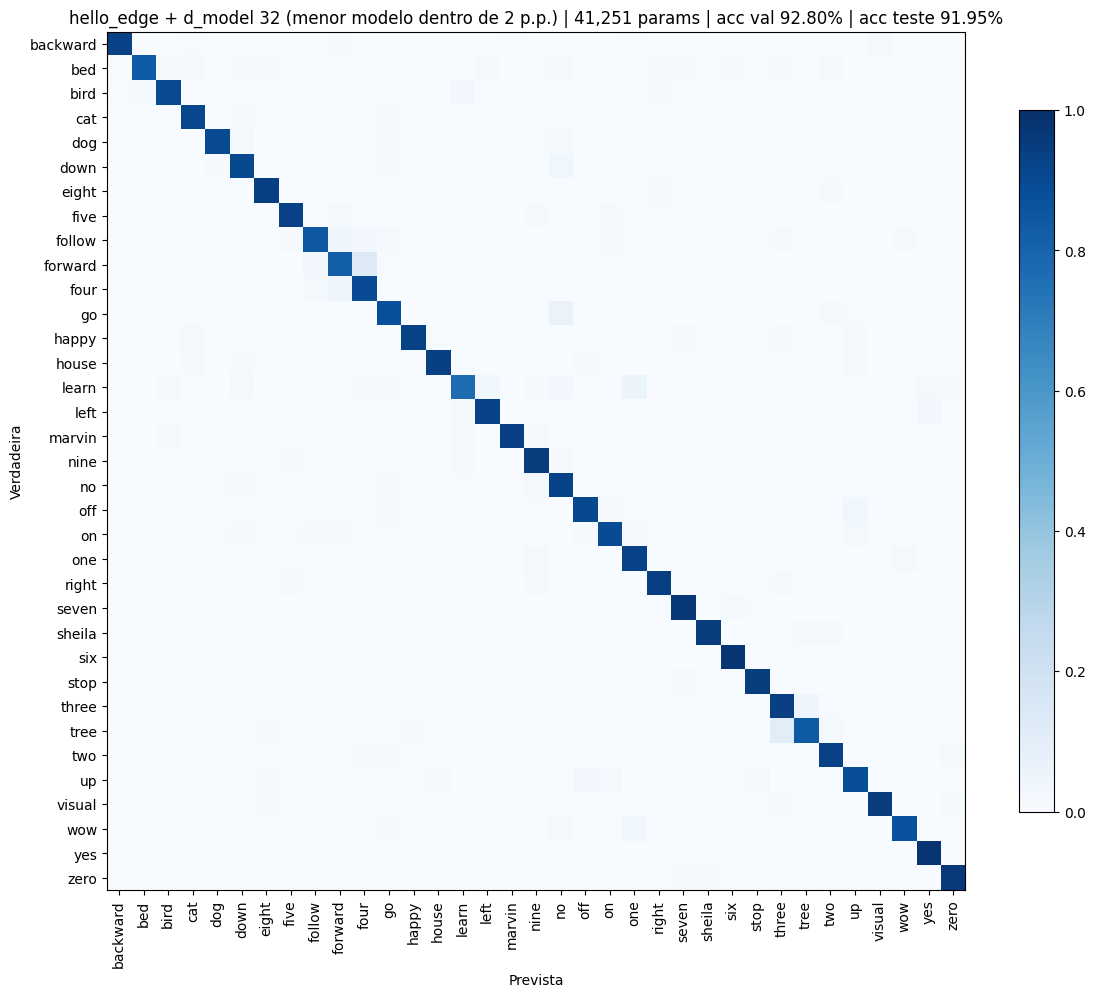

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


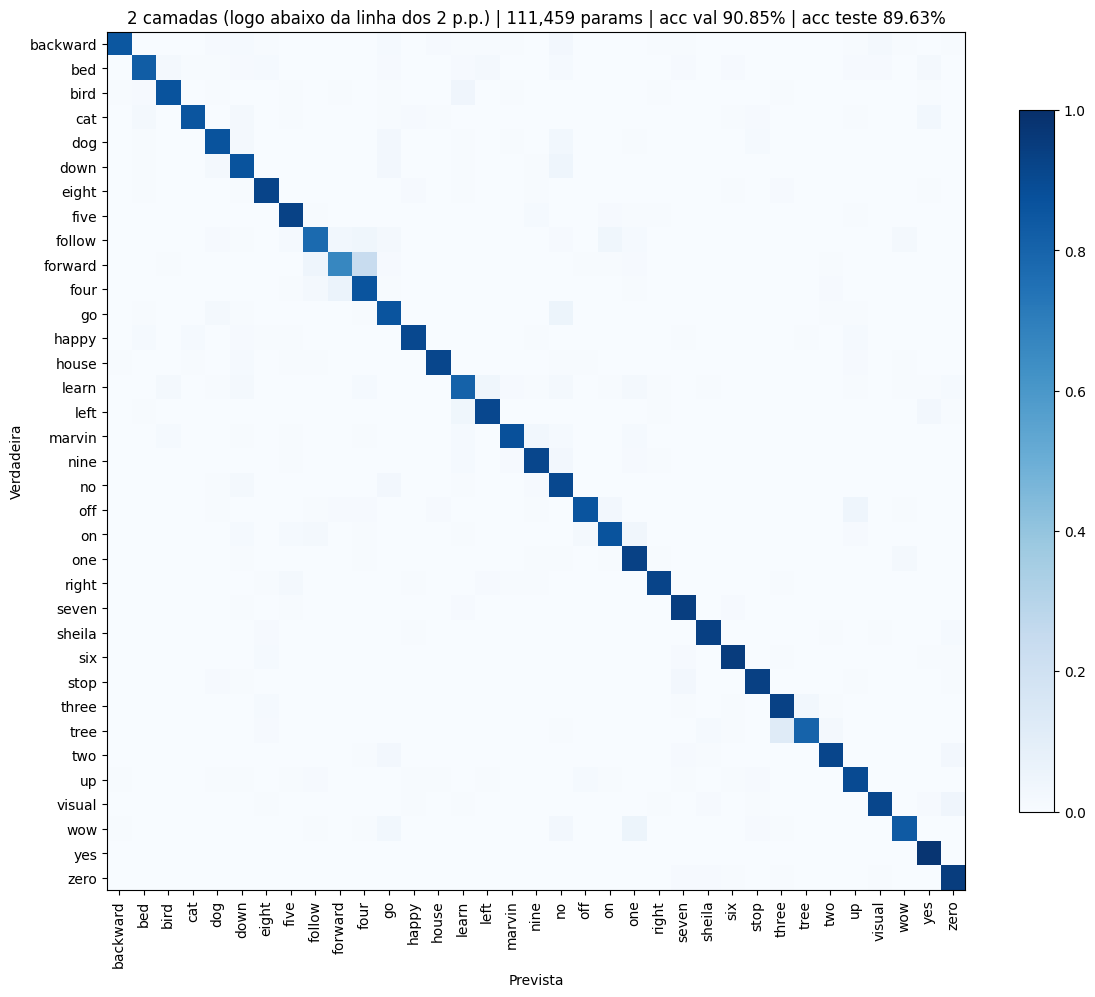

In [48]:
#Matrizes de confusão (no TESTE, somadas entre as seeds) de 3 configurações escolhidas pela VALIDAÇÃO:
#o baseline, o vencedor e o que ficou logo abaixo da linha dos 2 p.p.
if VARRER_ATENCAO:
    matrizes_escolhidos(resumo_atencao, modelos_atencao, CONFIGS_ATENCAO, hp_atencao, SEEDS, RAIZ_GSC, PASTAS["cache"])

#### O que encontramos

Execução no Colab (L4), early stop da §5 (teto 50, paciência 5), 3 seeds. Números da tabela dos slides acima.

| Configuração | Entrada | Params | MACs | Acc val (%) | Dif. val (p.p.) | Acc teste (%) |
|---|---|---|---|---|---|---|
| baseline (d_model 64, 3 camadas) | 40 × 101 | 161.443 | 15.301.312 | 93,61 ± 0,66 | 0,00 | 92,93 ± 0,51 |
| d_model 32 | 40 × 101 | 43.875 | 3.890.528 | 93,20 ± 1,00 | −0,41 | 92,37 ± 1,18 |
| d_model 16 | 40 × 101 | 12.739 | 1.005.232 | 89,98 ± 0,43 | −3,63 | 88,91 ± 0,54 |
| 2 camadas | 40 × 101 | 111.459 | 10.287.808 | 90,85 ± 0,97 | −2,77 | 89,63 ± 1,27 |
| 1 camada | 40 × 101 | 61.475 | 5.274.304 | 45,96 ± 0,43 | −47,65 | 43,14 ± 0,11 |
| entrada hello_edge | 10 × 49 | 156.195 | 7.406.400 | 93,43 ± 0,33 | −0,18 | 92,78 ± 0,18 |
| **hello_edge + d_model 32 (vencedor)** | 10 × 49 | **41.251** | **1.860.000** | **92,80 ± 0,48** | **−0,81** | **91,95 ± 0,41** |
| hello_edge + d_model 16 | 10 × 49 | 11.427 | 469.200 | 87,16 ± 0,51 | −6,45 | 86,05 ± 0,42 |
| hello_edge + 1 camada | 10 × 49 | 56.227 | 2.491.200 | 36,15 ± 1,29 | −57,47 | 35,67 ± 1,61 |

- **A entrada menor quase não custa:** 49 *tokens* em vez de 101 perdem só −0,18 p.p. e cortam os MACs pela metade
  (15,3 M → 7,4 M).
- **Vencedor:** `hello_edge` + d_model 32, com **41 mil parâmetros** (1/4 do baseline) e 1,9 M de MACs (1/8), a
  −0,81 p.p. Da §5 à §9 a Atenção usa o baseline (40 × 101, d_model 64), não o vencedor.
- **A largura cede mais que a profundidade:** d_model 32 perde pouco (−0,4 a −0,8 p.p.), mas tirar camadas pesa
  (2 camadas: −2,8 p.p.).
- **1 camada colapsa** (36–46%, nas 3 seeds e nas duas entradas). Uma queda tão grande, e muito maior que a de
  2 camadas, sugere um problema de otimização (lr, PostNorm) e não falta de capacidade: vale investigar antes de
  tirar conclusões sobre a profundidade.
- **Treino:** o KWT é a família que mais depende do SpecAugment (sem ele: −2,96 p.p.). A normalização por amostra
  piora (−1,44) e o weight decay quase não muda (sem ele: −0,24). Os desvios entre seeds (até ± 1,6) são os maiores
  entre as famílias.
- **Hipótese (b), já aqui:** a **rede** custa mais que o pré-processamento em todas as configurações
  (pré-processamento / rede de 0,30x a 0,88x).

## 9. Resumo

Os modelos de `MODELOS` lado a lado: acurácia e F1 no teste (média entre as seeds), tamanho, MACs e latência.

In [49]:
#Comparação entre as famílias: teste (§6), custo (§4.1) e latência (§7) numa tabela só
if len(resultados_gsc):
    comparacao = resultados_gsc
    if len(latencia):
        comparacao = comparacao.merge(latencia[["modelo", "mfcc_ms", "norm_ms", "rede_ms"]], on="modelo")
    display(comparacao.round(4))

,modelo,dataset,acc_mean,acc_std,acc_count,f1_mean,f1_std,f1_count,entrada,params,kb_fp32,kb_int8,macs,mfcc_ms,norm_ms,rede_ms
0,atencao,gsc_v2,0.9306,0.0062,3,0.9243,0.0060,3,40x101,161443,630.6367,157.6592,15301312,0.6911,0.0084,2.1764
1,cnn1d,gsc_v2,0.9153,0.0069,3,0.9081,0.0077,3,10x49,24275,94.8242,23.7061,383280,0.5337,0.0066,0.3712
2,dscnn,gsc_v2,0.9333,0.0018,3,0.9280,0.0018,3,10x49,24675,96.3867,24.0967,2658240,0.5101,0.0067,1.5704
3,mlp,gsc_v2,0.7748,0.0245,3,0.7645,0.0271,3,10x49,100387,392.1367,98.0342,99968,0.5063,0.0066,0.1156
4,resnet,gsc_v2,0.9421,0.0040,3,0.9377,0.0042,3,10x49,43640,170.4688,42.6172,20780585,0.5183,0.0066,3.7115


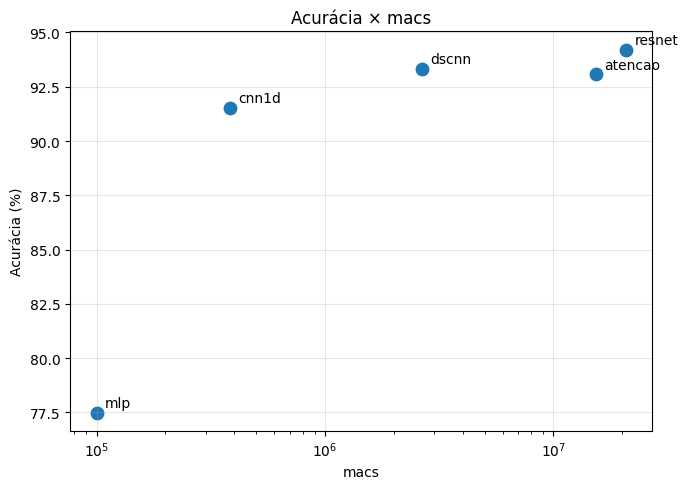

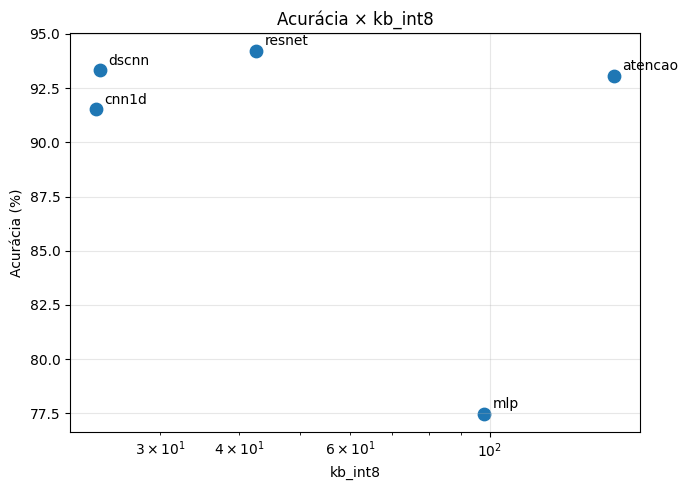

In [50]:
from avaliacao.graficos import acuracia_vs_custo

if len(resultados_gsc):
    acuracia_vs_custo(resultados_gsc, x="macs")
    acuracia_vs_custo(resultados_gsc, x="kb_int8")

**Resumo das 5 famílias** (§6, §4.1 e §7; teste com 3 seeds; da §5 à §9 cada família usa a configuração de
`hp_modelos`):

| Família | Entrada | Params | KB int8 | MACs | Acc teste (%) | F1 teste (%) | MFCC / rede (ms) | Pré-proc / rede |
|---|---|---|---|---|---|---|---|---|
| ResNet (res15-narrow) | 10 × 49 | 43.640 | 42,6 | 20,8 M | **94,21 ± 0,40** | 93,77 ± 0,42 | 0,52 / 3,71 | 0,14x |
| DS-CNN (64 canais) | 10 × 49 | 24.675 | 24,1 | 2,7 M | 93,33 ± 0,18 | 92,80 ± 0,18 | 0,51 / 1,57 | 0,33x |
| Atenção (KWT, d_model 64) | 40 × 101 | 161.443 | 157,7 | 15,3 M | 93,06 ± 0,62 | 92,43 ± 0,60 | 0,69 / 2,18 | 0,32x |
| CNN 1D (48 canais) | 10 × 49 | 24.275 | **23,7** | 0,38 M | 91,53 ± 0,69 | 90,81 ± 0,77 | 0,53 / 0,37 | 1,46x |
| MLP (3 × 128) | 10 × 49 | 100.387 | 98,0 | **0,10 M** | 77,48 ± 2,45 | 76,45 ± 2,71 | 0,51 / **0,12** | 4,44x |

- **(a):** quatro das cinco famílias passam de 91% nas 35 palavras. Três delas (ResNet, DS-CNN e CNN 1D) usam
  menos de 45 KB em int8; a Atenção usa 158 KB. A ResNet é a mais precisa, mas faz 54x os MACs da CNN 1D. A DS-CNN fica a −0,9 p.p. da ResNet com
  metade dos parâmetros e 1/8 dos MACs. O MLP fica muito atrás.
- **(b):** a resposta depende da família. No MLP e na CNN 1D o pré-processamento (MFCC + normalização) custa **mais**
  que a rede. Na DS-CNN, na Atenção e na ResNet (convoluções 2D ou atenção sobre o MFCC) a **rede** custa de 3 a 7x
  mais.
- Os vencedores da §8 do MLP (42 mil params), da DS-CNN (15 mil) e da Atenção (41 mil) ainda não estão nesta tabela.
  Com eles, a DS-CNN perderia −0,5 p.p. de validação e a Atenção −0,8 p.p., e as duas ficariam bem menores. No MLP
  o vencedor perderia −6,1 p.p., porque o critério compara com o baseline 40 × 101, que é bem mais fraco que o
  `hello_edge` com 128 neurônios usado aqui.

## 10. Generalização

Os modelos treinados no GSC, testados **sem re-treino** fora da distribuição. Cada parte baixa o seu dataset na
primeira vez e tem um flag na §2.

### 10.1 Ruído real (DEMAND)

O DEMAND é **ruído ambiente** (cozinha, escritório, trânsito, metrô...), misturado aos áudios de teste em vários
níveis de SNR: 20 dB = quase imperceptível, 0 dB = mesma potência da fala, −5 dB = ruído mais forte que a fala.
Nenhum modelo vê ruído no treino.

In [51]:
import random
from dados.ruido import carregar_demand
from avaliacao import avaliar_ruido
from avaliacao.graficos import curvas_ruido

if RODAR_RUIDO and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "demand",
                    "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
    ruidos = carregar_demand(PASTAS["dados"] / "demand")
    print("ambientes:", list(ruidos))

    #3.000 áudios de teste (subamostra para caber no tempo; aumentar na versão final)
    amostra = random.Random(0).sample(split["teste"], 3000)
    wavs = [ler_trecho(RAIZ_GSC, rel) for rel in amostra]
    y = torch.tensor([rotulo(rel, hyperparameters["tarefa"]) for rel in amostra])

    snrs = hp_base["snrs_db"]
    #Cada modelo com a SUA entrada (MFCC e normalização do seu config)
    modelos_seed0 = {nome: dict(model=rodadas[0][1], **entradas[nome]) for nome, rodadas in treinados.items()}
    res_ruido = avaliar_ruido(modelos_seed0, wavs, y, ruidos, snrs)
    curvas_ruido(res_ruido, snrs)
else:
    print("[pulando] §10.1: RODAR_RUIDO=False ou nenhum modelo treinado")

[pulando] §10.1: RODAR_RUIDO=False ou nenhum modelo treinado


### 10.2 AudioMNIST

Dígitos 0–9 de 60 falantes (57 não nativos de inglês), outra sala e outro microfone. Avaliado de duas formas:
com as 35 classes e restrito aos 10 dígitos. Precisa da tarefa `gsc35`.

In [52]:
from dados.audiomnist import listar_audiomnist, DIGITOS_EN
from avaliacao import logits_de_wavs

from dados import CLASSES_GSC, ler_audio

if hyperparameters["tarefa"] != "gsc35":
    print("[pulando] §10.2: o AudioMNIST precisa da tarefa gsc35 (os dígitos não estão na gsc12)")
elif RODAR_AUDIOMNIST and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "audiomnist",
                    "--destino", str(PASTAS["dados"])], check=True)
    arquivos, rotulos = listar_audiomnist(PASTAS["dados"] / "audiomnist", por_falante=100)
    wavs_am = [ler_audio(f) for f in arquivos]
    y_am = torch.tensor(rotulos)
    idx_digitos = torch.tensor([CLASSES_GSC.index(d) for d in DIGITOS_EN])
    print(len(wavs_am), "áudios")

    linhas = []
    for nome, rodadas in treinados.items():
        L = logits_de_wavs(rodadas[0][1], wavs_am, **entradas[nome])
        linhas.append(dict(modelo=nome,
                           acc_35_classes=(L.argmax(1) == idx_digitos[y_am]).float().mean().item(),
                           acc_so_digitos=(L[:, idx_digitos].argmax(1) == y_am).float().mean().item()))
    display(pd.DataFrame(linhas).round(4))
else:
    print("[pulando] §10.2: RODAR_AUDIOMNIST=False ou nenhum modelo treinado")

[pulando] §10.2: RODAR_AUDIOMNIST=False ou nenhum modelo treinado


### 10.3 MSWC-pt

Palavras em **português**. Dois testes: o modelo em inglês acerta o equivalente (*sim → yes*, *cima → up*)?
E, congelando a rede e treinando só a `head`, as features aprendidas em inglês servem para o português?
Precisa da tarefa `gsc35`.

In [53]:
from dados.mswc_pt import PT2EN, listar_mswc_pt, avaliar_cabeca_linear

if hyperparameters["tarefa"] != "gsc35":
    print("[pulando] §10.3: o MSWC-pt precisa da tarefa gsc35 (o mapeamento PT -> EN usa dígitos)")
elif RODAR_MSWC and treinados:
    subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "mswc",
                    "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
    palavras, arquivos, rotulos = listar_mswc_pt(PASTAS["dados"] / "mswc" / "pt" / "clips")
    print("palavras usadas:", palavras, "| acaso =", f"{100/len(palavras):.1f}%")
    wavs_pt = [ler_audio(f) for f in arquivos]
    y_pt = torch.tensor(rotulos)
    idx_en = torch.tensor([CLASSES_GSC.index(PT2EN[w]) for w in palavras])

    linhas = []
    for nome, rodadas in treinados.items():
        L = logits_de_wavs(rodadas[0][1], wavs_pt, **entradas[nome])
        linha = dict(modelo=nome, zero_shot_mapeado=(L[:, idx_en].argmax(1) == y_pt).float().mean().item())
        try:
            linha.update(avaliar_cabeca_linear(rodadas[0][1], wavs_pt, y_pt))
        except NotImplementedError as e:
            print(f"[a fazer] {e}")
        linhas.append(linha)
    display(pd.DataFrame(linhas).round(4))
else:
    print("[pulando] §10.3: RODAR_MSWC=False ou nenhum modelo treinado")

[pulando] §10.3: RODAR_MSWC=False ou nenhum modelo treinado


## 11. Conclusões

*Rascunho, a revisar pela equipe.*

**Hipótese (a):** é possível encolher essas arquiteturas clássicas e ainda assim manter um reconhecimento
de voz funcional?

**Sim, para as famílias com estrutura (convolução ou atenção).** Nas 35 palavras do GSC v2:
- a ResNet res15-narrow chega a 94,2% no teste com 43,6 mil parâmetros (42,6 KB em int8);
- a DS-CNN chega a 93,3% com 24,7 mil (24,1 KB); o vencedor da §8.4, com 15,4 mil, perde só −0,9 p.p. na validação;
- a CNN 1D chega a 91,5% com 24,3 mil (23,7 KB) e só 383 mil MACs. Ela e a DS-CNN cabem até nos 32 KB de um
  Arduino Uno (§6.1).

A entrada `hello_edge` (10 × 49, 8x menor) custou no máximo ~1,5 p.p. (res8, no playground da ResNet), quase nada na
CNN 1D, na DS-CNN e na Atenção, e no MLP até melhorou. A largura tem um limite claro: com 16 canais (ou d_model 16) a
acurácia despenca. O MLP é a exceção: sem noção de
tempo, fica em ~77–79%. Encolher não é o problema dele, a arquitetura é que não serve para a tarefa.

**Hipótese (b):** em modelos tão pequenos, o que consome mais recursos, o pré-processamento do áudio
(MFCC) ou a inferência da rede?

**Depende da família, e a fronteira é o tipo de operação, não o número de parâmetros** (CPU, 1 thread, batch 1):
- no **MLP** (4,4x) e na **CNN 1D** (1,5x), o MFCC + normalização (~0,5 ms) custa **mais** que a rede. Encolher
  ainda mais a rede quase não reduz a latência total; o próximo ganho viria do pré-processamento;
- na **DS-CNN** (0,33x), na **Atenção** (0,32x) e na **ResNet** (0,14x), a **rede** domina (1,6 a 3,7 ms). A ResNet
  vencedora tem menos parâmetros que o res8, mas sem pooling na entrada faz 20,8 M de MACs.

**Limitações:**
- **Early stop:** teto de 50 épocas e paciência de 5. Alguns treinos chegaram ao teto ainda melhorando, e a paciência
  curta aumenta a variação entre treinos (§5).
- **Vencedores não aplicados:** no MLP, na DS-CNN e na Atenção, os vencedores da §8 não foram aplicados à §5–§9.
- **CNN 1D e ResNet:** só o baseline e o vencedor rodaram com o early stop; as demais configurações vêm dos
  playgrounds (20 épocas, OneCycle).
- **Latência:** foi medida numa CPU x86 do Colab, não num microcontrolador.

## Referências

- ZHANG, Y. et al. **Hello Edge: Keyword Spotting on Microcontrollers.** arXiv:1711.07128, 2017.
- KIM, B. et al. **Broadcasted Residual Learning for Efficient Keyword Spotting (BC-ResNet).** arXiv:2106.04140, 2021.
- BERG, A. et al. **Keyword Transformer: A Self-Attention Model for Keyword Spotting.** arXiv:2104.00769, 2021.
- TANG, R.; LIN, J. **Deep Residual Learning for Small-Footprint Keyword Spotting.** ICASSP 2018.
- WARDEN, P. **Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition.** arXiv:1804.03209, 2018.
- HE, K. et al. **Deep Residual Learning for Image Recognition.** CVPR 2016.
- VASWANI, A. et al. **Attention Is All You Need.** NeurIPS 2017.
- BENGIO, Y. et al. **A Neural Probabilistic Language Model.** JMLR 2003.
- BETTER STACK. **Speech Recognition Without the Internet Now Fits on a $10 Chip (Whistle).** YouTube, 2026.
- GOBIESKI, G.; LUCIA, B.; BECKMANN, N. **Intelligence Beyond the Edge: Inference on Intermittent Embedded Systems.** ASPLOS 2019.
- WARDEN, P.; SITUNAYAKE, D. **TinyML: Machine Learning with TensorFlow Lite on Arduino and Ultra-Low-Power Microcontrollers.** O'Reilly, 2019.
- Datasheets dos microcontroladores da §6.1: Microchip ATmega328P, TI MSP430FR599x, Nordic nRF52840, Espressif ESP32-WROOM-32.

Lista completa em [`docs/referencias.md`](https://github.com/gpeuzinCosta/kws-borda/blob/main/docs/referencias.md).